# Figure reproduction from bundled source data

This notebook displays the main figures (1–6) and supplementary figures (S1–S9) represented by the bundled PDFs, using bundled source data. Figures are displayed inline with plt.show(); no figure or table files are written. It preserves the source plotting styles and does not add panel letters. Inputs are resolved through input_manifest.csv.


In [451]:
from __future__ import annotations
from pathlib import Path
import csv
import json
import warnings
import json as _json
from typing import Optional
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch, Rectangle
import geopandas as gpd
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter
from scipy.stats import friedmanchisquare, spearmanr, wilcoxon
import argparse
import matplotlib
from matplotlib.patches import Rectangle
from scipy.stats import t as student_t
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
from statsmodels.stats.multitest import multipletests
from itertools import combinations
from scipy.stats import kruskal, mannwhitneyu
from scipy.stats import pearsonr
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import Normalize
from IPython.display import display
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency, fisher_exact
import re

BUNDLE_DIR = Path.cwd()
if not (BUNDLE_DIR / "input_manifest.csv").exists():
    BUNDLE_DIR = Path("/data/zhangl/coinfection/codemulti_cleaned_data_ai/rti_plot_ai/github")
BUNDLE_OUTPUT_ROOT = BUNDLE_DIR / "rendered_figures"
MANIFEST = list(csv.DictReader((BUNDLE_DIR / "input_manifest.csv").open(encoding="utf-8-sig")))
ACTIVE_FIGURE_LABEL = None

def input_for(project_path, figure_label=None):
    key = str(project_path).replace("\\", "/")
    alternatives = [key]
    if key.startswith("rti_plot_ai/"): 
        alternatives.append(key[len("rti_plot_ai/"):])
    else: 
        alternatives.append("rti_plot_ai/" + key)
    matches = [r for r in MANIFEST if r["original_project_path"].replace("\\", "/") in alternatives]
    label = figure_label or ACTIVE_FIGURE_LABEL
    if label:
        preferred = [r for r in matches if r["figure_label"] == label]
        if preferred: 
            matches = preferred
    if not matches: 
        raise FileNotFoundError(f"Input is not bundled in input_manifest.csv: {key}")
    return BUNDLE_DIR / matches[0]["bundle_path"]

class BundleDirectory:
    def __init__(self, project_dir, figure_label=None):
        self.project_dir = str(project_dir).replace("\\", "/").strip("/")
        self.figure_label = figure_label
    def __truediv__(self, child):
        key = f"{self.project_dir}/{child}"
        try: 
            return input_for(key, self.figure_label)
        except FileNotFoundError: 
            return BundleDirectory(key, self.figure_label)
    def exists(self):
        return any(r["original_project_path"].replace("\\", "/").startswith(self.project_dir + "/") for r in MANIFEST)

def output_dir(label):
    path = BUNDLE_OUTPUT_ROOT / label
    return path

# Plot helpers and style settings copied from rti_plot_ai/plot_paper.ipynb.

warnings.filterwarnings('ignore')

try:
    display
except NameError:
    def display(obj):
        print(obj)

BASE_DIR = BUNDLE_DIR
OUT_DIR = output_dir('Figure_2')
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 14,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'axes.titleweight': 'normal',
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 18,
    'figure.dpi': 120,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
    'xtick.major.size': 4.5,
    'ytick.major.size': 4.5,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})
sns.set_theme(style='white', rc={
    'font.family': 'Arial',
    'font.size': 14,
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
})
NATURE_COLORS = ['#3B6FB6', '#D64F45', '#2C9A66', '#8E6BBE', '#E69F00', '#56B4E9', '#7F7F7F', '#CC79A7']
figure1a_type_colors = {'Virus': NATURE_COLORS[0], 'Atypical': NATURE_COLORS[3], 'Bacteria': NATURE_COLORS[1], 'Fungi': NATURE_COLORS[2], 'Other': NATURE_COLORS[6]}
FAMILY_COLORS = {
    'Viral': '#3B6FB6',
    'Bacterial': '#D64F45',
    'Fungi': '#2C9A66',
    'Viral pathogens': '#3B6FB6',
    'Bacterial pathogens': '#D64F45',
    'Fungi pathogens': '#2C9A66',
}
MISSING_PATCH = Patch(facecolor='#F2F2F2', edgecolor='#D8D8D8', hatch='..', label='Missing')

VIRUS_ORDER = ['CMV', 'SARS-CoV-2', 'EBV', 'HAdV', 'HBoV', 'HCoV', 'HMPV', 'HPIV', 'HRV', 'HSV', 'IFV', 'RSV']
BACTERIA_ORDER = ['MP', 'CP', 'B pertussis', 'H influenzae', 'K pneumoniae', 'Legionella', 'M catarrhalis', 'MTB', 'P aeruginosa', 'S aureus', 'S maltophilia', 'S pneumoniae', 'A baumannii']
FUNGI_ORDER = ['Aspergillus', 'Candida', 'Cryptococcus', 'Pneumocystis']
PATHOGEN_DISPLAY_ORDER = VIRUS_ORDER + BACTERIA_ORDER + FUNGI_ORDER

PATHOGEN_NAME_REPLACEMENTS = {
    'COVID-19': 'SARS-CoV-2',
    'SARS-COV-2': 'SARS-CoV-2',
    'Mycobacterium tuberculosis': 'MTB',
    'M. tuberculosis': 'MTB',
    'M tuberculosis': 'MTB',
    'B. pertussis': 'B pertussis',
    'H. influenzae': 'H influenzae',
    'K. pneumoniae': 'K pneumoniae',
    'M. catarrhalis': 'M catarrhalis',
    'P. aeruginosa': 'P aeruginosa',
    'S. aureus': 'S aureus',
    'S. maltophilia': 'S maltophilia',
    'S. pneumoniae': 'S pneumoniae',
    'A. baumannii': 'A baumannii',
}

def normalize_pathogen_text(value):
    if not isinstance(value, str):
        return value
    out = value
    for old, new in PATHOGEN_NAME_REPLACEMENTS.items():
        out = out.replace(old, new)
    return out

def normalize_pathogen_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out = out.rename(
        index=lambda x: normalize_pathogen_text(x),
        columns=lambda x: normalize_pathogen_text(x),
    )
    object_cols = out.select_dtypes(include=['object', 'string']).columns
    for col in object_cols:
        out[col] = out[col].map(normalize_pathogen_text)
    return out

BACTERIA_ITALIC_LABELS = {'B pertussis', 'H influenzae', 'K pneumoniae', 'Legionella', 'M catarrhalis', 'P aeruginosa', 'S aureus', 'S maltophilia', 'S pneumoniae', 'A baumannii'}

def format_global_test_label(global_test: dict) -> str:
    if not global_test:
        return ''
    method = str(global_test.get('test_method', '')).strip()
    p_value = global_test.get('global_p_value', np.nan)
    n_pairs = global_test.get('complete_pair_count', np.nan)
    pieces = [method, format_p(p_value)] if method else [format_p(p_value)]
    if pd.notna(n_pairs):
        pieces.append(f'n={int(n_pairs)}')
    return ', '.join([piece for piece in pieces if piece])

def build_group_pair_matrix(value_df: pd.DataFrame, group_order: list[str], value_col: str) -> pd.DataFrame:
    if value_df.empty:
        return pd.DataFrame(columns=group_order)
    return (
        value_df.pivot_table(index='Pair label', columns='Group', values=value_col, aggfunc='first')
        .reindex(columns=[g for g in group_order if g in set(value_df['Group'])])
    )

def add_complete_across_groups_flag(value_df: pd.DataFrame, group_order: list[str], value_col: str) -> pd.DataFrame:
    out = value_df.copy()
    if 'Complete across groups' in out.columns:
        out['Complete across groups'] = out['Complete across groups'].astype(str).str.lower().isin(['true', '1', 'yes'])
        return out
    wide_df = build_group_pair_matrix(out, group_order, value_col)
    actual_groups = [g for g in group_order if g in wide_df.columns]
    complete_pairs = set(wide_df[actual_groups].dropna().index) if len(actual_groups) >= 2 else set(wide_df.dropna().index)
    out['Complete across groups'] = out['Pair label'].isin(complete_pairs)
    return out

def compute_median_sorted_groups(value_df: pd.DataFrame, fallback_order: list[str], value_col: str) -> list[str]:
    if value_df.empty:
        return []
    fallback_rank = {group: idx for idx, group in enumerate(fallback_order)}
    summary = value_df.groupby('Group', as_index=False)[value_col].median().rename(columns={value_col: 'median_value'})
    summary['fallback_rank'] = summary['Group'].map(lambda x: fallback_rank.get(x, 10**9))
    summary = summary.sort_values(['median_value', 'fallback_rank'], ascending=[False, True]).reset_index(drop=True)
    return summary['Group'].tolist()

def build_ordered_significance_letters(value_df: pd.DataFrame, pairwise_star_matrix_df: pd.DataFrame, group_order: list[str], value_col: str) -> dict[str, str]:
    if value_df.empty:
        return {}
    sorted_groups = compute_median_sorted_groups(value_df, group_order, value_col)
    if not sorted_groups:
        return {}
    if pairwise_star_matrix_df is None or pairwise_star_matrix_df.empty:
        return {group: 'a' for group in sorted_groups}

    def is_significant(group_a: str, group_b: str) -> bool:
        if group_a == group_b:
            return False
        if group_a not in pairwise_star_matrix_df.index or group_b not in pairwise_star_matrix_df.columns:
            return False
        stars = str(pairwise_star_matrix_df.loc[group_a, group_b]).strip()
        return stars in {'*', '**', '***'}

    labels = {group: [] for group in sorted_groups}
    max_letters_per_group = 2

    def letter_name(idx: int) -> str:
        return chr(ord('a') + idx) if idx < 26 else f'L{idx + 1}'

    def add_letter(group: str, letter: str):
        if letter not in labels[group] and len(labels[group]) < max_letters_per_group:
            labels[group].append(letter)

    anchor_pos = 0
    letter_idx = 0
    while anchor_pos < len(sorted_groups):
        letter = letter_name(letter_idx)
        anchor_group = sorted_groups[anchor_pos]
        add_letter(anchor_group, letter)
        for upper_group in sorted_groups[:anchor_pos]:
            if not is_significant(anchor_group, upper_group):
                add_letter(upper_group, letter)
        next_anchor_pos = None
        for pos in range(anchor_pos + 1, len(sorted_groups)):
            lower_group = sorted_groups[pos]
            if is_significant(anchor_group, lower_group):
                next_anchor_pos = pos
                break
            add_letter(lower_group, letter)
        if next_anchor_pos is None:
            break
        anchor_pos = next_anchor_pos
        letter_idx += 1

    for pos, group in enumerate(sorted_groups):
        if not labels[group]:
            add_letter(group, letter_name(min(pos, 25)))
    return {group: ''.join(labels[group][:max_letters_per_group]) for group in sorted_groups}

def rel(path: str):
    key = 'rti_plot_ai/' + str(path).strip('/')
    try:
        return input_for(key, ACTIVE_FIGURE_LABEL)
    except FileNotFoundError:
        return BundleDirectory(key, ACTIVE_FIGURE_LABEL)

def nature_axes(ax, grid_axis: Optional[str] = 'y'):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.0)
    ax.spines['bottom'].set_linewidth(1.0)
    ax.tick_params(axis='both', labelsize=14, width=1.0, length=4.5)
    if grid_axis:
        ax.grid(axis=grid_axis, color='#E6E6E6', linewidth=0.7)
        ax.set_axisbelow(True)
    return ax

def style_colorbar(cbar, label: Optional[str] = None):
    if cbar is None:
        return
    if label:
        cbar.set_label(label, fontsize=12)
    cbar.ax.tick_params(labelsize=18, width=0.8, length=3.5)

def add_missing_legend(ax):
    ax.legend(
        handles=[MISSING_PATCH],
        loc='upper left',
        bbox_to_anchor=(1.02, 1),
        frameon=False,
        fontsize=18,
        handlelength=2.6,
        handleheight=2.1,
        borderaxespad=0.0,
    )

def draw_missing_hatch(ax, missing_mask: pd.DataFrame, visible_mask: Optional[object] = None):
    if visible_mask is None:
        visible_mask = pd.DataFrame(True, index=missing_mask.index, columns=missing_mask.columns)
    if not isinstance(visible_mask, pd.DataFrame):
        visible_mask = pd.DataFrame(visible_mask, index=missing_mask.index, columns=missing_mask.columns)
    for i in range(missing_mask.shape[0]):
        for j in range(missing_mask.shape[1]):
            if bool(missing_mask.iloc[i, j]) and bool(visible_mask.iloc[i, j]):
                ax.add_patch(Rectangle((j, i), 1, 1, facecolor='#F2F2F2', edgecolor='#D8D8D8', hatch='..', linewidth=0.25))

def repel_texts(ax, texts, max_iter: int = 120, step: float = 6.0):
    if not texts:
        return
    fig = ax.figure
    renderer = fig.canvas.get_renderer()
    for _ in range(max_iter):
        fig.canvas.draw()
        bboxes = [text.get_window_extent(renderer=renderer).expanded(1.04, 1.12) for text in texts]
        moved = False
        for i in range(len(texts)):
            for j in range(i + 1, len(texts)):
                if not bboxes[i].overlaps(bboxes[j]):
                    continue
                c1 = bboxes[i].get_points().mean(axis=0)
                c2 = bboxes[j].get_points().mean(axis=0)
                direction = c2 - c1
                if np.allclose(direction, 0):
                    direction = np.array([1.0, 1.0])
                direction = direction / np.linalg.norm(direction)
                x, y = texts[j].get_position()
                disp = texts[j].get_transform().transform((x, y)) + direction * step
                texts[j].set_position(texts[j].get_transform().inverted().transform(disp))
                moved = True
        if not moved:
            break

def format_p(p):
    if pd.isna(p):
        return 'p=NA'
    if p < 0.0001:
        return 'p<0.0001'
    return f'p={p:.2g}'

def p_stars(p):
    if pd.isna(p):
        return ''
    if p < 0.001:
        return '***'
    if p < 0.01:
        return '**'
    if p < 0.05:
        return '*'
    return ''

PATHOGEN_MAPPING_PATH = input_for('rti_plot_ai/01_population_level_times/pathogen_name_mapping.csv', 'Figure_S2')
if PATHOGEN_MAPPING_PATH.exists():
    _mapping_df = normalize_pathogen_dataframe(pd.read_csv(PATHOGEN_MAPPING_PATH))
    _mapping_df['Abbreviation'] = _mapping_df['Abbreviation'].map(normalize_pathogen_text)
    PATHOGEN_FAMILY_MAP = dict(zip(_mapping_df['Abbreviation'].astype(str), _mapping_df['Family'].astype(str)))
else:
    PATHOGEN_FAMILY_MAP = {}

def pathogen_family_short(pathogen: str) -> str:
    alias_family = {'M. tuberculosis': 'Bacterial', 'Mycobacterium tuberculosis': 'Bacterial', 'MTB': 'Bacterial'}
    family = alias_family.get(str(pathogen), PATHOGEN_FAMILY_MAP.get(str(pathogen), 'Other'))
    if family in {'Viral', 'Bacterial', 'Fungi'}:
        return family
    if family.startswith('Viral'):
        return 'Viral'
    if family.startswith('Bacterial'):
        return 'Bacterial'
    if family.startswith('Fungi'):
        return 'Fungi'
    return 'Other'



### Figure_1 · monthly positive detections


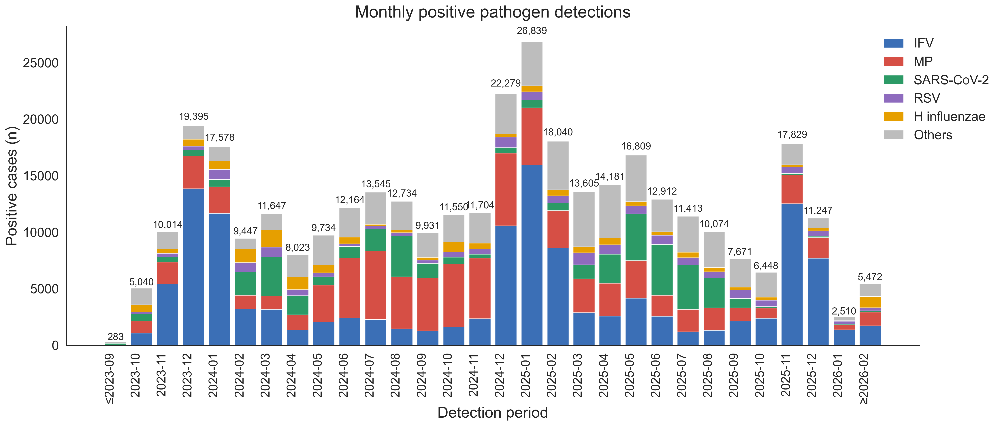

In [452]:
ACTIVE_FIGURE_LABEL = 'Figure_1'
OUT_DIR = output_dir('Figure_1')
monthly_counts_path = input_for('rti_plot_ai/figure_sup/figure_sup_monthly_pathogen_positive_cases_counts.csv', 'Figure_1')
period_positive_cases = pd.read_csv(monthly_counts_path, index_col=0)
if 'Total' in period_positive_cases.columns: 
    period_positive_cases = period_positive_cases.drop(columns='Total')
period_positive_cases = period_positive_cases.apply(pd.to_numeric, errors='coerce').fillna(0)
top_five = period_positive_cases.sum().sort_values(ascending=False).head(5).index.tolist()
plot_df = period_positive_cases[top_five].copy()
plot_df['Others'] = period_positive_cases.drop(columns=top_five).sum(axis=1)
fig, ax = plt.subplots(figsize=(22, 8), dpi=300)
x = np.arange(len(plot_df))
bottom = np.zeros(len(plot_df), dtype=float)
bar_colors = {pathogen: NATURE_COLORS[i] for i, pathogen in enumerate(top_five)}
bar_colors['Others'] = '#BDBDBD'
display_names = {pathogen: normalize_pathogen_text(pathogen) for pathogen in top_five}
for pathogen in top_five + ['Others']:
    values = plot_df[pathogen].to_numpy(dtype=float)
    ax.bar(x, values, bottom=bottom, width=0.82, color=bar_colors[pathogen], edgecolor='white', linewidth=0.35, label=display_names.get(pathogen, pathogen))
    bottom += values
for i, total in enumerate(bottom): 
    ax.text(i, total * 1.02, f'{int(total):,}', ha='center', va='bottom', fontsize=13)
ax.set_title('Monthly positive pathogen detections', fontsize=22, pad=12)
ax.set_ylabel('Positive cases (n)', fontsize=20)
ax.set_xlabel('Detection period', fontsize=20)
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index.astype(str), rotation=90, ha='right', fontsize=16)
ax.tick_params(axis='y', labelsize=17)
ax.grid(axis='y', color='#E6E6E6', linewidth=0)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='upper center', bbox_to_anchor=(1.02, 1.0), ncol=1, frameon=False, fontsize=17, handlelength=1.5, columnspacing=1.5)
fig.tight_layout(rect=[0, 0, 0.84, 1])
plt.show()


### Figure_1 · panel B: observed co-detection rates

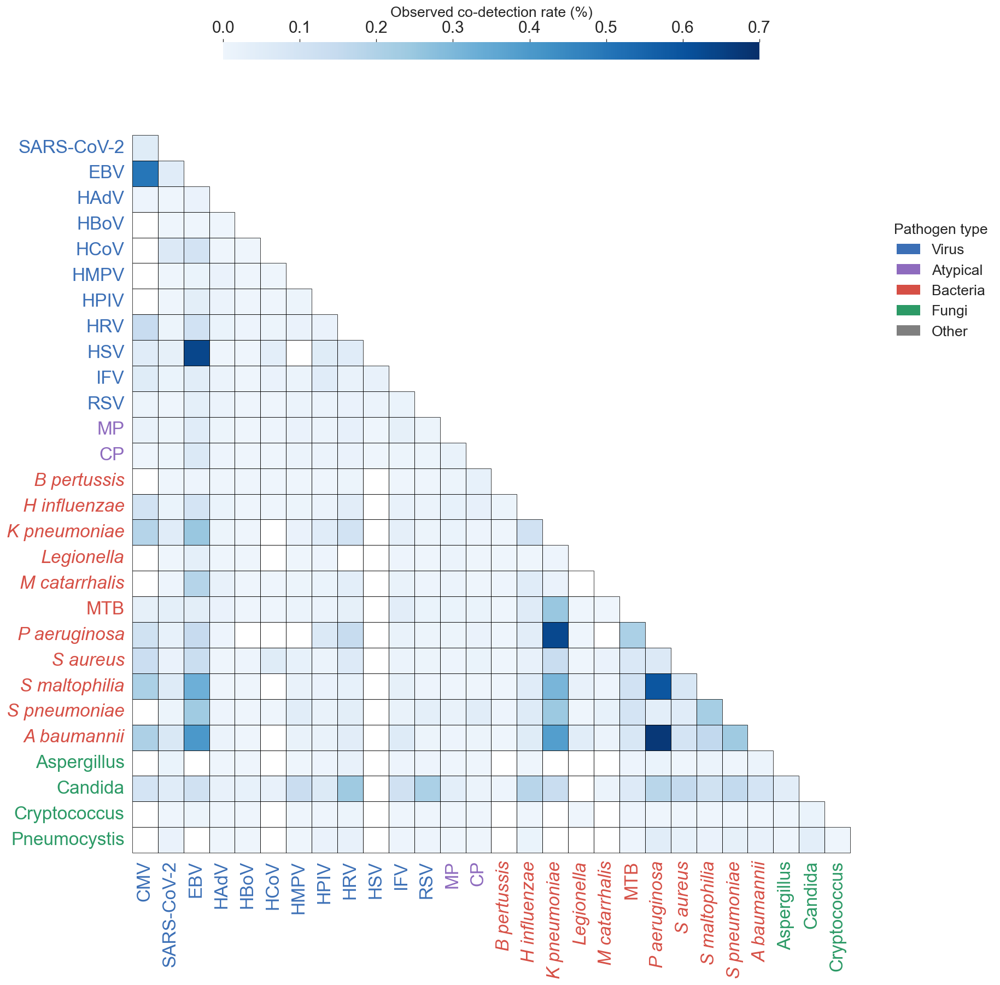

In [453]:
ACTIVE_FIGURE_LABEL = 'Figure_1'
obs_rate_matrix = normalize_pathogen_dataframe(pd.read_csv(rel('02_population_inte/month/all_pathogen_observed_coinfection_rate_matrix.csv'), index_col=0))

obs_matrix_float = obs_rate_matrix.astype(float).copy()
obs_plot_matrix = obs_matrix_float.replace([np.inf, -np.inf], np.nan)
obs_missing_mask = obs_matrix_float.isna() | obs_plot_matrix.isna() | np.isinf(obs_plot_matrix)

desired_order = PATHOGEN_DISPLAY_ORDER

obs_upper_triangle_mask = pd.DataFrame(np.triu(np.ones(obs_plot_matrix.shape, dtype=bool), k=0), index=obs_plot_matrix.index, columns=obs_plot_matrix.columns)
obs_lower_triangle_mask = ~obs_upper_triangle_mask

obs_valid_lower = obs_lower_triangle_mask & (~obs_missing_mask)

obs_keep_pathogens = obs_plot_matrix.index[obs_valid_lower.any(axis=1) | obs_valid_lower.any(axis=0)]

obs_ordered_pathogens = [p for p in desired_order if p in obs_keep_pathogens]
obs_ordered_pathogens += [p for p in obs_keep_pathogens if p not in obs_ordered_pathogens]

obs_plot_matrix = obs_plot_matrix.loc[obs_ordered_pathogens, obs_ordered_pathogens]
obs_matrix_float = obs_matrix_float.loc[obs_ordered_pathogens, obs_ordered_pathogens]
obs_missing_mask = obs_missing_mask.loc[obs_ordered_pathogens, obs_ordered_pathogens]

obs_all_pathogens = obs_plot_matrix.index.tolist()

obs_row_labels = obs_all_pathogens[1:]
obs_col_labels = obs_all_pathogens[:-1]

obs_plot_matrix = obs_plot_matrix.loc[obs_row_labels, obs_col_labels]
obs_matrix_float = obs_matrix_float.loc[obs_row_labels, obs_col_labels]
obs_missing_mask = obs_missing_mask.loc[obs_row_labels, obs_col_labels]

obs_pathogen_pos = pd.Series(np.arange(len(obs_all_pathogens)), index=obs_all_pathogens)

obs_row_pos = obs_pathogen_pos.loc[obs_row_labels].to_numpy()
obs_col_pos = obs_pathogen_pos.loc[obs_col_labels].to_numpy()

obs_lower_triangle_mask = pd.DataFrame(obs_row_pos[:, None] > obs_col_pos[None, :], index=obs_row_labels, columns=obs_col_labels)

obs_heatmap_mask = (~obs_lower_triangle_mask) | obs_missing_mask

# color mapping: 0保持蓝色，不使用接近白色区域
obs_cmap = LinearSegmentedColormap.from_list(
    'custom_Blues',
    plt.cm.Blues(np.linspace(0.05, 1, 256))
)
vmin = 0.0
vmax = 0.7
fig_size = max(10, 18)
fig, ax = plt.subplots(figsize=(fig_size, fig_size * 0.92))
ax.set_facecolor('white')
sns.heatmap(
    obs_plot_matrix,
    mask=obs_heatmap_mask,
    cmap=obs_cmap,
    vmin=vmin,
    vmax=vmax,
    linewidths=0,
    linecolor='white',
    square=True,
    cbar_kws={'shrink':0.6, 'pad':0.08, 'aspect':30, 'orientation':'horizontal', 'location':'top'},
    ax=ax
)

# colorbar刻度从0.05开始显示
cbar = ax.collections[0].colorbar

style_colorbar(cbar)
cbar.ax.set_title('Observed co-detection rate (%)', fontsize=16, pad=4)

for i in range(obs_plot_matrix.shape[0]):
    for j in range(obs_plot_matrix.shape[1]):
        if obs_lower_triangle_mask.iloc[i,j] and obs_missing_mask.iloc[i,j]:
            ax.add_patch(Rectangle((j,i),1,1,facecolor='white',edgecolor='none',zorder=2))
        if obs_lower_triangle_mask.iloc[i,j]:
            ax.add_patch(Rectangle((j,i),1,1,facecolor='none',edgecolor='black',linewidth=0.45,zorder=3))

margin = 0.02

ax.set_xlim(-margin, obs_plot_matrix.shape[1]+margin)
ax.set_ylim(obs_plot_matrix.shape[0]+margin,-margin)

ax.set_xlabel('')
ax.set_ylabel('')

plt.setp(ax.get_xticklabels(), rotation=90, ha='center', va='top', fontsize=20)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=20)

for label in ax.get_xticklabels():
    if label.get_text() in BACTERIA_ITALIC_LABELS:
        label.set_fontstyle('italic')

for label in ax.get_yticklabels():
    if label.get_text() in BACTERIA_ITALIC_LABELS:
        label.set_fontstyle('italic')

ax.tick_params(axis='x', pad=2)
ax.tick_params(axis='y', pad=2)

figure1a_type_colors = {
    'Virus': NATURE_COLORS[0],
    'Atypical': NATURE_COLORS[3],
    'Bacteria': NATURE_COLORS[1],
    'Fungi': NATURE_COLORS[2],
    'Other': NATURE_COLORS[6],
}

pathogen_label_colors = {p:figure1a_type_colors['Virus'] for p in VIRUS_ORDER}
pathogen_label_colors.update({p:figure1a_type_colors['Atypical'] for p in ['MP','CP']})
pathogen_label_colors.update({p:figure1a_type_colors['Bacteria'] for p in BACTERIA_ORDER if p not in ['MP','CP']})
pathogen_label_colors['MTB'] = figure1a_type_colors['Bacteria']
pathogen_label_colors.update({p:figure1a_type_colors['Fungi'] for p in FUNGI_ORDER})

for label in ax.get_xticklabels():
    label.set_color(pathogen_label_colors.get(label.get_text(),figure1a_type_colors['Other']))

for label in ax.get_yticklabels():
    label.set_color(pathogen_label_colors.get(label.get_text(),figure1a_type_colors['Other']))

fig.legend(
    handles=[Patch(facecolor=color,edgecolor='none',label=ptype) for ptype,color in figure1a_type_colors.items()],
    title='Pathogen type',
    loc='upper left',
    bbox_to_anchor=(0.72,0.72),
    frameon=False,
    fontsize=16,
    title_fontsize=16,
    handlelength=1.6,
)

fig.tight_layout(rect=[0, 0, 0.78, 1])

plt.show()

### Figure_1 · panel C: leading pairs in children and older adults

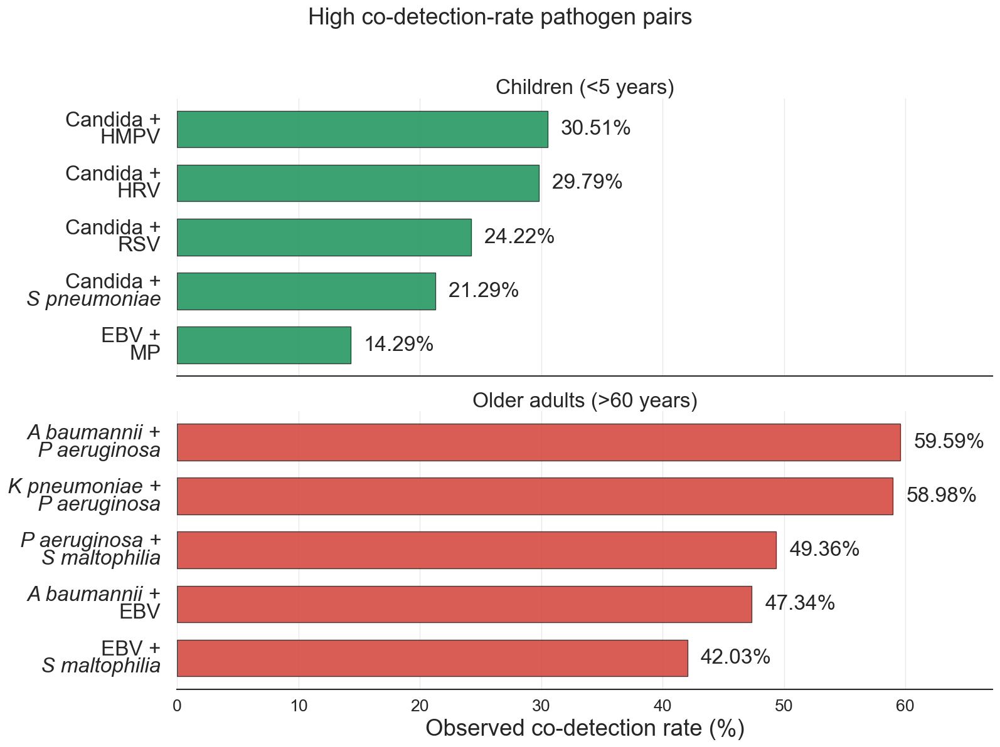

In [454]:
ACTIVE_FIGURE_LABEL = 'Figure_1'
# Figure 1C: top observed co-detection-rate pairs in children and older adults.
# Rate = both-positive encounters / encounters in which both pathogens were tested.
# The PDF shows the child and older-adult strata only.
# Keep PDF text as embedded TrueType text objects for downstream editing.
plt.rcParams.update({
    'font.family': 'Arial',
    'font.sans-serif': ['Arial'],
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})
OBSERVED_MIN_BOTH_TESTED = 100
TOP_COINFECTION_CSV = rel('10_top_coinfections/10_top_coinfection_count.csv')
top_coinfection_df = pd.read_csv(TOP_COINFECTION_CSV)

top_coinfection_df['Coinfection rate (%)'] = pd.to_numeric(
    top_coinfection_df['Coinfection rate (%)'], errors='coerce'
)
top_coinfection_df['Both tested n'] = pd.to_numeric(
    top_coinfection_df['Both tested n'], errors='coerce'
)
top_coinfection_df = top_coinfection_df.loc[
    top_coinfection_df['Both tested n'] > OBSERVED_MIN_BOTH_TESTED
].copy()

# The legacy summary may not yet contain the unknown-age stratum; merge its
# encounter-level summary generated from the same patient-window source.
UNKNOWN_TOP_COINFECTION_CSV = rel('plot_paper/11_unknown_age_top_co_detection_rate.csv')
if (
    not top_coinfection_df['Age section'].eq('Unknown').any()
    and UNKNOWN_TOP_COINFECTION_CSV.exists()
):
    top_coinfection_df = pd.concat([
        top_coinfection_df,
        pd.read_csv(UNKNOWN_TOP_COINFECTION_CSV),
    ], ignore_index=True)

plot_groups = [
    ('Children (<5 years)', 'Children (<5 years)', 5, NATURE_COLORS[2]),
    ('Older adults (>60 years)', 'Older adults (>60 years)', 5, NATURE_COLORS[1]),
]

BACTERIAL_PAIR_NAMES = [
    'B pertussis', 'H influenzae', 'K pneumoniae', 'Legionella',
    'M catarrhalis', 'MTB', 'P aeruginosa', 'S aureus',
    'S maltophilia', 'S pneumoniae', 'A baumannii',
]
BACTERIAL_PAIR_REPLACEMENTS = {}
for bacterial_name in BACTERIAL_PAIR_NAMES:
    BACTERIAL_PAIR_REPLACEMENTS[bacterial_name] = bacterial_name
    if ' ' in bacterial_name:
        genus, species = bacterial_name.split(' ', 1)
        BACTERIAL_PAIR_REPLACEMENTS[f'{genus}. {species}'] = bacterial_name
BACTERIAL_PAIR_REPLACEMENTS['M. tuberculosis'] = 'MTB'

def clean_pair_name(pair):
    label = str(pair)
    for old_name, display_name in sorted(BACTERIAL_PAIR_REPLACEMENTS.items(), key=lambda item: len(item[0]), reverse=True):
        label = label.replace(old_name, display_name)
    return ' + '.join(part.strip() for part in label.split('+', 1))

def format_pair_label_with_italic_bacteria(pair):
    pair_parts = clean_pair_name(pair).split(' + ', 1)
    return ' +\n'.join(pair_parts) if len(pair_parts) == 2 else pair_parts[0]

top_coinfection_df['Pair'] = top_coinfection_df['Pair'].map(clean_pair_name)

selected_frames = []
for age_section, display_title, top_n, color in plot_groups:
    selected = (
        top_coinfection_df.loc[
            (top_coinfection_df['Age section'] == age_section)
            & (top_coinfection_df['Panel'] == 'All')
        ]
        .sort_values(['Coinfection rate (%)', 'Coinfection n', 'Pair'], ascending=[False, False, True])
        .head(top_n)
        .copy()
    )
    selected['Group'] = display_title
    selected['Color'] = color
    selected_frames.append(selected)

top_coinfection_plot_df = pd.concat(selected_frames, ignore_index=True)
top_coinfection_plot_df['Pair display'] = top_coinfection_plot_df['Pair'].map(format_pair_label_with_italic_bacteria)
top_coinfection_plot_df['Has bacterial'] = top_coinfection_plot_df['Pair display'].map(
    lambda label: any(name in label for name in BACTERIA_ITALIC_LABELS)
)

fig, axes = plt.subplots(2, 1, figsize=(13.5, 10), sharex=True, squeeze=False)
axes = axes.ravel()
x_max = max(10, np.ceil(top_coinfection_plot_df['Coinfection rate (%)'].max() / 10) * 10)

for ax, (age_section, display_title, top_n, color) in zip(axes, plot_groups):
    sub = top_coinfection_plot_df.loc[top_coinfection_plot_df['Group'] == display_title].copy()
    sub = sub.sort_values('Coinfection rate (%)', ascending=True).reset_index(drop=True)
    y = np.arange(len(sub))
    bars = ax.barh(
        y, sub['Coinfection rate (%)'], color=color, alpha=0.92,
        edgecolor='#2F2F2F', linewidth=0.8, height=0.68
    )
    ax.set_yticks(y)
    ax.set_yticklabels([])
    for yi, (_, row) in zip(y, sub.iterrows()):
        pair_parts = clean_pair_name(row['Pair']).split(' + ', 1)
        for line_idx, part in enumerate(pair_parts):
            label = f'{part} +' if line_idx == 0 and len(pair_parts) == 2 else part
            ax.text(
                -0.02, yi + (0.16 if line_idx == 0 and len(pair_parts) == 2 else -0.16 if len(pair_parts) == 2 else 0),
                label, transform=ax.get_yaxis_transform(),
                ha='right', va='center', fontsize=20, fontname='Arial',
                fontstyle='italic' if part in BACTERIA_ITALIC_LABELS else 'normal',
                clip_on=False,
            )
    ax.set_xlim(0, x_max * 1.12)
    ax.grid(axis='x', color='#E6E6E6', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.tick_params(axis='x', labelsize=16)
    for tick_label in ax.get_xticklabels():
        tick_label.set_fontname('Arial')
    ax.set_title(display_title, fontsize=20, pad=4, fontname='Arial')
    for bar, (_, row) in zip(bars, sub.iterrows()):
        rate = row['Coinfection rate (%)']
        ax.text(
            rate + x_max * 0.018, bar.get_y() + bar.get_height() / 2,
            f'{rate:.2f}%', va='center', ha='left', fontsize=20, fontname='Arial'
        )

for ax in axes[len(plot_groups):]:
    ax.axis('off')

axes[len(plot_groups) - 1].set_xlabel('Observed co-detection rate (%)', fontsize=22, fontname='Arial')
fig.suptitle('High co-detection-rate pathogen pairs', fontsize=22, y=0.995, fontname='Arial')
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


In [455]:
ACTIVE_FIGURE_LABEL = 'Figure_2'
OUT_DIR = output_dir('Figure_2')


### Figure_2 · panel A: selected age and outcome comparisons


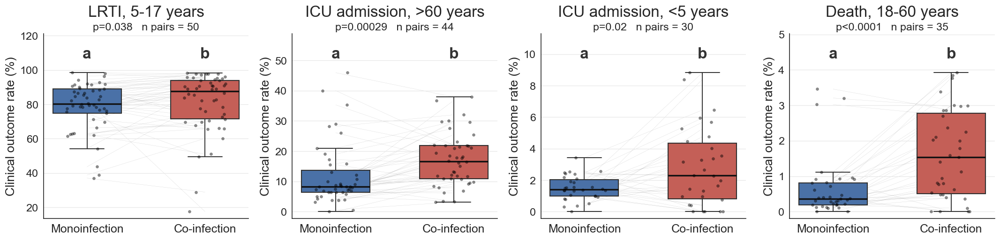

In [456]:
# Pairwise comparison: within each pathogen pair, compare co-infection with monoinfection.
# The input table defines monoinfection as exactly one positive pathogen and co-infection as both positive.
PAIRWISE_OUTCOME_DIR = rel('023_coinfection_outcome')
pairwise_outcomes = normalize_pathogen_dataframe(pd.read_csv(PAIRWISE_OUTCOME_DIR / '023_pairwise_icu_death_age_results.csv'))
pairwise_summary = normalize_pathogen_dataframe(pd.read_csv(PAIRWISE_OUTCOME_DIR / '023_pairwise_icu_death_overall_summary.csv'))

PAIRWISE_OUTCOME_ORDER = ['LRTI', 'Hospitalization', 'ICU', 'Death']
PAIRWISE_OUTCOME_LABELS = {
    'LRTI': 'LRTI',
    'Hospitalization': 'Hospitalization',
    'ICU': 'ICU admission',
    'Death': 'Death',
}
PAIRWISE_GROUP_ORDER = ['Monoinfection', 'Co-infection']
PAIRWISE_GROUP_COLORS = {'Monoinfection': NATURE_COLORS[0], 'Co-infection': NATURE_COLORS[1]}
PAIRWISE_AGE_ORDER = ['Children (<5 years)', 'Adolescents (5-17 years)', 'Adults (18-60 years)', 'Older adults (>60 years)']

for col in [
    'Monoinfection rate (%)', 'Co-infection rate (%)',
    'Rate difference co-minus-mono (percentage points)', 'p_value',
    'FDR q value',
]:
    if col in pairwise_outcomes.columns:
        pairwise_outcomes[col] = pd.to_numeric(pairwise_outcomes[col], errors='coerce')
for col in [
    'Mean monoinfection rate (%)', 'Mean co-infection rate (%)',
    'Median monoinfection rate (%)', 'Median co-infection rate (%)',
    'Median paired difference co-minus-mono (percentage points)', 'p_value',
]:
    if col in pairwise_summary.columns:
        pairwise_summary[col] = pd.to_numeric(pairwise_summary[col], errors='coerce')

def _as_true(series):
    return series.astype(str).str.strip().str.lower().isin(['true', '1', 'yes'])

def plot_pairwise_outcome_comparison(ax, result_df, summary_df, outcome_key, title=None):
    sub = result_df.loc[
        result_df['Outcome key'].eq(outcome_key) & _as_true(result_df['Pass outcome filter'])
    ].dropna(subset=['Monoinfection rate (%)', 'Co-infection rate (%)']).copy()
    if sub.empty:
        ax.text(0.5, 0.5, 'No eligible pathogen pairs', transform=ax.transAxes, ha='center', va='center', fontsize=16)
        ax.set_title(title or PAIRWISE_OUTCOME_LABELS[outcome_key], fontsize=20)
        nature_axes(ax)
        return

    long_df = pd.concat([
        sub[['Pathogen pair', 'Monoinfection rate (%)']].rename(columns={'Monoinfection rate (%)': 'Rate (%)'}).assign(Group='Monoinfection'),
        sub[['Pathogen pair', 'Co-infection rate (%)']].rename(columns={'Co-infection rate (%)': 'Rate (%)'}).assign(Group='Co-infection'),
    ], ignore_index=True)
    plot_order = PAIRWISE_GROUP_ORDER.copy()
    letters = {group: 'a' for group in plot_order}
    summary_row = summary_df.loc[summary_df['Outcome key'].eq(outcome_key)]
    p_value = summary_row.iloc[0].get('p_value', np.nan) if not summary_row.empty else np.nan
    if pd.notna(p_value) and p_value < 0.05 and len(plot_order) == 2:
        letters[plot_order[1]] = 'b'
    sns.boxplot(
        data=long_df, x='Group', y='Rate (%)', order=plot_order,
        palette=PAIRWISE_GROUP_COLORS, width=0.58, showfliers=False, linewidth=1.25,
        boxprops={'edgecolor': '#2F2F2F'}, whiskerprops={'color': '#2F2F2F', 'linewidth': 1.15},
        capprops={'color': '#2F2F2F', 'linewidth': 1.15}, medianprops={'color': '#111111', 'linewidth': 2.0}, ax=ax,
    )
    sns.stripplot(
        data=long_df, x='Group', y='Rate (%)', order=plot_order, color='black', size=3.6,
        alpha=0.46, jitter=0.18, edgecolor='black', linewidth=0.25, ax=ax, zorder=2.2,
    )

    wide_df = long_df.pivot_table(index='Pathogen pair', columns='Group', values='Rate (%)', aggfunc='first')
    x_positions = {group: idx for idx, group in enumerate(plot_order)}
    if set(plot_order).issubset(wide_df.columns):
        for _, row in wide_df.dropna(subset=plot_order).iterrows():
            ax.plot([x_positions[group] for group in plot_order], [row[group] for group in plot_order], color='black', alpha=0.18, linewidth=0.25, zorder=0.5)

    ymax = float(np.nanmax(long_df['Rate (%)']))
    ymin = float(np.nanmin(long_df['Rate (%)']))
    span = max(ymax - ymin, 0.5)
    y_letter = ymax + 0.08 * span
    for xpos, group in enumerate(plot_order):
        ax.text(xpos, y_letter, letters[group], ha='center', va='bottom', fontsize=20, fontweight='bold', color='#333333')
    ax.set_ylim(ymin - 0.05 * span, ymax + 0.28 * span)

    if not summary_row.empty:
        summary_row = summary_row.iloc[0]
        n_pairs = summary_row.get('n pair rates', len(sub))
        ax.text(
            0.5, 1.01, f'{format_p(p_value)}   n pairs = {int(n_pairs)}',
            transform=ax.transAxes, ha='center', va='bottom', fontsize=14,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.82, 'pad': 2.0},
        )
    ax.set_title(title or PAIRWISE_OUTCOME_LABELS[outcome_key], fontsize=20, pad=22)
    ax.set_xlabel('')
    ax.set_ylabel('Clinical outcome rate (%)', fontsize=16)
    nature_axes(ax)
    ax.tick_params(axis='x', labelsize=15, pad=2)
    ax.tick_params(axis='y', labelsize=14, pad=2)

# Figure 2A: the four age/outcome comparisons shown in the PDF.
FIGURE_2A_COMPARISONS = [
    ('Adolescents (5-17 years)', 'LRTI', 'LRTI, 5-17 years'),
    ('Older adults (>60 years)', 'ICU', 'ICU admission, >60 years'),
    ('Children (<5 years)', 'ICU', 'ICU admission, <5 years'),
    ('Adults (18-60 years)', 'Death', 'Death, 18-60 years'),
]
fig, axes = plt.subplots(1, len(FIGURE_2A_COMPARISONS), figsize=(18, 4.5), squeeze=False)
for ax, (age_group, outcome_key, title) in zip(axes[0], FIGURE_2A_COMPARISONS):
    age_results = pairwise_outcomes.loc[pairwise_outcomes['Age group'].eq(age_group)].copy()
    age_summary = pairwise_summary.loc[pairwise_summary['Age group'].eq(age_group)].copy()
    plot_pairwise_outcome_comparison(ax, age_results, age_summary, outcome_key, title=title)
fig.tight_layout()
plt.show()


In [457]:
ACTIVE_FIGURE_LABEL = 'Figure_2'
OUT_DIR = output_dir('Figure_2')


### Figure_2 · panel B: leading pairs by clinical outcome


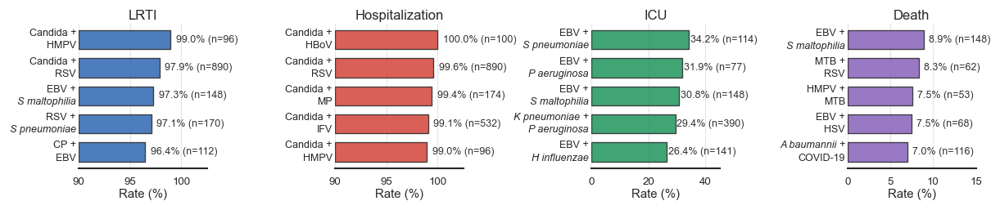

In [458]:
# Top five co-infection pairs for each outcome and age group.
# The source table already calculates outcomes among both-positive encounters.
plt.rcParams.update({'font.family': 'Arial', 'font.sans-serif': ['Arial'], 'pdf.fonttype': 42, 'ps.fonttype': 42})
TOP_CLINICAL_SOURCE = rel('10_top_coinfections/10_top_coinfection_clinical_outcomes.csv')
TOP_CLINICAL_OUTPUT = output_dir('Figure_S4') / '15_top_coinfection_clinical_outcomes_by_age.csv'
TOP_CLINICAL_FIGURE = '15_top_coinfection_clinical_outcomes_by_age'
MIN_BOTH_TESTED = 100
MIN_OUTCOME_DENOMINATOR = 50
TOP_N = 5

CLINICAL_OUTCOMES = [
    ('LRTI rate (%)', 'LRTI', 'LRTI'),
    ('Hospitalization rate (%)', 'Hospitalization', 'Hospitalization'),
    ('ICU rate (%)', 'ICU', 'ICU'),
    ('Death rate (%)', 'Death', 'Death'),
]
CLINICAL_AGE_ORDER = [
    'Children (<5 years)',
    'Adolescents (5-17 years)',
    'Adults (18-60 years)',
    'Older adults (>60 years)',
    'Unknown',
]

clinical_df = pd.read_csv(TOP_CLINICAL_SOURCE)
UNKNOWN_CLINICAL_SOURCE = rel('plot_paper/11_unknown_age_top_coinfection_clinical_outcomes.csv')
if (
    not clinical_df['Age section'].eq('Unknown').any()
    and UNKNOWN_CLINICAL_SOURCE.exists()
):
    clinical_df = pd.concat([clinical_df, pd.read_csv(UNKNOWN_CLINICAL_SOURCE)], ignore_index=True)
numeric_columns = ['Both tested n', 'Coinfection n'] + [item[0] for item in CLINICAL_OUTCOMES]
numeric_columns += [f'{base_name} rate (%) denominator' for _, base_name, _ in CLINICAL_OUTCOMES]
for column in numeric_columns:
    clinical_df[column] = pd.to_numeric(clinical_df[column], errors='coerce')

clinical_df = clinical_df.loc[
    clinical_df['Panel'].eq('All')
    & clinical_df['Both tested n'].gt(MIN_BOTH_TESTED)
].copy()

def clean_clinical_pair_name(pair):
    return ' + '.join(part.strip().replace('. ', ' ', 1) for part in str(pair).split('+', 1))

def format_clinical_pair_label(pair):
    pair_parts = clean_clinical_pair_name(pair).split(' + ', 1)
    return ' +\n'.join(pair_parts) if len(pair_parts) == 2 else pair_parts[0]

clinical_df['Pair'] = clinical_df['Pair'].map(clean_clinical_pair_name)
def has_bacterial_pair(pair):
    return any(part in BACTERIA_ITALIC_LABELS for part in str(pair).split(' + '))

PAIR_LABEL_LINE_OFFSET = 0.22

def draw_pair_label(ax, y, pair, fontsize=7.5):
    pair_parts = clean_clinical_pair_name(pair).split(' + ', 1)
    for line_idx, part in enumerate(pair_parts):
        label = f'{part} +' if line_idx == 0 and len(pair_parts) == 2 else part
        ax.text(
            -0.02, y + (PAIR_LABEL_LINE_OFFSET if line_idx == 0 else -PAIR_LABEL_LINE_OFFSET), label,
            transform=ax.get_yaxis_transform(), ha='right', va='center',
            fontsize=fontsize, fontname='Arial',
            fontstyle='italic' if part in BACTERIA_ITALIC_LABELS else 'normal',
            clip_on=False,
        )

top_rows = []
for age_group in CLINICAL_AGE_ORDER:
    age_df = clinical_df.loc[clinical_df['Age section'].eq(age_group)]
    for outcome, base_name, _ in CLINICAL_OUTCOMES:
        denominator_column = f'{base_name} rate (%) denominator'
        sub = age_df.loc[age_df[denominator_column].gt(MIN_OUTCOME_DENOMINATOR)].dropna(subset=[outcome]).sort_values(
            [outcome, 'Coinfection n', 'Pair'], ascending=[False, False, True]
        ).head(TOP_N)
        for rank, (_, row) in enumerate(sub.iterrows(), start=1):
            top_rows.append({
                'Age group': age_group,
                'Outcome': outcome,
                'Rank': rank,
                'Pair': row['Pair'],
                'Coinfection n': int(row['Coinfection n']),
                'Numerator': int(row[f'{base_name} rate (%) numerator']),
                'Denominator': int(row[f'{base_name} rate (%) denominator']),
                'Rate (%)': row[outcome],
            })

top_clinical_df = pd.DataFrame(top_rows)

outcome_colors = {
    'LRTI rate (%)': NATURE_COLORS[0],
    'Hospitalization rate (%)': NATURE_COLORS[1],
    'ICU rate (%)': NATURE_COLORS[2],
    'Death rate (%)': NATURE_COLORS[3],
}
CLINICAL_AXIS_LIMITS = {
    'LRTI rate (%)': (70, 105),
    'Hospitalization rate (%)': (80, 105),
    'ICU rate (%)': (0, 55),
    'Death rate (%)': (0, 15),
}
CLINICAL_OVERALL_AXIS_LIMITS = {
    'LRTI rate (%)': (90, 102.5),
    'Hospitalization rate (%)': (90, 102.5),
    'ICU rate (%)': (0, 45),
    'Death rate (%)': (0, 15),
}
# Overall top-five figure, using the same outcome-denominator filter.
overall_top_rows = []
overall_age_df = clinical_df.loc[clinical_df['Age section'].eq('All ages')]
for outcome, base_name, _ in CLINICAL_OUTCOMES:
    denominator_column = f'{base_name} rate (%) denominator'
    sub = overall_age_df.loc[overall_age_df[denominator_column].gt(MIN_OUTCOME_DENOMINATOR)].dropna(subset=[outcome]).sort_values(
        [outcome, 'Coinfection n', 'Pair'], ascending=[False, False, True]
    ).head(TOP_N)
    for rank, (_, row) in enumerate(sub.iterrows(), start=1):
        overall_top_rows.append({
            'Age group': 'All ages',
            'Outcome': outcome,
            'Rank': rank,
            'Pair': row['Pair'],
            'Coinfection n': int(row['Coinfection n']),
            'Numerator': int(row[f'{base_name} rate (%) numerator']),
            'Denominator': int(row[denominator_column]),
            'Rate (%)': row[outcome],
        })

overall_top_df = pd.DataFrame(overall_top_rows)
top_clinical_df = pd.concat([overall_top_df, top_clinical_df], ignore_index=True)

fig, axes = plt.subplots(1, len(CLINICAL_OUTCOMES), figsize=(10.2, 2.3), squeeze=False)
for col_idx, (outcome, _, _) in enumerate(CLINICAL_OUTCOMES):
    ax = axes[0, col_idx]
    sub = overall_top_df.loc[overall_top_df['Outcome'].eq(outcome)].sort_values('Rank', ascending=False)
    y = np.arange(len(sub))
    axis_start, axis_end = CLINICAL_OVERALL_AXIS_LIMITS[outcome]
    bars = ax.barh(
        y, sub['Rate (%)'] - axis_start, left=axis_start,
        color=outcome_colors[outcome], alpha=0.90,
        edgecolor='#2F2F2F', linewidth=0.8, height=0.68,
    )
    ax.set_yticks(y)
    ax.set_yticklabels([])
    for yi, (_, item) in zip(y, sub.iterrows()):
        draw_pair_label(ax, yi, item['Pair'])
    ax.set_xlim(axis_start, axis_end)
    ax.grid(axis='x', color='#E6E6E6', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.tick_params(axis='x', labelsize=8, pad=1)
    ax.set_title(outcome.replace(' rate (%)', ''), fontsize=10, pad=3, fontname='Arial')
    ax.set_xlabel('Rate (%)', fontsize=9, labelpad=1, fontname='Arial')
    for bar, (_, item) in zip(bars, sub.iterrows()):
        ax.text(
            item['Rate (%)'] + 0.55, bar.get_y() + bar.get_height() / 2,
            f"{item['Rate (%)']:.1f}% (n={int(item['Coinfection n'])})",
            va='center', ha='left', fontsize=7.5, color='#333333', fontname='Arial',
        )

fig.subplots_adjust(left=0.10, right=0.995, top=0.86, bottom=0.22, wspace=1.0)
plt.show()


### Figure_2 · clinical outcome risk-ratio heatmap


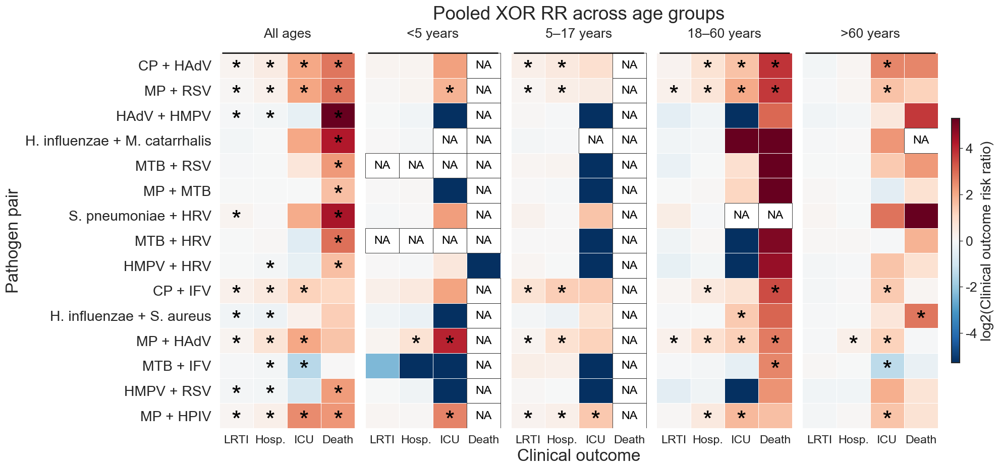

In [459]:
"""Plot common pooled-XOR RR values across all age groups."""

DEFAULT_INPUT = input_for('rti_plot_ai/bacr_coinfec_comp_final/pooled_xor_rr_long.csv', 'Figure_2')
DEFAULT_OUTPUT = output_dir('Figure_2')
AGE_ORDER = ['All ages', 'Children (<5 years)', 'Adolescents (5-17 years)', 'Adults (18-60 years)', 'Older adults (>60 years)']
AGE_LABELS = {
    'All ages': 'All ages',
    'Children (<5 years)': '<5 years',
    'Adolescents (5-17 years)': '5–17 years',
    'Adults (18-60 years)': '18–60 years',
    'Older adults (>60 years)': '>60 years',
}
OUTCOMES = ['LRTI', 'Hospitalization', 'ICU', 'Death']
OUTCOME_LABELS = {'LRTI': 'LRTI', 'Hospitalization': 'Hosp.', 'ICU': 'ICU', 'Death': 'Death'}
SPECIAL_PAIRS = {
    'SARS-COV-2 + IFV', 'SARS-COV-2 + RSV', 'SARS-COV-2 + MP',
    'IFV + RSV', 'IFV + MP', 'MP + RSV',
}

STYLE_DIR = Path('/home/zhangl/.codex/skills/nature-biomed-plotting/scripts')
def apply_nature_style():
    plt.rcParams.update({'font.family':'Arial','font.size':14,'axes.labelsize':16,'axes.titlesize':18,'pdf.fonttype':42,'ps.fonttype':42})
def parse_args():
    parser = argparse.ArgumentParser(description='Plot pooled-XOR RR across five age groups.')
    parser.add_argument('--input-csv', default=str(DEFAULT_INPUT))
    parser.add_argument('--output-dir', default=str(DEFAULT_OUTPUT))
    parser.add_argument('--n-pairs', type=int, default=15)
    return parser.parse_args()

def p_stars(q_value):
    if pd.isna(q_value):
        return ''
    if q_value < 0.05:
        return '*'
    return ''

def as_bool(value):
    return str(value).strip().lower() in {'true', '1', 'yes'}

def load_data(path):
    result = pd.read_csv(path, encoding='utf-8-sig')
    result.columns = [str(column).replace('\ufeff', '').strip() for column in result.columns]
    numeric = [
        'RR used for display', 'Display log2 RR',
        'Chi-square q value (BH-FDR)', 'Co-infection denominator',
    ]
    for column in numeric:
        result[column] = pd.to_numeric(result[column], errors='coerce')
    result['Pair pass filter'] = result['Pair pass filter'].map(as_bool)
    result['Sufficient sample size for inference'] = result['Sufficient sample size for inference'].map(as_bool)
    result['FDR significant (q < alpha)'] = result['FDR significant (q < alpha)'].map(as_bool)
    return result.loc[result['Age group'].isin(AGE_ORDER) & result['Outcome key'].isin(OUTCOMES)].copy()

def select_pairs(result, n_pairs):
    all_age = result.loc[result['Age group'].eq('All ages')].copy()
    all_age_summary = all_age.groupby(['Pair key', 'Pathogen pair'], as_index=False).agg(
        eligible_outcomes=('Sufficient sample size for inference', 'sum'),
        rr_outcomes=('RR used for display', lambda x: int(x.notna().sum())),
        median_co_infection_denominator=('Co-infection denominator', 'median'),
        significant_outcomes=('FDR significant (q < alpha)', 'sum'),
    )
    death = all_age.loc[all_age['Outcome key'].eq('Death'), [
        'Pair key', 'FDR significant (q < alpha)', 'RR used for display',
    ]].rename(columns={
        'FDR significant (q < alpha)': 'death_significant',
        'RR used for display': 'death_rr',
    })
    all_age_summary = all_age_summary.merge(death, on='Pair key', how='left')
    common = result.groupby(['Pair key', 'Age group'], as_index=False).agg(
        pair_pass=('Pair pass filter', 'max'),
    ).groupby('Pair key', as_index=False).agg(
        age_group_count=('Age group', 'nunique'),
        pair_pass_age_count=('pair_pass', 'sum'),
    )
    candidates = all_age_summary.merge(common, on='Pair key', how='inner')
    candidates = candidates.loc[
        candidates['eligible_outcomes'].eq(4)
        & candidates['rr_outcomes'].eq(4)
        & candidates['age_group_count'].eq(5)
        & candidates['pair_pass_age_count'].eq(5)
    ]
    focus_death = result.loc[
        result['Age group'].isin(AGE_ORDER) & result['Outcome key'].eq('Death'),
        ['Pair key', 'FDR significant (q < alpha)', 'RR used for display', 'Display log2 RR'],
    ]
    focus_death = focus_death.assign(
        death_star=(
            focus_death['FDR significant (q < alpha)']
            & focus_death['RR used for display'].notna()
        ),
        death_abs_log2=focus_death['Display log2 RR'].abs(),
    ).groupby('Pair key', as_index=False).agg(
        death_star_count=('death_star', 'sum'),
        death_abs_log2=('death_abs_log2', 'max'),
    )
    candidates = candidates.merge(focus_death, on='Pair key', how='left').fillna({
        'death_star_count': 0,
        'death_abs_log2': 0,
    })
    candidates['death_priority'] = candidates['death_star_count'].gt(0)
    candidates['special_priority'] = candidates['Pair key'].isin(SPECIAL_PAIRS)
    death_first = candidates.loc[candidates['death_priority']].sort_values(
        ['death_star_count', 'death_abs_log2', 'median_co_infection_denominator', 'Pathogen pair'],
        ascending=[False, False, False, True], na_position='last',
    )
    selected = pd.concat([death_first, candidates.loc[
        candidates['special_priority'] & ~candidates['Pair key'].isin(set(death_first['Pair key']))
    ].sort_values(['median_co_infection_denominator', 'Pathogen pair'], ascending=[False, True])], ignore_index=True)
    selected_keys = set(selected['Pair key'])
    selected = pd.concat([selected, candidates.loc[~candidates['Pair key'].isin(selected_keys)].sort_values(
        ['significant_outcomes', 'median_co_infection_denominator', 'Pathogen pair'],
        ascending=[False, False, True], na_position='last',
    )], ignore_index=True).head(n_pairs).reset_index(drop=True)
    selected.insert(0, 'Selection rank', np.arange(1, len(selected) + 1))
    selected['Priority group'] = np.select(
        [selected['death_priority'], selected['special_priority']],
        ['Death FDR q<0.05 in one or more age groups', 'SARS-COV-2/IFV/RSV/MP combination'],
        default='Additional common pair',
    )
    selected['Selection rule'] = 'All-age four-outcome complete; pair filter passed in all five age groups; pairs with more death FDR-significant age groups are shown first'
    return selected

def matrices(result, selected):
    labels = selected['Pathogen pair'].tolist()
    columns = [(age, outcome) for age in AGE_ORDER for outcome in OUTCOMES]
    index = pd.Index(labels, name='Pathogen pair')
    value = pd.DataFrame(np.nan, index=index, columns=columns, dtype=float)
    q_value = pd.DataFrame(np.nan, index=index, columns=columns, dtype=float)
    status = pd.DataFrame('', index=index, columns=columns, dtype=object)
    sub = result.loc[result['Pair key'].isin(set(selected['Pair key']))]
    for row in sub.to_dict('records'):
        key = (row['Age group'], row['Outcome key'])
        label = row['Pathogen pair']
        if label not in index or key not in columns:
            continue
        value.at[label, key] = row['RR used for display']
        q_value.at[label, key] = row['Chi-square q value (BH-FDR)']
        status.at[label, key] = row['Raw RR status']
    return value, q_value, status

def plot(result, selected, output_dir, output_prefix):
    value, q_value, _ = matrices(result, selected)
    plot_columns = []
    cell_positions = {}
    for age_index, age in enumerate(AGE_ORDER):
        for outcome in OUTCOMES:
            cell_positions[(age, outcome)] = len(plot_columns)
            plot_columns.append((age, outcome))
        if age_index < len(AGE_ORDER) - 1:
            plot_columns.append(None)

    n_plot_columns = len(plot_columns)
    column_x_starts = []
    column_widths = []
    x_cursor = 0.0
    for column in plot_columns:
        width = 0.3 if column is None else 1.0
        column_x_starts.append(x_cursor)
        column_widths.append(width)
        x_cursor += width
    x_edges = np.append(column_x_starts, x_cursor)

    plot_value = pd.DataFrame(
        np.nan, index=value.index, columns=np.arange(n_plot_columns), dtype=float,
    )
    plot_q_value = pd.DataFrame(
        np.nan, index=q_value.index, columns=np.arange(n_plot_columns), dtype=float,
    )
    for key, position in cell_positions.items():
        plot_value[position] = value[key]
        plot_q_value[position] = q_value[key]

    log2_value = np.log2(plot_value.where(plot_value > 0))
    finite = log2_value.to_numpy(float)
    finite = finite[np.isfinite(finite)]
    color_limit = max(float(np.nanpercentile(np.abs(finite), 98)), 0.5) if len(finite) else 1.0
    log2_value = log2_value.mask(plot_value.eq(0), -color_limit)
    mask = plot_value.isna()

    fig, ax = plt.subplots(figsize=(18,10))
    cmap = plt.get_cmap('RdBu_r').copy()
    cmap.set_bad('white')
    heatmap_data = np.ma.masked_where(mask.to_numpy(), log2_value.to_numpy(float))
    heatmap = ax.pcolormesh(
        x_edges, np.arange(len(plot_value.index) + 1), heatmap_data,
        cmap=cmap, vmin=-color_limit, vmax=color_limit,
        shading='flat', edgecolors='white', linewidth=0.55,
    )
    cbar = fig.colorbar(
        heatmap, ax=ax, fraction=0.018, shrink=0.65, aspect=30, pad=0.018,
    )
    ax.set_xlim(0, x_cursor)
    ax.set_ylim(len(plot_value.index), 0)
    cbar.set_label('log2(Clinical outcome risk ratio)', fontsize=17)
    cbar.ax.tick_params(labelsize=16, width=0.8, length=3.5)
    for i, label in enumerate(value.index):
        for j, column in enumerate(plot_columns):
            if column is None:
                continue
            rr = plot_value.iat[i, j]
            q = plot_q_value.iat[i, j]
            text = p_stars(q) if pd.notna(rr) else 'NA'
            if not text:
                continue
            x_start = column_x_starts[j]
            if text == 'NA':
                ax.add_patch(Rectangle(
                    (x_start, i), 1, 1, facecolor='white', edgecolor='black',
                    linewidth=0.45, zorder=3,
                ))
                ax.text(
                    x_start + 0.5, i + 0.5, text,
                    ha='center', va='center', fontsize=14,
                    color='black', fontweight='normal', zorder=5,
                )
            else:
                ax.text(
                    x_start + 0.5, i + 0.75, text,
                    ha='center', va='center', fontsize=30,
                    color='black', fontweight='normal', zorder=5,
                )

    tick_positions = [column_x_starts[position] + 0.5 for position in cell_positions.values()]
    tick_labels = [OUTCOME_LABELS[outcome] for age in AGE_ORDER for outcome in OUTCOMES]
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=0, ha='center', fontsize=14)
    ax.xaxis.tick_bottom()
    ax.tick_params(axis='x', length=0, pad=8)
    ax.set_yticks(np.arange(len(value.index)) + 0.5)
    ax.set_yticklabels(value.index, rotation=0, fontsize=17)
    ax.set_xlabel('Clinical outcome', fontsize=20)
    ax.set_ylabel('Pathogen pair', fontsize=20)
    ax.set_title('Pooled XOR RR across age groups', fontsize=22, pad=40)
    ax.set_facecolor('white')
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

    for age_index, age in enumerate(AGE_ORDER):
        start = cell_positions[(age, OUTCOMES[0])]
        start_x = column_x_starts[start]
        end_x = column_x_starts[cell_positions[(age, OUTCOMES[-1])]] + 1
        ax.plot(
            [start_x + 0.08, end_x - 0.08], [1.0, 1.0],
            transform=ax.get_xaxis_transform(), color='black', linewidth=1.5,
            solid_capstyle='butt', clip_on=False, zorder=6,
        )
        ax.text(
            (start_x + end_x) / (2 * x_cursor), 1.035, AGE_LABELS[age],
            transform=ax.transAxes, ha='center', va='bottom', fontsize=16,
            fontweight='normal', clip_on=False,
        )

    fig.tight_layout(rect=[0, 0.10, 0.93, 0.90])
    plt.show()
ACTIVE_FIGURE_LABEL = 'Figure_2'
OUT_DIR = output_dir('Figure_2')
apply_nature_style()
rr_data = load_data(DEFAULT_INPUT)
selected_pairs = select_pairs(rr_data, 15)
plot(rr_data, selected_pairs, OUT_DIR, 'Figure_2_C_clinical_outcome_risk_ratio')


### Figure_3 · panel A: BACR schematic and example fits


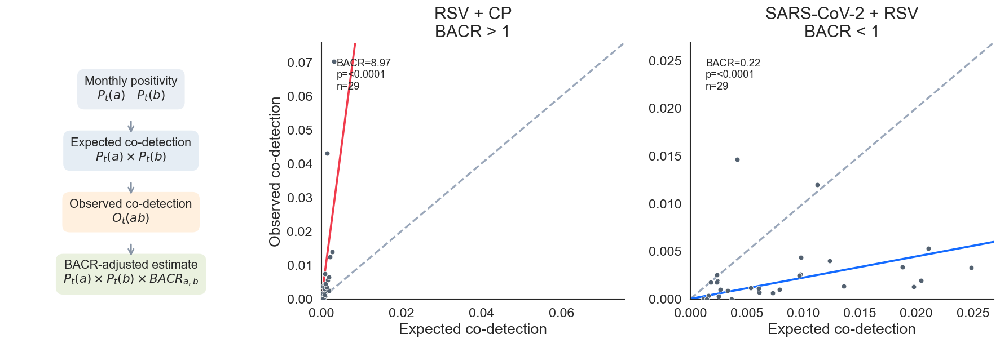

In [460]:
ACTIVE_FIGURE_LABEL = 'Figure_3'
OUT_DIR = output_dir('Figure_3')
monthly = pd.read_csv(input_for('rti_plot_ai/02_population_inte/month/all_pathogen_pairwise_time_rates.csv', 'Figure_3_S5'))
monthly['BatchDate'] = pd.to_datetime(monthly['BatchDate'], errors='coerce')

def eligible_pair(a, b):
    frame = monthly.loc[monthly['Pathogen A'].eq(a) & monthly['Pathogen B'].eq(b)].copy()
    for col in ['A tested', 'B tested', 'Both tested', 'P(a,t)*P(b,t)', 'P(a,b,t)']:
        frame[col] = pd.to_numeric(frame[col], errors='coerce')
    frame = frame.loc[frame['A tested'].gt(500) & frame['B tested'].gt(500) & frame['Both tested'].gt(50)].dropna(subset=['P(a,t)*P(b,t)', 'P(a,b,t)'])
    return frame

def slope_fit(frame):
    x = frame['P(a,t)*P(b,t)'].to_numpy(float)
    y = frame['P(a,b,t)'].to_numpy(float)
    beta = np.dot(x, y) / np.dot(x, x)
    se = np.sqrt(np.dot(y-beta*x, y-beta*x) / (len(x)-1) / np.dot(x,x))
    p = 2 * student_t.sf(abs((beta-1)/se), len(x)-1)
    return beta, p
fig, axes = plt.subplots(1, 3, figsize=(15, 5.3), gridspec_kw={'width_ratios':[0.82, 1, 1]})
ax = axes[0]
ax.axis('off')
blocks=[('Monthly positivity', r'$P_t(a) \quad P_t(b)$', '#E9EEF4'), ('Expected co-detection', r'$P_t(a) \times P_t(b)$', '#E5EDF4'), ('Observed co-detection', r'$O_t(ab)$', '#FFF0DF'), ('BACR-adjusted estimate', r'$P_t(a) \times P_t(b) \times BACR_{a,b}$', '#EAF1DF')]
ypos=[0.82,0.58,0.34,0.10]
for (title, formula, color), y in zip(blocks,ypos):
    ax.text(.5,y, f'{title}\n{formula}', ha='center',va='center',fontsize=13,bbox={'boxstyle':'round,pad=0.6','facecolor':color,'edgecolor':'none'},transform=ax.transAxes)
for y1,y2 in zip([.70,.46,.22],[.64,.40,.16]): 
    ax.annotate('',xy=(.5,y2),xytext=(.5,y1),xycoords='axes fraction',arrowprops={'arrowstyle':'->','color':'#8794A5','lw':1.6})
pairs=[('CP','RSV','RSV + CP','#F03B4C'),('COVID-19','RSV','SARS-CoV-2 + RSV','#146BFF')]
for ax,(a,b,label,color) in zip(axes[1:],pairs):
    d=eligible_pair(a,b)
    beta,p=slope_fit(d)
    x=d['P(a,t)*P(b,t)'].to_numpy(float)
    y=d['P(a,b,t)'].to_numpy(float)
    upper=max(x.max(),y.max())*1.08
    upper=max(upper,.01)
    ax.scatter(x,y,s=28,color='#536170',edgecolor='white',linewidth=.5,zorder=3)
    ax.plot([0,upper],[0,upper],color='#9AA7BA',ls='--',lw=2)
    line=np.linspace(0,upper,100)
    ax.plot(line,beta*line,color=color,lw=2.2)
    ax.set(xlim=(0,upper),ylim=(0,upper),title=f'{label}\nBACR {">" if beta>1 else "<"} 1')
    ax.text(.05,.94,f'BACR={beta:.2f}\np={"<0.0001" if p<.0001 else f"{p:.2g}"}\nn={len(d)}',transform=ax.transAxes,va='top',fontsize=11)
    ax.set_xlabel('Expected co-detection')
    ax.grid(False)
    ax.set_axisbelow(True)
axes[1].set_ylabel('Observed co-detection')
for ax in axes[1:]: 
    ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
plt.show()


### Figure_3 · panel B: prevalence-adjusted co-detection matrix


FDR q < 0.05 significant pairs: 92


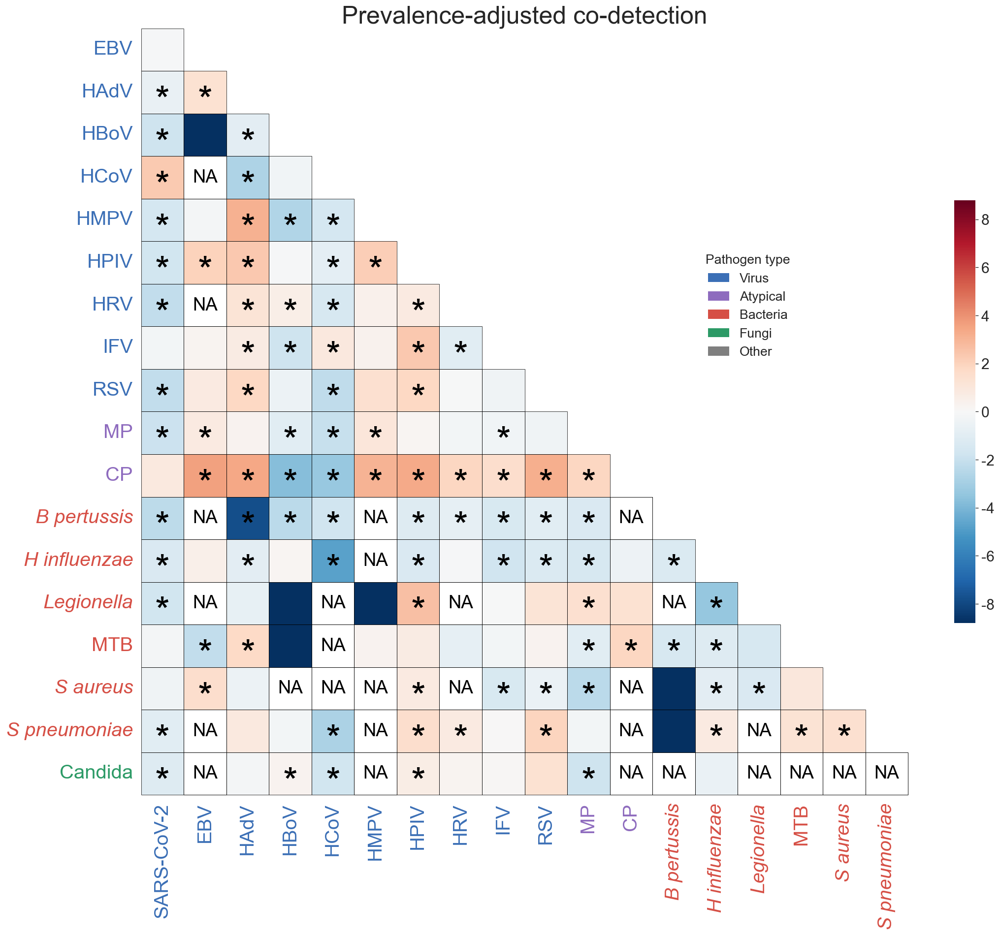

In [461]:
ACTIVE_FIGURE_LABEL = 'Figure_3'
rab_heatmap_pvalue = normalize_pathogen_dataframe(pd.read_csv(rel('02_population_inte/month/all_pathogen_rab_pvalue_matrix.csv'), index_col=0))
rab_heatmap_matrix = normalize_pathogen_dataframe(pd.read_csv(rel('02_population_inte/month/all_pathogen_rab_symmetric_matrix.csv'), index_col=0))
rab_common_index = rab_heatmap_matrix.index.intersection(rab_heatmap_pvalue.index)
rab_common_cols = rab_heatmap_matrix.columns.intersection(rab_heatmap_pvalue.columns)
rab_heatmap_matrix = rab_heatmap_matrix.loc[rab_common_index, rab_common_cols]
rab_heatmap_pvalue = rab_heatmap_pvalue.loc[rab_common_index, rab_common_cols]

desired_order = PATHOGEN_DISPLAY_ORDER
bacteria_italic_labels = BACTERIA_ITALIC_LABELS

rab_matrix_float = rab_heatmap_matrix.astype(float).copy()
rab_pvalue_float = rab_heatmap_pvalue.astype(float).copy()

rab_plot_matrix = np.log2(rab_matrix_float.where(rab_matrix_float > 0))
rab_plot_min = np.nanmin(rab_plot_matrix.values)
rab_plot_matrix[rab_matrix_float == 0] = rab_plot_min - 1
rab_plot_matrix = rab_plot_matrix.replace([np.inf, -np.inf], np.nan)

rab_missing_mask = rab_matrix_float.isna() | rab_plot_matrix.isna() | np.isinf(rab_plot_matrix)

rab_initial_upper_triangle_mask = pd.DataFrame(np.triu(np.ones(rab_plot_matrix.shape, dtype=bool), k=0), index=rab_plot_matrix.index, columns=rab_plot_matrix.columns)
rab_initial_lower_triangle_mask = ~rab_initial_upper_triangle_mask

rab_fdr_mask = rab_initial_lower_triangle_mask & rab_pvalue_float.notna()

rab_qvalue_float = pd.DataFrame(np.nan, index=rab_pvalue_float.index, columns=rab_pvalue_float.columns, dtype=float)

rab_fdr_pvalues = rab_pvalue_float.where(rab_fdr_mask).to_numpy(dtype=float)
rab_fdr_valid = np.isfinite(rab_fdr_pvalues)

if rab_fdr_valid.any():
    rab_fdr_qvalues = multipletests(rab_fdr_pvalues[rab_fdr_valid], method='fdr_bh')[1]
    rab_qvalue_values = rab_qvalue_float.to_numpy(dtype=float)
    rab_qvalue_values[rab_fdr_valid] = rab_fdr_qvalues
    rab_qvalue_float = pd.DataFrame(rab_qvalue_values, index=rab_pvalue_float.index, columns=rab_pvalue_float.columns)

# FDR was calculated in one triangle; mirror q values before reordering the pathogens
rab_qvalue_float = rab_qvalue_float.combine_first(rab_qvalue_float.T)

rab_row_has_value = (~rab_missing_mask).any(axis=1)
rab_col_has_value = (~rab_missing_mask).any(axis=0)
rab_all_blank = (~rab_row_has_value) & (~rab_col_has_value)
rab_keep_pathogens = rab_plot_matrix.index[~rab_all_blank]

rab_ordered_pathogens = [p for p in desired_order if p in rab_keep_pathogens]
rab_ordered_pathogens += [p for p in rab_keep_pathogens if p not in rab_ordered_pathogens]

rab_plot_matrix = rab_plot_matrix.loc[rab_ordered_pathogens, rab_ordered_pathogens]
rab_matrix_float = rab_matrix_float.loc[rab_ordered_pathogens, rab_ordered_pathogens]
rab_pvalue_float = rab_pvalue_float.loc[rab_ordered_pathogens, rab_ordered_pathogens]
rab_qvalue_float = rab_qvalue_float.loc[rab_ordered_pathogens, rab_ordered_pathogens]
rab_missing_mask = rab_missing_mask.loc[rab_ordered_pathogens, rab_ordered_pathogens]

rab_all_pathogens = rab_plot_matrix.index.tolist()

rab_row_labels = rab_all_pathogens[1:]
rab_col_labels = rab_all_pathogens[:-1]

rab_plot_matrix = rab_plot_matrix.loc[rab_row_labels, rab_col_labels]
rab_matrix_float = rab_matrix_float.loc[rab_row_labels, rab_col_labels]
rab_pvalue_float = rab_pvalue_float.loc[rab_row_labels, rab_col_labels]
rab_qvalue_float = rab_qvalue_float.loc[rab_row_labels, rab_col_labels]
rab_missing_mask = rab_missing_mask.loc[rab_row_labels, rab_col_labels]

rab_pathogen_pos = pd.Series(np.arange(len(rab_all_pathogens)), index=rab_all_pathogens)
rab_row_pos = rab_pathogen_pos.loc[rab_row_labels].to_numpy()
rab_col_pos = rab_pathogen_pos.loc[rab_col_labels].to_numpy()

rab_lower_triangle_mask = pd.DataFrame(rab_row_pos[:, None] > rab_col_pos[None, :], index=rab_row_labels, columns=rab_col_labels)
rab_non_lower_mask = ~rab_lower_triangle_mask

rab_sig_mask = (
    (rab_qvalue_float < 0.05)
    & rab_lower_triangle_mask
    & (~rab_missing_mask)
).fillna(False)
print(f'FDR q < 0.05 significant pairs: {int(rab_sig_mask.to_numpy().sum())}')

# 屏蔽上三角和缺失值
rab_heatmap_mask = rab_non_lower_mask | rab_missing_mask

rab_finite_vals = rab_plot_matrix.where(rab_lower_triangle_mask & (~rab_missing_mask)).to_numpy(dtype=float)
rab_finite_vals = rab_finite_vals[np.isfinite(rab_finite_vals)]

delta = max(float(np.nanquantile(np.abs(rab_finite_vals),0.99)),0.3) if len(rab_finite_vals) else 0.3

fig_size = max(10,18)
fig, ax = plt.subplots(figsize=(fig_size,fig_size*0.92))
ax.set_facecolor('white')

sns.heatmap(
    rab_plot_matrix,
    mask=rab_heatmap_mask,
    cmap='RdBu_r',
    center=0,
    vmin=-delta,
    vmax=delta,
    linewidths=0,
    linecolor='white',
    square=True,
    cbar_kws={'shrink':0.50,'fraction':0.1,'aspect':20},
    ax=ax
)

style_colorbar(ax.collections[0].colorbar)

for i in range(rab_plot_matrix.shape[0]):
    for j in range(rab_plot_matrix.shape[1]):
        if rab_lower_triangle_mask.iloc[i,j]:
            if rab_missing_mask.iloc[i,j]:
                ax.add_patch(Rectangle((j,i),1,1,facecolor='white',edgecolor='black',linewidth=0.45,zorder=3))
                ax.text(j+0.5,i+0.5,'NA',ha='center',va='center',fontsize=22,color='black',zorder=5)
            elif rab_sig_mask.iloc[i,j]:
                ax.text(j+0.5,i+0.75,'*',ha='center',va='center',fontsize=46,color='black',zorder=5)
            ax.add_patch(Rectangle((j,i),1,1,facecolor='none',edgecolor='black',linewidth=0.45,zorder=4))

margin=0.02
ax.set_xlim(-margin,rab_plot_matrix.shape[1]+margin)
ax.set_ylim(rab_plot_matrix.shape[0]+margin,-margin)
ax.set_title('Prevalence-adjusted co-detection',fontsize=30,pad=5)
ax.set_xlabel('')
ax.set_ylabel('')

plt.setp(ax.get_xticklabels(),rotation=90,ha='center',va='top',fontsize=24)
plt.setp(ax.get_yticklabels(),rotation=0,fontsize=24)

for label in ax.get_xticklabels():
    if label.get_text() in bacteria_italic_labels:
        label.set_fontstyle('italic')
for label in ax.get_yticklabels():
    if label.get_text() in bacteria_italic_labels:
        label.set_fontstyle('italic')

ax.tick_params(axis='x',pad=3)
ax.tick_params(axis='y',pad=3)

figure1b_type_colors = {
    'Virus': NATURE_COLORS[0],
    'Atypical': NATURE_COLORS[3],
    'Bacteria': NATURE_COLORS[1],
    'Fungi': NATURE_COLORS[2],
    'Other': NATURE_COLORS[6],
}

pathogen_label_colors = {pathogen:figure1b_type_colors['Virus'] for pathogen in VIRUS_ORDER}
pathogen_label_colors.update({pathogen:figure1b_type_colors['Atypical'] for pathogen in ['MP','CP']})
pathogen_label_colors.update({pathogen:figure1b_type_colors['Bacteria'] for pathogen in BACTERIA_ORDER if pathogen not in ['MP','CP']})
pathogen_label_colors['MTB'] = figure1b_type_colors['Bacteria']
pathogen_label_colors.update({pathogen:figure1b_type_colors['Fungi'] for pathogen in FUNGI_ORDER})

for label in ax.get_xticklabels():
    label.set_color(pathogen_label_colors.get(label.get_text(),figure1b_type_colors['Other']))
for label in ax.get_yticklabels():
    label.set_color(pathogen_label_colors.get(label.get_text(),figure1b_type_colors['Other']))

ax.legend(
    handles=[Patch(facecolor=color,edgecolor='none',label=pathogen_type) for pathogen_type,color in figure1b_type_colors.items()],
    title='Pathogen type',
    loc='upper left',
    bbox_to_anchor=(0.72,0.72),
    frameon=False,
    fontsize=16,
    title_fontsize=16,
    handlelength=1.6,
)

fig.tight_layout()
plt.show()


### Figure_3 · panel C: clinical outcomes by BACR direction

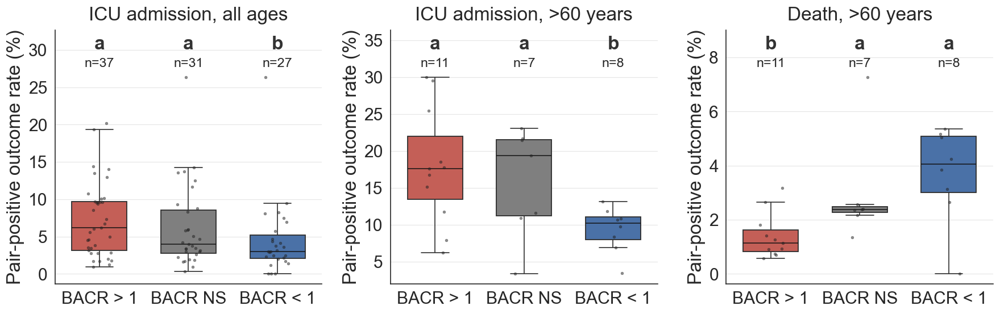

In [462]:
ACTIVE_FIGURE_LABEL = 'Figure_3'
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.size'] = 18
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 18
plt.rcParams['ytick.labelsize'] = 18
plt.rcParams['legend.fontsize'] = 18

GT_CATEGORY = 'Significant BACR > 1'
NULL_SOURCE_CATEGORY = 'Not significant'
NULL_CATEGORY = 'BACR = 1'
LT_CATEGORY = 'Significant BACR < 1'
SOURCE_CATEGORY_ORDER = [GT_CATEGORY, NULL_SOURCE_CATEGORY, LT_CATEGORY]
CATEGORY_ORDER = [GT_CATEGORY, NULL_CATEGORY, LT_CATEGORY]
CATEGORY_LABELS = {GT_CATEGORY: 'BACR > 1', NULL_CATEGORY: 'BACR NS', LT_CATEGORY: 'BACR < 1'}
SOURCE_TO_DISPLAY_CATEGORY = {
    GT_CATEGORY: GT_CATEGORY,
    NULL_SOURCE_CATEGORY: NULL_CATEGORY,
    LT_CATEGORY: LT_CATEGORY,
}

OVERALL_TESTS_CSV = rel('024_bacr_clinical_outcome/024_overall_bacr_pair_positive_clinical_tests.csv')
AGE_TESTS_CSV = rel('024_bacr_clinical_outcome/024_age_bacr_pair_positive_clinical_tests.csv')
OVERALL_CLINICAL_CSV = rel('024_bacr_clinical_outcome/024_overall_bacr_category_clinical_outcomes.csv')
AGE_CLINICAL_CSV = rel('024_bacr_clinical_outcome/024_age_bacr_category_clinical_outcomes.csv')

AGE_ORDER = ['All ages', '<5 years', '5-18 years', '18-60 years', '>60 years']
OUTCOME_ORDER = ['LRTI', 'Hospitalization', 'ICU', 'Death']

def select_direct_significant_tests(test_df, age_group):
    direct = (
        ((test_df['BACR category A'].eq(GT_CATEGORY))
         & (test_df['BACR category B'].eq(LT_CATEGORY)))
        | ((test_df['BACR category A'].eq(LT_CATEGORY))
           & (test_df['BACR category B'].eq(GT_CATEGORY)))
    )
    selected = test_df.loc[
        direct & pd.to_numeric(test_df['raw p value'], errors='coerce').lt(0.05)
    ].copy()
    if age_group is not None:
        selected['Age group'] = age_group
    return selected

overall_tests = select_direct_significant_tests(pd.read_csv(OVERALL_TESTS_CSV), 'All ages')
age_tests = select_direct_significant_tests(pd.read_csv(AGE_TESTS_CSV), None)
age_tests = age_tests.loc[age_tests['Age group'].notna()].copy()
significant_bacr_severity = pd.concat([overall_tests, age_tests], ignore_index=True)
significant_bacr_severity['Age sort'] = significant_bacr_severity['Age group'].map({age: i for i, age in enumerate(AGE_ORDER)})
significant_bacr_severity['Outcome sort'] = significant_bacr_severity['Outcome key'].map({outcome: i for i, outcome in enumerate(OUTCOME_ORDER)})
significant_bacr_severity = significant_bacr_severity.sort_values(['Outcome sort', 'Age sort']).drop(columns=['Age sort', 'Outcome sort'])

overall_clinical = pd.read_csv(OVERALL_CLINICAL_CSV)
overall_clinical['Age group'] = 'All ages'
age_clinical = pd.read_csv(AGE_CLINICAL_CSV)
clinical_outcomes = pd.concat([overall_clinical, age_clinical], ignore_index=True)
clinical_outcomes['Rate (%)'] = pd.to_numeric(clinical_outcomes['Rate (%)'], errors='coerce')
pair_positive_clinical = clinical_outcomes.loc[
    clinical_outcomes['Group'].eq('Co-infection')
    & clinical_outcomes['BACR significance category'].isin(SOURCE_CATEGORY_ORDER)
    & clinical_outcomes['Rate (%)'].notna()
].copy()
# The source table encodes the null BACR=1 reference group as 'Not significant'.
pair_positive_clinical['BACR plot category'] = pair_positive_clinical['BACR significance category'].map(SOURCE_TO_DISPLAY_CATEGORY)

def raw_pairwise_tests(sub):
    values = {
        category: pd.to_numeric(sub.loc[sub['BACR plot category'].eq(category), 'Rate (%)'], errors='coerce').dropna().to_numpy(dtype=float)
        for category in CATEGORY_ORDER
    }
    available = [values[category] for category in CATEGORY_ORDER if len(values[category])]
    if len(available) >= 2:
        try:
            kw_stat, kw_p = kruskal(*available)
        except ValueError:
            kw_stat, kw_p = np.nan, np.nan
    else:
        kw_stat, kw_p = np.nan, np.nan
    p_matrix = pd.DataFrame(np.nan, index=CATEGORY_ORDER, columns=CATEGORY_ORDER, dtype=float)
    rows = []
    for category_a, category_b in combinations(CATEGORY_ORDER, 2):
        values_a, values_b = values[category_a], values[category_b]
        if len(values_a) and len(values_b):
            if np.allclose(np.concatenate([values_a, values_b]), values_a[0]):
                statistic, p_value = 0.0, 1.0
            else:
                statistic, p_value = mannwhitneyu(values_a, values_b, alternative='two-sided', method='auto')
            p_matrix.loc[category_a, category_b] = p_value
            p_matrix.loc[category_b, category_a] = p_value
        else:
            statistic, p_value = np.nan, np.nan
        rows.append({
            'BACR category A': category_a,
            'BACR category B': category_b,
            'N category A': int(len(values_a)),
            'N category B': int(len(values_b)),
            'Median category A rate (%)': float(np.median(values_a)) if len(values_a) else np.nan,
            'Median category B rate (%)': float(np.median(values_b)) if len(values_b) else np.nan,
            'Mann-Whitney U statistic': float(statistic) if pd.notna(statistic) else np.nan,
            'raw p value': float(p_value) if pd.notna(p_value) else np.nan,
            'Kruskal-Wallis statistic': float(kw_stat) if pd.notna(kw_stat) else np.nan,
            'Kruskal-Wallis p value': float(kw_p) if pd.notna(kw_p) else np.nan,
        })
    value_df = sub[['BACR plot category', 'Rate (%)']].rename(columns={'BACR plot category': 'Group'})
    median_order = compute_median_sorted_groups(value_df, CATEGORY_ORDER, 'Rate (%)')
    # Assign letters in median order. The highest-median group starts at 'a';
    # groups sharing a letter are pairwise non-significant by the raw p values.
    letters = {}
    unassigned = set(median_order)
    letter_index = 0
    while unassigned:
        anchor = next(category for category in median_order if category in unassigned)
        clique = [anchor]
        for category in median_order:
            if category == anchor or category not in unassigned:
                continue
            if all(not (pd.notna(p_matrix.loc[category, member]) and p_matrix.loc[category, member] < 0.05) for member in clique):
                clique.append(category)
        letter = chr(ord('a') + letter_index)
        for category in clique:
            letters[category] = letter
            unassigned.discard(category)
        letter_index += 1
    for row in rows:
        row['Significance letters A'] = letters.get(row['BACR category A'], '')
        row['Significance letters B'] = letters.get(row['BACR category B'], '')
    return rows, letters, median_order

if significant_bacr_severity.empty:
    print('No direct BACR >1 versus BACR <1 clinical-severity comparisons have raw p < 0.05.')
else:
    category_colors = {GT_CATEGORY: '#D64F45', NULL_CATEGORY: '#7F7F7F', LT_CATEGORY: '#3B6FB6'}
    figure_specs = significant_bacr_severity[['Age group', 'Outcome key']].drop_duplicates().to_dict('records')
    pairwise_test_rows = []
    fig, axes = plt.subplots(1, len(figure_specs), figsize=(5 * len(figure_specs), 5), squeeze=False, sharey=False)

    for index, spec in enumerate(figure_specs):
        ax = axes[0, index]
        sub = pair_positive_clinical.loc[
            pair_positive_clinical['Age group'].eq(spec['Age group'])
            & pair_positive_clinical['Outcome key'].eq(spec['Outcome key'])
        ].copy()
        test_rows, letters, _ = raw_pairwise_tests(sub)
        plot_order = CATEGORY_ORDER
        for row in test_rows:
            row.update({'Age group': spec['Age group'], 'Outcome key': spec['Outcome key']})
        pairwise_test_rows.extend(test_rows)

        sns.boxplot(data=sub, x='BACR plot category', y='Rate (%)', order=plot_order, hue='BACR plot category', hue_order=plot_order, palette=category_colors, dodge=False, width=0.62, showfliers=False, linewidth=1.1, boxprops={'edgecolor': '#2F2F2F'}, whiskerprops={'color': '#2F2F2F', 'linewidth': 1.0}, capprops={'color': '#2F2F2F', 'linewidth': 1.0}, medianprops={'color': '#111111', 'linewidth': 0.9}, legend=False, ax=ax)
        sns.stripplot(data=sub, x='BACR plot category', y='Rate (%)', order=plot_order, color='#222222', size=3.0, alpha=0.52, jitter=0.14, linewidth=0.2, ax=ax, zorder=3)

        finite_values = pd.to_numeric(sub['Rate (%)'], errors='coerce').dropna()
        y_max = float(finite_values.max()) if not finite_values.empty else 1.0
        y_min = float(finite_values.min()) if not finite_values.empty else 0.0
        y_range = max(y_max - y_min, 1.0)
        n_label_y = y_max + 0.04 * y_range
        letter_y = y_max + 0.12 * y_range
        for category_index, category in enumerate(plot_order):
            category_values = pd.to_numeric(sub.loc[sub['BACR plot category'].eq(category), 'Rate (%)'], errors='coerce').dropna()
            if not category_values.empty:
                ax.text(category_index, n_label_y, f'n={len(category_values)}', ha='center', va='bottom', fontsize=14, fontname='Arial')
            if category in letters:
                ax.text(category_index, letter_y, letters[category], ha='center', va='bottom', fontsize=20, fontweight='bold', color='#333333', fontname='Arial')
        ax.set_ylim(top=y_max + 0.24 * y_range)
        panel_titles = {
            ('All ages', 'ICU'): 'ICU admission, all ages',
            ('>60 years', 'ICU'): 'ICU admission, >60 years',
            ('>60 years', 'Death'): 'Death, >60 years',
        }
        ax.set_title(panel_titles[(spec['Age group'], spec['Outcome key'])], pad=10, fontsize=20, fontname='Arial')
        ax.set_xlabel('')
        ax.set_ylabel('Pair-positive outcome rate (%)', fontsize=20, fontname='Arial')
        ax.set_xticks(range(len(plot_order)))
        ax.set_xticklabels([CATEGORY_LABELS[category] for category in plot_order], fontsize=18, fontname='Arial')
        nature_axes(ax)
        ax.tick_params(axis='both', labelsize=18)

    tests_df = pd.DataFrame(pairwise_test_rows)
    fig.tight_layout(rect=[0, 0, 1, 0.99], w_pad=1.2)
    plt.show()



### Figure_4 · temporal BACR validation

This figure follows the plotting logic in `rti_plot_ai/coinfection_pred/01_predict_coinfection.py` (`plot_pair_month_correlation`) and `coinfection_prediction_figures.ipynb` (Beta intervals and representative-pair monthly curves). It uses the chronological train/test result tables bundled from `coinfection_pred/results/`.


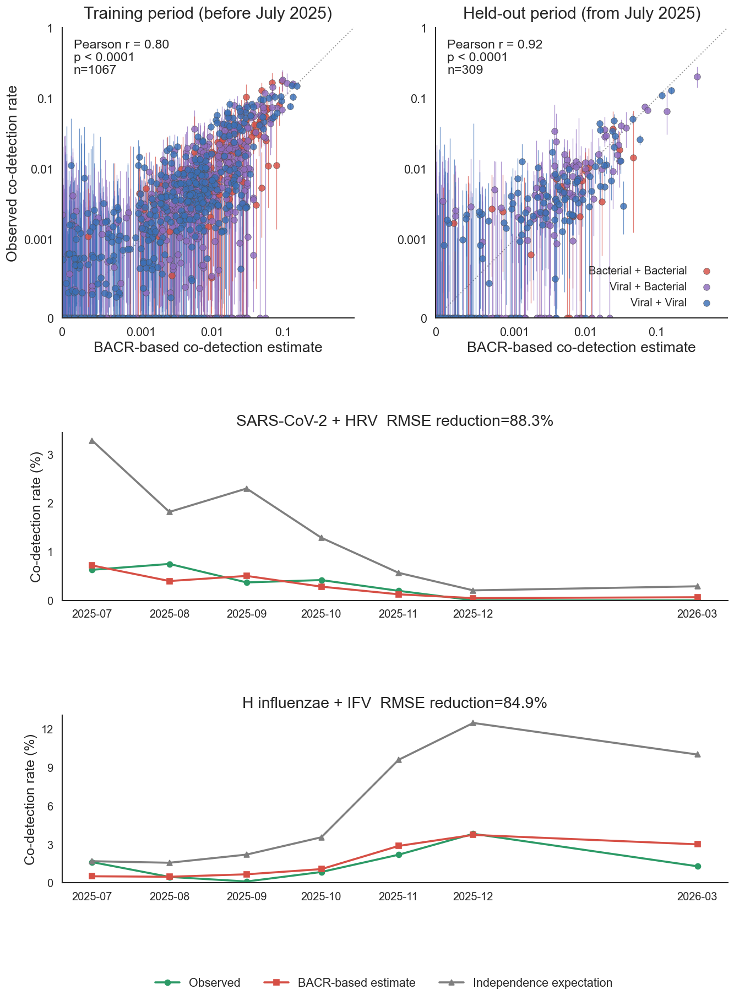

In [463]:
ACTIVE_FIGURE_LABEL = 'Figure_4_S6'

monthly_path = input_for('rti_plot_ai/coinfection_pred/results/02_monthly_pair_rates.csv', 'Figure_4_S6')
bacr_path = input_for('rti_plot_ai/coinfection_pred/results/03_train_bacr_summary.csv', 'Figure_4_S6')
test_path = input_for('rti_plot_ai/coinfection_pred/results/05_test_pair_predictions.csv', 'Figure_4_S6')
mapping_path = input_for('rti_plot_ai/01_population_level_times/pathogen_name_mapping.csv', 'Figure_4_S6')

monthly = pd.read_csv(monthly_path, parse_dates=['month'])
bacr = pd.read_csv(bacr_path)
test_pairs = pd.read_csv(test_path, parse_dates=['month'])
pathogen_map = pd.read_csv(mapping_path, dtype=str).fillna('')
family_by_pathogen = dict(zip(pathogen_map['Abbreviation'], pathogen_map['Family']))

# Match the source workflow: train only on qualified months and FDR-significant BACR pairs.
train = monthly.loc[monthly['split'].eq('train')].merge(
    bacr[['Pathogen A', 'Pathogen B', 'BACR', 'BACR valid', 'BACR FDR significant']],
    on=['Pathogen A', 'Pathogen B'], how='left',
)
train = train.loc[
    train['A tested'].gt(500) & train['B tested'].gt(500) & train['Both tested'].gt(50)
    & train['BACR valid'].fillna(False) & train['BACR FDR significant'].fillna(False)
].copy()
train['Predicted coinfection rate'] = train['P(A,t)*P(B,t)'] * train['BACR']
train['Observed coinfection rate qualified'] = train['Observed coinfection rate']

def pair_family(pathogen_a, pathogen_b):
    family_order = {'Viral': 0, 'Bacterial': 1, 'Fungi': 2}
    families = [family_by_pathogen.get(pathogen_a, 'Other'), family_by_pathogen.get(pathogen_b, 'Other')]
    return ' + '.join(sorted(families, key=lambda family: family_order.get(family, 99)))

train['Pair family'] = [pair_family(a, b) for a, b in zip(train['Pathogen A'], train['Pathogen B'])]
test_pairs = test_pairs.dropna(subset=['Predicted coinfection rate', 'Observed coinfection rate qualified']).copy()

# Preserve the original plotting notebook's posterior interval calculation for observed rates.
def add_beta_interval(frame, draws=1000, seed=20260918):
    frame = frame.copy()
    rng = np.random.default_rng(seed)
    intervals = []
    for positives, tested in zip(frame['Both positive'], frame['Both tested']):
        if not np.isfinite(positives) or not np.isfinite(tested) or tested <= 0 or positives < 0 or positives > tested:
            intervals.append((np.nan, np.nan))
            continue
        samples = rng.beta(positives + 0.5, tested - positives + 0.5, size=draws)
        intervals.append((np.quantile(samples, 0.025), np.quantile(samples, 0.975)))
    frame['Observed CI low'] = [x[0] for x in intervals]
    frame['Observed CI high'] = [x[1] for x in intervals]
    return frame

train = add_beta_interval(train)
test_pairs = add_beta_interval(test_pairs)
family_colors = {
    'Bacterial + Bacterial': '#D64F45',
    'Viral + Bacterial': '#8E6BBE',
    'Viral + Viral': '#3B6FB6',
    'Fungi + Fungi': '#2C9A66',
    'Viral + Fungi': '#E69F00',
    'Bacterial + Fungi': '#56B4E9',
}

fig = plt.figure(figsize=(13, 16.8), facecolor='white')
grid = fig.add_gridspec(3, 2, height_ratios=[1.42, 0.82, 0.82], hspace=0.55, wspace=0.28)

for ax, frame, title in [
    (fig.add_subplot(grid[0, 0]), train, 'Training period (before July 2025)'),
    (fig.add_subplot(grid[0, 1]), test_pairs, 'Held-out period (from July 2025)'),
]:
    x = frame['Predicted coinfection rate'].to_numpy(dtype=float)
    y = frame['Observed coinfection rate qualified'].to_numpy(dtype=float)
    y_low = frame['Observed CI low'].to_numpy(dtype=float)
    y_high = frame['Observed CI high'].to_numpy(dtype=float)
    for xi, low, high, family in zip(x, y_low, y_high, frame['Pair family']):
        ax.vlines(xi, low, high, color=family_colors.get(family, '#7F7F7F'), alpha=0.72, linewidth=0.8, zorder=1)
    for family, group in frame.groupby('Pair family', sort=False):
        ax.scatter(
            group['Predicted coinfection rate'], group['Observed coinfection rate qualified'],
            s=48, color=family_colors.get(family, '#7F7F7F'), edgecolor='#4D4D4D',
            linewidth=0.45, alpha=0.82, label=family, zorder=2,
        )
    valid = frame.dropna(subset=['Predicted coinfection rate', 'Observed coinfection rate qualified'])
    r, p_value = pearsonr(valid['Predicted coinfection rate'], valid['Observed coinfection rate qualified'])
    p_label = 'p < 0.0001' if p_value < 0.0001 else f'p={p_value:.2g}'
    ax.text(0.04, 0.96, f'Pearson r = {r:.2f}\n{p_label}\nn={len(valid)}', transform=ax.transAxes, ha='left', va='top', fontsize=14)
    ax.plot([0, 1], [0, 1], color='#999999', linestyle=':', linewidth=1.2, zorder=0)
    ax.set_xscale('symlog', linthresh=0.001)
    ax.set_yscale('symlog', linthresh=0.001)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ticks = [0, 0.001, 0.01, 0.1, 1]
    ax.set_xticks(ticks[:-1], labels=['0', '0.001', '0.01', '0.1'])
    ax.set_yticks(ticks, labels=['0', '0.001', '0.01', '0.1', '1'])
    ax.set_title(title, fontsize=18, pad=10)
    ax.set_xlabel('BACR-based co-detection estimate', fontsize=16)
    ax.tick_params(axis='both', labelsize=13)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)

axes_top = fig.axes[:2]
axes_top[0].set_ylabel('Observed co-detection rate', fontsize=16)
handles, labels = axes_top[1].get_legend_handles_labels()
axes_top[1].legend(handles, labels, frameon=False, loc='lower right', fontsize=12, markerfirst=False)

# Reuse the source notebook's three-series monthly pair curves and RMSE-improvement annotation.
representatives = [
    ('COVID-19', 'HRV', 'SARS-CoV-2 + HRV'),
    ('H. influenzae', 'IFV', 'H influenzae + IFV'),
]
for row, (pathogen_a, pathogen_b, display_name) in enumerate(representatives, start=1):
    ax = fig.add_subplot(grid[row, :])
    group = test_pairs.loc[
        test_pairs['Pathogen A'].eq(pathogen_a) & test_pairs['Pathogen B'].eq(pathogen_b)
    ].sort_values('month').copy()
    baseline_rmse = np.sqrt(np.mean((group['P(A,t)*P(B,t)'] - group['Observed coinfection rate qualified']) ** 2))
    bacr_rmse = np.sqrt(np.mean((group['Predicted coinfection rate'] - group['Observed coinfection rate qualified']) ** 2))
    rmse_reduction = (baseline_rmse - bacr_rmse) / baseline_rmse * 100
    ax.plot(group['month'], group['Observed coinfection rate qualified'] * 100, color='#2C9A66', marker='o', linewidth=2.2, markersize=6, label='Observed')
    ax.plot(group['month'], group['Predicted coinfection rate'] * 100, color='#D64F45', marker='s', linewidth=2.2, markersize=6, label='BACR-based estimate')
    ax.plot(group['month'], group['P(A,t)*P(B,t)'] * 100, color='#7F7F7F', marker='^', linewidth=2.2, markersize=6, label='Independence expectation')
    ax.set_title(f'{display_name}  RMSE reduction={rmse_reduction:.1f}%', fontsize=17, pad=8)
    ax.set_ylabel('Co-detection rate (%)', fontsize=15)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.set_xticks(group['month'])
    ax.set_xticklabels(group['month'].dt.strftime('%Y-%m'), rotation=0, ha='center')
    ax.tick_params(axis='both', labelsize=12)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)

handles, labels = fig.axes[-1].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=13, loc='lower center', ncol=3, bbox_to_anchor=(0.5, 0.005))
plt.show()


### Figure_5 · sequential detection and clinical outcomes


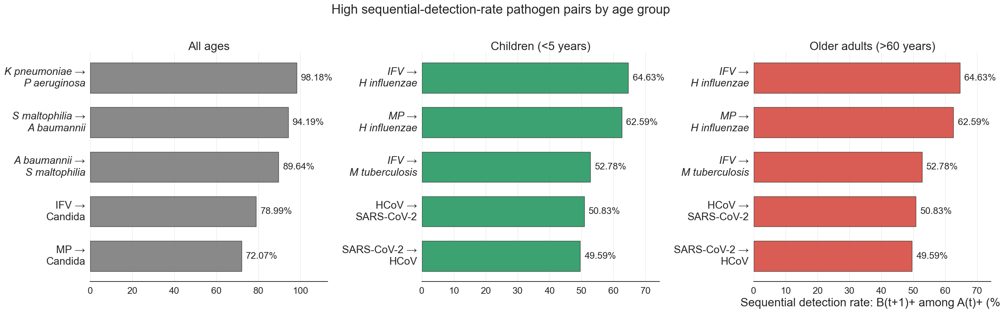

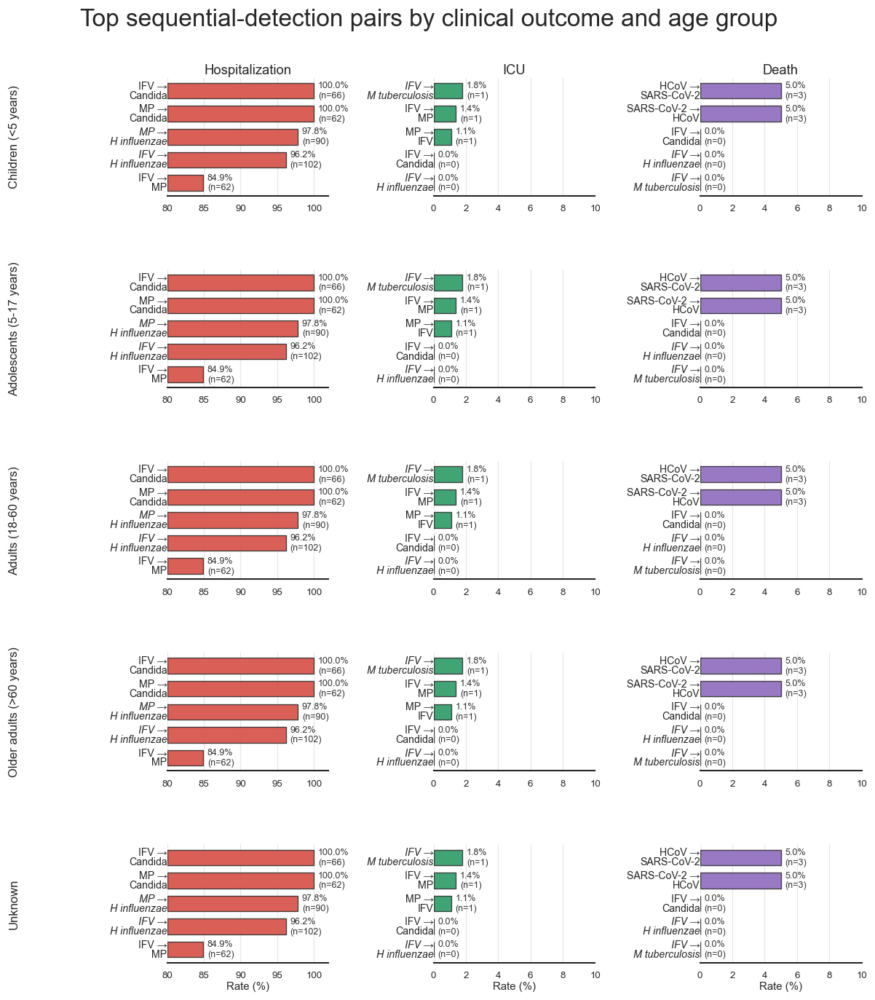

In [464]:
matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

SCRIPT_DIR = BundleDirectory('rti_plot_ai/sequential_detection', 'Figure_5_S7')
CLINICAL_ROOT = SCRIPT_DIR / 'clinical_outcomes'
OUTPUT_ROOT = output_dir('Figure_5')
SUPPLEMENTARY_OUTPUT_ROOT = output_dir('Figure_S7')

AGE_GROUPS = [
    ('Children (<5 years)', SCRIPT_DIR / 'age_stratified' / 'children_under_5'),
    ('Adolescents (5-17 years)', SCRIPT_DIR / 'age_stratified' / 'adolescents_5_17'),
    ('Adults (18-60 years)', SCRIPT_DIR / 'age_stratified' / 'adults_18_60'),
    ('Older adults (>60 years)', SCRIPT_DIR / 'age_stratified' / 'older_adults_over_60'),
    ('Unknown', SCRIPT_DIR / 'age_stratified' / 'unknown'),
]
ALL_AGE_GROUP = ('All ages', SCRIPT_DIR)
SEQUENTIAL_AGE_GROUPS = [ALL_AGE_GROUP, *AGE_GROUPS]
MAIN_SEQUENTIAL_GROUPS = [ALL_AGE_GROUP, AGE_GROUPS[0], AGE_GROUPS[3]]
SUPPLEMENTARY_SEQUENTIAL_GROUPS = [AGE_GROUPS[1], AGE_GROUPS[2], AGE_GROUPS[4]]
AGE_COLORS = {
    'All ages': '#7F7F7F',
    'Children (<5 years)': '#2C9A66',
    'Adolescents (5-17 years)': '#3B6FB6',
    'Adults (18-60 years)': '#8E6BBE',
    'Older adults (>60 years)': '#D64F45',
    'Unknown': '#56B4E9',
}
OUTCOMES = [
    ('lrti', 'LRTI', '#3B6FB6', 70),
    ('hospitalization', 'Hospitalization', '#D64F45', 80),
    ('icu', 'ICU', '#2C9A66', 0),
    ('death', 'Death', '#8E6BBE', 0),
]
PLOT_OUTCOMES = OUTCOMES[1:]
MIN_PREVIOUS_POSITIVE = 100
MIN_OUTCOME_DENOMINATOR = 50
TOP_N = 5

BACTERIAL_PATHOGENS = {
    'B pertussis', 'H influenzae', 'K pneumoniae', 'Legionella',
    'M catarrhalis', 'M tuberculosis', 'P aeruginosa', 'S aureus',
    'S maltophilia', 'S pneumoniae', 'A baumannii',
}
PATHOGEN_REPLACEMENTS = {
    'COVID-19': 'SARS-CoV-2',
    'SARS-COV-2': 'SARS-CoV-2',
    'B. pertussis': 'B pertussis',
    'H. influenzae': 'H influenzae',
    'K. pneumoniae': 'K pneumoniae',
    'M. catarrhalis': 'M catarrhalis',
    'M. tuberculosis': 'M tuberculosis',
    'P. aeruginosa': 'P aeruginosa',
    'S. aureus': 'S aureus',
    'S. maltophilia': 'S maltophilia',
    'S. pneumoniae': 'S pneumoniae',
    'A. baumannii': 'A baumannii',
}

def apply_style():
    plt.rcParams.update({
        'font.family': 'Arial',
        'font.size': 14,
        'axes.labelsize': 16,
        'axes.titlesize': 18,
        'xtick.labelsize': 14,
        'ytick.labelsize': 14,
        'figure.dpi': 120,
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
    })
    sns.set_theme(style='white', rc={'font.family': 'Arial', 'font.size': 14})

def normalize_pathogen(value: str) -> str:
    value = str(value)
    for old, new in PATHOGEN_REPLACEMENTS.items():
        value = value.replace(old, new)
    return value

def format_pair(previous: str, next_pathogen: str) -> str:
    previous = normalize_pathogen(previous)
    next_pathogen = normalize_pathogen(next_pathogen)
    return f'{previous} →\n{next_pathogen}'

def pair_has_bacterium(previous: str, next_pathogen: str) -> bool:
    return normalize_pathogen(previous) in BACTERIAL_PATHOGENS or normalize_pathogen(next_pathogen) in BACTERIAL_PATHOGENS

def load_sequential_rate_table(directory: Path, age_group: str) -> pd.DataFrame:
    df = pd.read_csv(directory / 'sequential_detection_or_stats.csv')
    numeric = [
        'a_prev_A_positive_next_B_positive',
        'prev_A_positive_pairs',
        'next_B_positive_rate_given_prev_A_positive',
    ]
    for column in numeric:
        df[column] = pd.to_numeric(df[column], errors='coerce')
    df = df.loc[
        df['prev_A_positive_pairs'].gt(MIN_PREVIOUS_POSITIVE)
        & df['next_B_positive_rate_given_prev_A_positive'].notna()
        & df['previous_pathogen_a'].ne(df['next_pathogen_b'])
    ].copy()
    df['Age group'] = age_group
    df['Pair'] = df.apply(
        lambda row: format_pair(row['previous_pathogen_a'], row['next_pathogen_b']),
        axis=1,
    )
    df['Rate (%)'] = 100 * df['next_B_positive_rate_given_prev_A_positive']
    return df.sort_values(
        ['Rate (%)', 'a_prev_A_positive_next_B_positive', 'Pair'],
        ascending=[False, False, True],
    ).head(TOP_N).copy()

def select_sequential_rates() -> pd.DataFrame:
    records = [
        load_sequential_rate_table(directory, age_group)
        for age_group, directory in SEQUENTIAL_AGE_GROUPS
    ]
    selected = pd.concat(records, ignore_index=True)
    selected['Rank'] = selected.groupby('Age group')['Rate (%)'].rank(
        method='first', ascending=False,
    ).astype(int)
    return selected

def plot_sequential_rates(
    selected: pd.DataFrame,
    age_groups: list[tuple[str, Path]],
    output_stem: str,
    title: str,
    figsize: tuple[float, float],
):
    fig, axes = plt.subplots(1, len(age_groups), figsize=figsize, sharex=False, squeeze=False)
    axes = axes.ravel()
    x_max = max(10, np.ceil(selected['Rate (%)'].max() / 10) * 10)

    for ax, (age_group, _) in zip(axes, age_groups):
        color = AGE_COLORS[age_group]
        sub = selected.loc[selected['Age group'].eq(age_group)].sort_values('Rate (%)')
        y = np.arange(len(sub))
        bars = ax.barh(
            y, sub['Rate (%)'], color=color, alpha=0.92,
            edgecolor='#2F2F2F', linewidth=0.8, height=0.68,
        )
        ax.set_yticks(y)
        ax.set_yticklabels([])
        for yi, (_, row) in zip(y, sub.iterrows()):
            ax.text(
                -0.02, yi, row['Pair'], transform=ax.get_yaxis_transform(),
                ha='right', va='center', fontsize=18, fontname='Arial',
                fontstyle='italic' if pair_has_bacterium(row['previous_pathogen_a'], row['next_pathogen_b']) else 'normal',
                linespacing=1.25, clip_on=False,
            )
        panel_max = max(1, sub['Rate (%)'].max() * 1.15)
        ax.set_xlim(0, panel_max)
        ax.grid(axis='x', color='#E6E6E6', linewidth=0.7)
        ax.set_axisbelow(True)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.tick_params(axis='y', length=0)
        ax.tick_params(axis='x', labelsize=16)
        ax.set_title(age_group, fontsize=20, pad=4)
        for bar, (_, row) in zip(bars, sub.iterrows()):
            ax.text(
                row['Rate (%)'] + panel_max * 0.018,
                bar.get_y() + bar.get_height() / 2,
                f"{row['Rate (%)']:.2f}%",
                va='center', ha='left', fontsize=16,
            )

    axes[-1].set_xlabel('Sequential detection rate: B(t+1)+ among A(t)+ (%)', fontsize=20)
    fig.suptitle(title, fontsize=22, y=0.995)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
def load_outcome_table(directory: Path, age_group: str, outcome: str) -> pd.DataFrame:
    df = pd.read_csv(directory / f'{outcome}_outcome_or_stats.csv')
    numeric = [
        'a_A_positive_B_positive_outcome_positive',
        'A_positive_B_positive_n',
        'outcome_rate_after_B_positive',
    ]
    for column in numeric:
        df[column] = pd.to_numeric(df[column], errors='coerce')
    df = df.loc[
        df['A_positive_B_positive_n'].gt(MIN_OUTCOME_DENOMINATOR)
        & df['outcome_rate_after_B_positive'].notna()
        & df['previous_pathogen_a'].ne(df['next_pathogen_b'])
    ].copy()
    df['Age group'] = age_group
    df['Outcome'] = outcome
    df['Pair'] = df.apply(
        lambda row: format_pair(row['previous_pathogen_a'], row['next_pathogen_b']),
        axis=1,
    )
    df['Rate (%)'] = 100 * df['outcome_rate_after_B_positive']
    return df.sort_values(
        ['Rate (%)', 'a_A_positive_B_positive_outcome_positive', 'Pair'],
        ascending=[False, False, True],
    ).head(TOP_N).copy()

def load_all_outcome_rates() -> pd.DataFrame:
    records = []
    for age_group, _ in AGE_GROUPS:
        directory = CLINICAL_ROOT / 'age_stratified' / {
            'Children (<5 years)': 'children_under_5',
            'Adolescents (5-17 years)': 'adolescents_5_17',
            'Adults (18-60 years)': 'adults_18_60',
            'Older adults (>60 years)': 'older_adults_over_60',
            'Unknown': 'unknown',
        }[age_group]
        for outcome, _, _, _ in OUTCOMES:
            records.append(load_outcome_table(directory, age_group, outcome))
    return pd.concat(records, ignore_index=True)

def load_single_age_outcome_rates(directory: Path, age_group: str) -> pd.DataFrame:
    return pd.concat(
        [load_outcome_table(directory, age_group, outcome) for outcome, _, _, _ in OUTCOMES],
        ignore_index=True,
    )

def outcome_axis_limit(outcome: str, selected: pd.DataFrame) -> tuple[float, float]:
    default_minimum = next(item[3] for item in OUTCOMES if item[0] == outcome)
    if selected.empty:
        return default_minimum, default_minimum + 10
    minimum = max(0, min(default_minimum, np.floor(selected['Rate (%)'].min() / 5) * 5))
    maximum = selected['Rate (%)'].max()
    return minimum, max(minimum + 10, np.ceil(maximum / 5) * 5 + 2)

def draw_outcome_panel(ax, sub: pd.DataFrame, outcome: str):
    minimum, maximum = outcome_axis_limit(outcome, sub)
    color = next(item[2] for item in OUTCOMES if item[0] == outcome)
    sub = sub.sort_values('Rank', ascending=False)
    y = np.arange(len(sub))
    bars = ax.barh(
        y, sub['Rate (%)'] - minimum, left=minimum, color=color, alpha=0.90,
        edgecolor='#2F2F2F', linewidth=0.8, height=0.68,
    )
    ax.set_yticks(y)
    ax.set_yticklabels([])
    for yi, (_, row) in zip(y, sub.iterrows()):
        ax.text(
            0, yi, row['Pair'], transform=ax.get_yaxis_transform(),
            ha='right', va='center', fontsize=8.5, fontname='Arial',
            fontstyle='italic' if pair_has_bacterium(row['previous_pathogen_a'], row['next_pathogen_b']) else 'normal',
            linespacing=0.9, clip_on=False,
        )
    ax.set_xlim(minimum, maximum)
    ax.grid(axis='x', color='#E6E6E6', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.tick_params(axis='x', labelsize=8, pad=1)
    for bar, (_, row) in zip(bars, sub.iterrows()):
        ax.text(
            row['Rate (%)'] + (maximum - minimum) * 0.025,
            bar.get_y() + bar.get_height() / 2,
            f"{row['Rate (%)']:.1f}%\n(n={int(row['a_A_positive_B_positive_outcome_positive'])})",
            va='center', ha='left', fontsize=7.5, color='#333333',
        )

def plot_outcome_rates(selected: pd.DataFrame):
    fig, axes = plt.subplots(len(AGE_GROUPS), len(PLOT_OUTCOMES), figsize=(10.0, 12.2), squeeze=False)
    for row_index, (age_group, _) in enumerate(AGE_GROUPS):
        for column_index, (outcome, label, _, _) in enumerate(PLOT_OUTCOMES):
            ax = axes[row_index, column_index]
            sub = selected.loc[
                selected['Age group'].eq(age_group) & selected['Outcome'].eq(outcome)
            ].copy()
            draw_outcome_panel(ax, sub, outcome)
            if row_index == 0:
                ax.set_title(label, fontsize=11, pad=3)
            if row_index == len(AGE_GROUPS) - 1:
                ax.set_xlabel('Rate (%)', fontsize=9, labelpad=1)
    fig.subplots_adjust(left=0.20, right=0.995, top=0.93, bottom=0.10, wspace=0.65, hspace=0.62)
    for row_index, (age_group, _) in enumerate(AGE_GROUPS):
        position = axes[row_index, 0].get_position()
        fig.text(0.025, position.y0 + position.height / 2, age_group, rotation=90, ha='center', va='center', fontsize=10)
    fig.suptitle('Top sequential-detection pairs by clinical outcome and age group', fontsize=20, y=0.995)
    plt.show()
def plot_all_age_outcome_rates(selected: pd.DataFrame):
    fig, axes = plt.subplots(1, len(PLOT_OUTCOMES), figsize=(10.0, 3.1), squeeze=False)
    for column_index, (outcome, label, _, _) in enumerate(PLOT_OUTCOMES):
        ax = axes[0, column_index]
        sub = selected.loc[selected['Outcome'].eq(outcome)].copy()
        draw_outcome_panel(ax, sub, outcome)
        ax.set_title(label, fontsize=11, pad=3)
        ax.set_xlabel('Rate (%)', fontsize=9, labelpad=1)
    fig.subplots_adjust(left=0.20, right=0.995, top=0.80, bottom=0.22, wspace=0.95)
    fig.suptitle('Top sequential-detection pairs by clinical outcome: all ages', fontsize=16, y=0.98)
    plt.show()
apply_style()
sequential = select_sequential_rates()
plot_sequential_rates(
    sequential,
    MAIN_SEQUENTIAL_GROUPS,
    '08_top_sequential_detection_rate_pairs_by_age',
    'High sequential-detection-rate pathogen pairs by age group',
    (24, 7.5),
)
outcomes = load_all_outcome_rates()
outcomes['Rank'] = outcomes.groupby(['Age group', 'Outcome'])['Rate (%)'].rank(method='first', ascending=False).astype(int)
all_age_outcomes = load_single_age_outcome_rates(CLINICAL_ROOT, 'All ages')
all_age_outcomes['Rank'] = all_age_outcomes.groupby('Outcome')['Rate (%)'].rank(method='first', ascending=False).astype(int)
plot_outcome_rates(outcomes)


### Figure_6 · directional association matrix and clinical-outcome forest plots


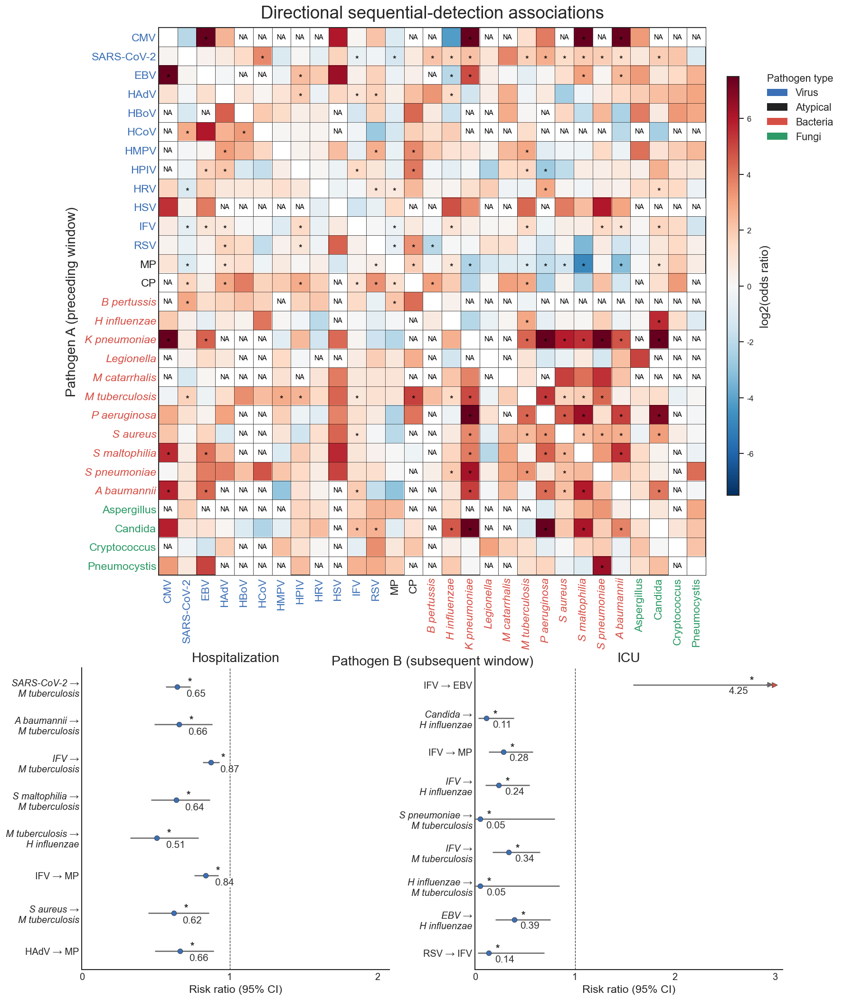

In [465]:
ACTIVE_FIGURE_LABEL = 'Figure_6'
OUT_DIR = output_dir('Figure_6')

# Reproduce the all-age sequential-detection OR matrix used in the reference PDF.
or_path = input_for('rti_plot_ai/sequential_detection/sequential_detection_or_matrix.csv', 'Figure_6')
fdr_path = input_for('rti_plot_ai/sequential_detection/sequential_detection_or_fdr_matrix.csv', 'Figure_6')
or_matrix = pd.read_csv(or_path, index_col=0).apply(pd.to_numeric, errors='coerce')
fdr_matrix = pd.read_csv(fdr_path, index_col=0).apply(pd.to_numeric, errors='coerce')

pathogen_order = [
    'CMV', 'SARS-CoV-2', 'EBV', 'HAdV', 'HBoV', 'HCoV', 'HMPV', 'HPIV', 'HRV', 'HSV', 'IFV', 'RSV',
    'MP', 'CP', 'B pertussis', 'H influenzae', 'K pneumoniae', 'Legionella', 'M catarrhalis',
    'M tuberculosis', 'P aeruginosa', 'S aureus', 'S maltophilia', 'S pneumoniae', 'A baumannii',
    'Aspergillus', 'Candida', 'Cryptococcus', 'Pneumocystis',
]
pathogen_replacements = {
    'COVID-19': 'SARS-CoV-2', 'SARS-COV-2': 'SARS-CoV-2', 'B. pertussis': 'B pertussis',
    'H. influenzae': 'H influenzae', 'K. pneumoniae': 'K pneumoniae', 'M. catarrhalis': 'M catarrhalis',
    'M. tuberculosis': 'M tuberculosis', 'P. aeruginosa': 'P aeruginosa', 'S. aureus': 'S aureus',
    'S. maltophilia': 'S maltophilia', 'S. pneumoniae': 'S pneumoniae', 'A. baumannii': 'A baumannii',
}
def normalize_pathogen(name):
    return pathogen_replacements.get(name, name)

or_matrix = or_matrix.rename(index=normalize_pathogen, columns=normalize_pathogen).reindex(index=pathogen_order, columns=pathogen_order)
fdr_matrix = fdr_matrix.rename(index=normalize_pathogen, columns=normalize_pathogen).reindex(index=pathogen_order, columns=pathogen_order)
log2_or = np.log2(or_matrix.where(or_matrix > 0)).replace([np.inf, -np.inf], np.nan)

virus_order = pathogen_order[:12]
atypical_order = pathogen_order[12:14]
bacteria_order = pathogen_order[14:25]
fungi_order = pathogen_order[25:]
type_colors = {'Virus': '#3B6FB6', 'Atypical': '#222222', 'Bacteria': '#D64F45', 'Fungi': '#2C9A66'}
label_colors = {name: type_colors['Virus'] for name in virus_order}
label_colors.update({name: type_colors['Atypical'] for name in atypical_order})
label_colors.update({name: type_colors['Bacteria'] for name in bacteria_order})
label_colors.update({name: type_colors['Fungi'] for name in fungi_order})

# Layout follows the reference: large all-age matrix above the two outcome forests.
fig = plt.figure(figsize=(15, 21.6), facecolor='white')
heat_ax = fig.add_axes([0.19, 0.425, 0.64, 0.445])
heat_ax.imshow(log2_or.to_numpy(dtype=float), cmap='RdBu_r', vmin=-7.5, vmax=7.5, aspect='equal', interpolation='none')
heat_ax.set_xticks(np.arange(len(pathogen_order)))
heat_ax.set_xticklabels(pathogen_order, rotation=90, ha='center', va='top', fontsize=14)
heat_ax.set_yticks(np.arange(len(pathogen_order)))
heat_ax.set_yticklabels(pathogen_order, fontsize=14)
for tick in heat_ax.get_xticklabels() + heat_ax.get_yticklabels():
    label = tick.get_text()
    if label == 'M tuberculosis':
        tick.set_text('MTB')
    tick.set_color(label_colors.get(label, '#333333'))
    if label in bacteria_order:
        tick.set_fontstyle('italic')
heat_ax.tick_params(axis='both', length=0, pad=3)
heat_ax.set_xticks(np.arange(-0.5, len(pathogen_order), 1), minor=True)
heat_ax.set_yticks(np.arange(-0.5, len(pathogen_order), 1), minor=True)
heat_ax.grid(which='minor', color='black', linewidth=0.35)
heat_ax.tick_params(which='minor', bottom=False, left=False)
heat_ax.set_xlim(-0.5, len(pathogen_order)-0.5)
heat_ax.set_ylim(len(pathogen_order)-0.5, -0.5)
heat_ax.set_xlabel('Pathogen B (subsequent window)', fontsize=17, labelpad=8)
heat_ax.set_ylabel('Pathogen A (preceding window)', fontsize=17, labelpad=8)
heat_ax.set_title('Directional sequential-detection associations', fontsize=22, pad=12)

missing = or_matrix.isna() | log2_or.isna()
for row in range(len(pathogen_order)):
    for col in range(len(pathogen_order)):
        if row == col:
            heat_ax.add_patch(Rectangle((col-0.5, row-0.5), 1, 1, facecolor='white', edgecolor='black', linewidth=0.35, zorder=3))
        elif missing.iloc[row, col]:
            heat_ax.add_patch(Rectangle((col-0.5, row-0.5), 1, 1, facecolor='white', edgecolor='black', linewidth=0.35, zorder=3))
            heat_ax.text(col, row, 'NA', ha='center', va='center', fontsize=8.5, color='black', zorder=4)
        elif pd.notna(fdr_matrix.iloc[row, col]) and fdr_matrix.iloc[row, col] < 0.05:
            heat_ax.text(col, row + 0.18, '*', ha='center', va='center', fontsize=12, color='black', zorder=4)

cbar_ax = fig.add_axes([0.855, 0.49, 0.014, 0.34])
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(-7.5, 7.5), cmap='RdBu_r'), cax=cbar_ax)
cbar.set_label('log2(odds ratio)', fontsize=15, labelpad=8)
cbar.ax.tick_params(labelsize=10)
legend_handles = [Patch(facecolor=color, edgecolor='none', label=label) for label, color in type_colors.items()]
fig.legend(handles=legend_handles, title='Pathogen type', loc='upper right', bbox_to_anchor=(0.99, 0.84), frameon=False, fontsize=13, title_fontsize=13)

# The reference forest panels use the 8 hospitalization and 9 ICU estimates.
forest_path = input_for('rti_plot_ai/sequential_detection/clinical_outcome_forest_all_age/all_age_directional_clinical_outcome_rr.csv', 'Figure_6')
rr = pd.read_csv(forest_path)
for col in ['risk_ratio', 'rr_ci_low', 'rr_ci_high', 'fdr_q_value', 'sequential_q_value', 'sequential_odds_ratio']:
    rr[col] = pd.to_numeric(rr[col], errors='coerce')
forest_specs = [('hospitalization', 'Hospitalization', 0.10, 0.36, 2.0), ('icu', 'ICU', 0.56, 0.36, 3.0)]
for outcome, title, left, width, xmax in forest_specs:
    ax = fig.add_axes([left, 0.105, width, 0.245])
    sub = rr.loc[rr['outcome'].eq(outcome)].copy()
    sub['direction_order'] = np.where(sub['risk_ratio'] > 1, 0, 1)
    sub = sub.sort_values(['direction_order', 'fdr_q_value', 'eligible_pairs'], ascending=[True, True, False]).reset_index(drop=True)
    colors = np.where(sub['risk_ratio'].to_numpy() > 1, '#D64F45', '#3B6FB6')
    y = np.arange(len(sub), dtype=float)
    for i, row in sub.iterrows():
        yy = y[i]
        low = max(0, min(xmax, row['rr_ci_low']))
        high = max(0, min(xmax, row['rr_ci_high']))
        if high >= low:
            ax.hlines(yy, low, high, color='#666666', linewidth=1.5, zorder=1)
        if row['rr_ci_high'] > xmax:
            ax.annotate('', xy=(xmax, yy), xytext=(xmax-0.10, yy), arrowprops={'arrowstyle':'-|>', 'color':'#666666', 'linewidth':1.2}, zorder=2)
        if row['risk_ratio'] > xmax:
            ax.scatter(xmax, yy, marker='>', s=45, facecolor=colors[i], edgecolor='#333333', linewidth=0.5, zorder=3)
            value_x = xmax - 0.46
        else:
            ax.scatter(row['risk_ratio'], yy, marker='o', s=40, facecolor=colors[i], edgecolor='#333333', linewidth=0.5, zorder=3)
            value_x = min(max(row['risk_ratio'] + 0.06, 0.10), xmax - 0.18)
        ax.text(value_x, yy + 0.19, f"{row['risk_ratio']:.2f}", fontsize=12.5, color='#333333', va='center', ha='left', bbox={'facecolor':'white', 'edgecolor':'none', 'pad':0.3}, zorder=4)
        star_x = min(row['risk_ratio'] + max(0.07, 0.05 * row['risk_ratio']), xmax - 0.12)
        if row['risk_ratio'] > xmax:
            star_x = xmax - 0.25
        ax.text(star_x, yy - 0.13, '*', fontsize=13, fontweight='bold', color='#222222', va='center', ha='left', zorder=4)
    ax.axvline(1.0, color='#333333', linestyle='--', linewidth=0.8, zorder=0)
    ax.set_xlim(0, xmax + 0.08)
    ax.set_xticks([0, 1, 2] if outcome == 'hospitalization' else [0, 1, 2, 3])
    ax.set_yticks(y)
    labels = []
    for row in sub.itertuples(index=False):
        a, b = row.pair.split(' → ')
        a, b = normalize_pathogen(a), normalize_pathogen(b)
        if a in bacteria_order or b in bacteria_order:
            labels.append(f'{a} →\n{b}')
        else:
            labels.append(f'{a} → {b}')
    ax.set_yticklabels(labels, fontsize=12.5)
    for tick, row in zip(ax.get_yticklabels(), sub.itertuples(index=False)):
        tick.set_horizontalalignment('right')
        tick.set_multialignment('right')
        a, b = row.pair.split(' → ')
        if normalize_pathogen(a) in bacteria_order or normalize_pathogen(b) in bacteria_order:
            tick.set_fontstyle('italic')
    ax.invert_yaxis()
    ax.set_ylim(len(sub)-0.5, -0.5)
    ax.set_xlabel('Risk ratio (95% CI)', fontsize=14)
    ax.set_title(title, fontsize=17, pad=8)
    ax.tick_params(axis='both', length=0, labelsize=12)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)
plt.show()
plt.show()


### Figure_S1 · geographical distribution


Skipping field center: unsupported OGR type: 3
Skipping field centroid: unsupported OGR type: 3
Skipping field acroutes: unsupported OGR type: 1


Skipping field center: unsupported OGR type: 3
Skipping field centroid: unsupported OGR type: 3
Skipping field acroutes: unsupported OGR type: 1


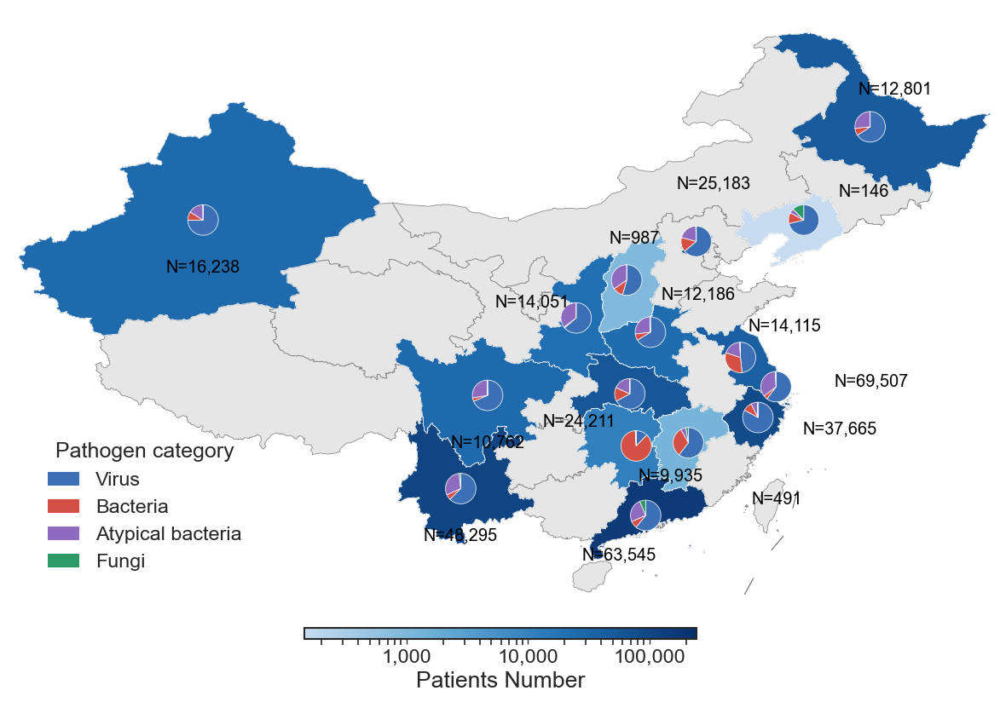

In [466]:
ACTIVE_FIGURE_LABEL = 'Figure_S1'
OUT_DIR = output_dir('Figure_S1')
geo_path = input_for('rti_plot_ai/100000_full.json', 'Figure_S1')
regions_path = input_for('rti_plot_ai/plot_paper/13_region_patient_positive_detections.csv', 'Figure_S1')
region_df = pd.read_csv(regions_path)
china = gpd.read_file(geo_path)
def render_region_map(region_table: pd.DataFrame, out_dir: Path):
    if not GEOJSON.exists():
        raise FileNotFoundError(f"China province boundary GeoJSON not found: {GEOJSON}")
    region_match = {
        "上海市": "上海", "云南省": "云南", "北京市": "北京", "四川省": "四川", "山西省": "山西",
        "广东省": "广东", "新疆维吾尔自治区": "新疆", "江苏省": "江苏", "江西省": "江西", "河南省": "河南",
        "浙江省": "浙江", "湖北省": "湖北", "湖南省": "湖南", "辽宁省": "辽宁", "陕西省": "陕西", "黑龙江省": "黑龙江",
    }
    china_map = gpd.read_file(GEOJSON)
    china_map["Region"] = china_map["name"].map(region_match)
    plot_map = china_map.merge(region_table[["Region", "Patients"]], on="Region", how="left")
    plot_map["Patients_plot"] = pd.to_numeric(plot_map["Patients"], errors="coerce").where(lambda x: x > 0)
    colors = ["#C6DBEF", "#6BAED6", "#2171B5", "#08306B"]
    cmap = mpl.colors.LinearSegmentedColormap.from_list("patient_blues", colors)
    valid = plot_map["Patients_plot"].dropna()
    norm = LogNorm(vmin=max(float(valid.min()), 1.0), vmax=float(valid.max()))
    category_order = ["Virus", "Bacteria", "Atypical", "Fungi"]
    category_colors = {"Virus": "#3B6FB6", "Bacteria": "#D64F45", "Atypical": "#8E6BBE", "Fungi": "#2C9A66"}
    category_labels = {"Virus": "Virus", "Bacteria": "Bacteria", "Atypical": "Atypical bacteria", "Fungi": "Fungi"}
    anchors = {
        "上海": (121.45, 31.15), "云南": (101.5, 24.7), "北京": (116.40, 40.35), "四川": (103.2, 30.6),
        "山西": (112.0, 37.9), "广东": (113.2, 23.0), "新疆": (85.2, 41.7), "江苏": (119.2, 33.0),
        "江西": (115.9, 27.6), "河南": (113.5, 34.6), "浙江": (120.3, 29.2), "湖北": (112.2, 30.7),
        "湖南": (112.6, 27.4), "辽宁": (123.2, 41.7), "陕西": (108.8, 35.5), "黑龙江": (127.4, 47.6),
    }
    label_positions = {
        "上海": (127.5, 31.5), "北京": (117.5, 44.0), "江苏": (122.0, 35.0), "浙江": (125.5, 28.5),
        "湖北": (109.0, 29.0), "湖南": (114.8, 25.5), "广东": (111.5, 20.5), "辽宁": (127.0, 43.5),
        "山西": (112.5, 40.5), "河南": (116.5, 37.0), "江西": (121.5, 24.0), "陕西": (106.0, 36.5),
        "黑龙江": (129.0, 50.0),
    }

    fig, ax = plt.subplots(figsize=(10, 10))
    plot_map.plot(ax=ax, color="#E6E6E6", edgecolor="grey", linewidth=0.45)
    plot_map.dropna(subset=["Patients_plot"]).plot(column="Patients_plot", ax=ax, cmap=cmap, norm=norm, edgecolor="white", linewidth=0.45)
    ax.set_xlim(73, 135)
    ax.set_ylim(18, 55)
    ax.set_aspect("equal", adjustable="box")
    ax.axis("off")
    pie_radius = 1.42 * 0.85
    for _, row in region_table.iterrows():
        region = row["Region"]
        x, y = anchors[region]
        values = row[category_order].to_numpy(dtype=float)
        pie_ax = ax.inset_axes([x - pie_radius, y - pie_radius, 2 * pie_radius, 2 * pie_radius], transform=ax.transData, zorder=8)
        if values.sum() > 0:
            pie_ax.pie(values, colors=[category_colors[c] for c in category_order], startangle=90, counterclock=False, wedgeprops={"edgecolor": "white", "linewidth": 0.45})
        else:
            pie_ax.pie([1], colors=["#F0F0F0"], startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 0.45})
        pie_ax.set_aspect("equal")
        pie_ax.axis("off")
        label_x, label_y = label_positions.get(region, (x, y - pie_radius - 1.75))
        ax.text(
            label_x, label_y, f"N={int(row['Total_Positive']):,}",
            ha="center", va="center", fontsize=12, color="black", zorder=10,
        )

    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.035, pad=0.035, aspect=35, shrink=0.4)
    cbar.set_label("Patients Number", fontsize=16, labelpad=4)
    ticks = [tick for tick in [100, 1_000, 10_000, 100_000, 250_000] if norm.vmin <= tick <= norm.vmax]
    if ticks:
        cbar.set_ticks(ticks)
    cbar.ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))
    cbar.ax.tick_params(labelsize=14, width=0.8, length=3.5)
    ax.legend(handles=[Patch(facecolor=category_colors[c], edgecolor="none", label=category_labels[c]) for c in category_order], loc="lower left", bbox_to_anchor=(0.02, 0.01), frameon=False, fontsize=14, handlelength=1.6, title="Pathogen category", title_fontsize=15)
    fig.patch.set_facecolor("white")
    fig.tight_layout()
    plt.show()
    return fig

GEOJSON = geo_path
region_map_fig = render_region_map(region_df, OUT_DIR)


In [467]:
ACTIVE_FIGURE_LABEL = 'Figure_S2'
OUT_DIR = output_dir('Figure_S2')


### Figure_S2 · panel A: overall pathogen positivity


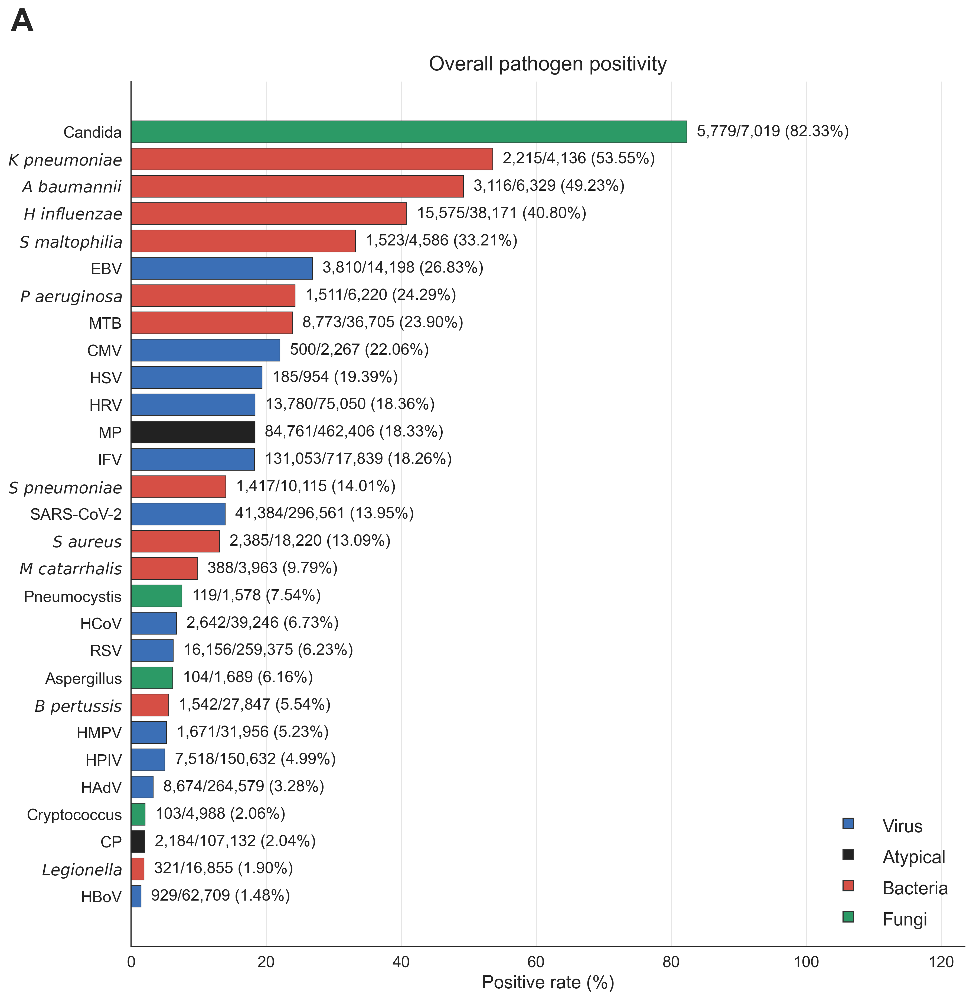

In [468]:
FIG3_DIR = rel('01_population_level_times')

ATYPICAL_PATHOGENS_FIG3 = {'MP', 'CP'}
NORTH_REGION_LABELS = {'Beijing', 'Heilongjiang', 'Shaanxi', 'Xinjiang', 'Henan', 'Liaoning', 'Shanxi'}
SOUTH_REGION_LABELS = {'Hubei', 'Yunnan', 'Sichuan', 'Shanghai', 'Guangdong', 'Jiangsu', 'Zhejiang', 'Hunan', 'Jiangxi'}

FIG3_TYPE_COLORS = {
    'Virus': NATURE_COLORS[0],
    'Atypical': '#222222',
    'Bacteria': NATURE_COLORS[1],
    'Fungi': NATURE_COLORS[2],
    'Other': NATURE_COLORS[6],
}
FIG3_TYPE_ORDER = {'Virus': 0, 'Atypical': 1, 'Bacteria': 2, 'Fungi': 3, 'Other': 9}

def figure3_pathogen_type_from_row(row):
    pathogen = str(row.get('Pathogen', ''))
    if pathogen in ATYPICAL_PATHOGENS_FIG3:
        return 'Atypical'
    text = str(row.get('Pathogen family', '')).replace(' pathogens', '').strip()
    if text in {'Viral', 'Virus'}:
        return 'Virus'
    if text in {'Bacterial', 'Bacteria'}:
        return 'Bacteria'
    if text in {'Fungi', 'Fungal'}:
        return 'Fungi'
    return 'Other'

def format_figure3_cell(positive, tested, rate):
    if pd.isna(rate) or pd.isna(positive) or pd.isna(tested) or tested <= 0:
        return ''
    return f'{int(round(positive)):,}/{int(round(tested)):,} ({float(rate):.2f}%)'

def format_figure3_p(p):
    if pd.isna(p):
        return ''
    if p < 0.0001:
        return 'p<0.0001'
    return f'p={p:.2g}'

def pathogen_sort_key_for_figure3(pathogen):
    pathogen = str(pathogen)
    if pathogen in PATHOGEN_DISPLAY_ORDER:
        return (0, PATHOGEN_DISPLAY_ORDER.index(pathogen), pathogen)
    return (1, 999, pathogen)

def italic_label_for_pathogen(pathogen):
    pathogen = str(pathogen)
    if pathogen in BACTERIA_ITALIC_LABELS:
        safe_pathogen = pathogen.replace(' ', r'\ ')
        return '$\\it{' + safe_pathogen + '}$'
    return pathogen

def figure3_stratified_test(rows_df):
    test_df = rows_df.copy()
    test_df['Positive encounters'] = pd.to_numeric(test_df['Positive encounters'], errors='coerce').fillna(0)
    test_df['Tested encounters'] = pd.to_numeric(test_df['Tested encounters'], errors='coerce').fillna(0)
    test_df = test_df.loc[test_df['Tested encounters'] > 0].copy()
    if test_df['Stratum'].nunique() < 2:
        return np.nan, ''
    arr = np.column_stack([
        test_df['Positive encounters'].astype(int).to_numpy(),
        np.maximum(test_df['Tested encounters'].astype(int).to_numpy() - test_df['Positive encounters'].astype(int).to_numpy(), 0),
    ])
    if arr.sum() == 0 or arr.shape[0] < 2 or arr.shape[1] < 2 or (arr.sum(axis=1) == 0).any() or (arr.sum(axis=0) == 0).any():
        return np.nan, ''
    if arr.shape == (2, 2) and (arr < 5).any():
        _, p = fisher_exact(arr)
        return float(p), 'Fisher'
    _, p, _, _ = chi2_contingency(arr)
    return float(p), 'Chi-square'

# -----------------------------
# Overall distribution as a bar plot
# -----------------------------
# Recalculate each pathogen's overall positivity from the latest URTI/LRTI table.

FIG3_TABLE_PATH = input_for('rti_plot_ai/plot_paper/11_pathogen_positivity_urti_lrti_table_values.csv', 'Figure_S2')
raw_fig3_table = pd.read_csv(FIG3_TABLE_PATH, encoding='utf-8-sig', dtype=str).fillna('')
FIG3_FAMILY_LABELS = {
    'Virus': ('Virus', 'Viral pathogens'),
    'Atypical bacteria': ('Atypical', 'Bacterial pathogens'),
    'Bacteria': ('Bacteria', 'Bacterial pathogens'),
    'Fungi': ('Fungi', 'Fungi pathogens'),
}

def parse_figure3_count_cell(value):
    match = re.fullmatch(r'\s*([\d,]+)/([\d,]+)\s*\(([\d.]+)%\)\s*', str(value))
    if not match:
        return np.nan, np.nan
    positive, tested, _ = match.groups()
    return int(positive.replace(',', '')), int(tested.replace(',', ''))

fig3_rows = []
current_type = ''
current_family = ''
for _, row in raw_fig3_table.iterrows():
    pathogen = str(row['Pathogen']).strip()
    if pathogen == 'All':
        continue
    if pathogen in FIG3_FAMILY_LABELS:
        current_type, current_family = FIG3_FAMILY_LABELS[pathogen]
        continue
    urti_positive, urti_tested = parse_figure3_count_cell(row['URTI'])
    lrti_positive, lrti_tested = parse_figure3_count_cell(row['LRTI'])
    if not np.isfinite(urti_positive) or not np.isfinite(urti_tested) or not np.isfinite(lrti_positive) or not np.isfinite(lrti_tested):
        continue
    positive = int(urti_positive + lrti_positive)
    tested = int(urti_tested + lrti_tested)
    rate = 100 * positive / tested if tested else np.nan
    fig3_rows.append({
        'Pathogen': pathogen,
        'Pathogen family': current_family,
        'Pathogen type': current_type,
        'Tested encounters': tested,
        'Positive encounters': positive,
        'Positive rate (%)': rate,
        'plot_label': f'{positive:,}/{tested:,} ({rate:.2f}%)' if tested else '',
    })

fig3_overall_df = pd.DataFrame(fig3_rows)
if fig3_overall_df.empty:
    raise ValueError(f'No pathogen rows with parseable rates in {FIG3_TABLE_PATH}')
fig3_overall_df = fig3_overall_df.sort_values(
    ['Positive rate (%)', 'Positive encounters'], ascending=[False, False]
).reset_index(drop=True)

plot_df = fig3_overall_df.copy()
fig_h = max(9.0, 0.36 * len(plot_df) + 2.0)
fig, ax = plt.subplots(figsize=(12.2, fig_h), dpi=300)
y = np.arange(len(plot_df))
bar_colors = [FIG3_TYPE_COLORS.get(t, NATURE_COLORS[6]) for t in plot_df['Pathogen type']]
rates = plot_df['Positive rate (%)'].to_numpy(dtype=float)
bars = ax.barh(y, rates, color=bar_colors, edgecolor='#333333', linewidth=0.55)
ax.set_yticks(y)
ax.set_yticklabels([italic_label_for_pathogen(p) for p in plot_df['Pathogen']], fontsize=14)
ax.invert_yaxis()
ax.set_xlabel('Positive rate (%)', fontsize=16)
ax.tick_params(axis='x', labelsize=14)
ax.set_title('Overall pathogen positivity', fontsize=18, pad=10)
xmax = max(5.0, float(np.nanmax(rates)) * 1.50)
ax.set_xlim(0, xmax)
for bar, label in zip(bars, plot_df['plot_label']):
    ax.text(bar.get_width() + xmax * 0.012, bar.get_y() + bar.get_height() / 2,
            label, va='center', ha='left', fontsize=14)
legend_order = ['Virus', 'Atypical', 'Bacteria', 'Fungi']
handles = [
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=FIG3_TYPE_COLORS[t],
               markeredgecolor='#333333', markersize=9)
    for t in legend_order if t in set(plot_df['Pathogen type'])
]
labels = [t for t in legend_order if t in set(plot_df['Pathogen type'])]
if handles:
    ax.legend(handles, labels, frameon=False, loc='lower right', fontsize=16,
              handlelength=2.2, handleheight=1.5)
nature_axes(ax, grid_axis='x')
fig.text(0.02, 0.99, 'A', fontsize=28, fontweight='bold', va='top')
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [469]:
ACTIVE_FIGURE_LABEL = 'Figure_S2'
OUT_DIR = output_dir('Figure_S2')


In [470]:
# -----------------------------
# Prepare stratified positivity summaries used by Figure S2B
# -----------------------------
def prepare_figure3_distribution(csv_name, region_binary=False):
    dist_df = normalize_pathogen_dataframe(pd.read_csv(FIG3_DIR / csv_name))
    for col in ['Tested encounters', 'Positive encounters', 'Positive rate (%)']:
        dist_df[col] = pd.to_numeric(dist_df[col], errors='coerce')
    if region_binary:
        dist_df['Region group'] = np.where(
            dist_df['Stratum'].isin(NORTH_REGION_LABELS),
            'North',
            np.where(dist_df['Stratum'].isin(SOUTH_REGION_LABELS), 'South', None),
        )
        dist_df = dist_df.loc[dist_df['Region group'].isin(['North', 'South'])].copy()
        group_cols = ['Pathogen zh', 'Pathogen', 'Pathogen family', 'Region group']
        dist_df = (
            dist_df.groupby(group_cols, as_index=False)[['Tested encounters', 'Positive encounters']]
            .sum()
        )
        dist_df['Stratification'] = 'region'
        dist_df['Stratum code'] = dist_df['Region group']
        dist_df['Stratum'] = dist_df['Region group']
        dist_df['Positive rate (%)'] = np.where(
            dist_df['Tested encounters'] > 0,
            dist_df['Positive encounters'] / dist_df['Tested encounters'] * 100,
            np.nan,
        )
    dist_df['Pathogen type'] = dist_df.apply(figure3_pathogen_type_from_row, axis=1)
    dist_df['cell_value'] = dist_df.apply(
        lambda row: format_figure3_cell(row['Positive encounters'], row['Tested encounters'], row['Positive rate (%)']),
        axis=1,
    )
    return dist_df

def build_figure3_distribution_table(csv_name, strat_order, output_prefix, title, fig_width=None, font_size=None, region_binary=False):
    dist_df = prepare_figure3_distribution(csv_name, region_binary=region_binary)
    available_strata = [s for s in strat_order if s in set(dist_df['Stratum'])]
    remaining_strata = [s for s in dist_df['Stratum'].dropna().unique().tolist() if s not in available_strata]
    available_strata += remaining_strata

    table_rows = []
    pathogen_info = (
        dist_df[['Pathogen', 'Pathogen type']]
        .drop_duplicates()
        .assign(
            family_rank=lambda d: d['Pathogen type'].map(lambda x: FIG3_TYPE_ORDER.get(x, 9)),
            pathogen_rank=lambda d: d['Pathogen'].map(pathogen_sort_key_for_figure3),
        )
        .sort_values(['family_rank', 'pathogen_rank'])
    )
    for _, pathogen_row in pathogen_info.iterrows():
        pathogen = pathogen_row['Pathogen']
        one = dist_df.loc[dist_df['Pathogen'].eq(pathogen)].copy()
        p_value, test_method = figure3_stratified_test(one)
        row = {'Pathogen type': pathogen_row['Pathogen type'], 'Pathogen': pathogen}
        for stratum in available_strata:
            match = one.loc[one['Stratum'].eq(stratum)]
            row[stratum] = match.iloc[0]['cell_value'] if not match.empty else ''
        row['P value'] = format_figure3_p(p_value)
        row['test_method'] = test_method
        row['raw_p_value'] = p_value
        table_rows.append(row)

    full_table_df = pd.DataFrame(table_rows)
    table_df = full_table_df.drop(columns=['test_method', 'raw_p_value'], errors='ignore')

    return full_table_df


figure3_age_table = build_figure3_distribution_table(
    'figure3_pathogen_age_positive_rate_distribution.csv',
    ['<5 years', '5-17 years', '18-60 years', '>60 years'],
    '12_figure3_pathogen_age_positive_rate_distribution_table',
    'Pathogen positivity by age group',
    fig_width=13.6,
    font_size=9.4,
)
figure3_sex_table = build_figure3_distribution_table(
    'figure3_pathogen_sex_positive_rate_distribution.csv',
    ['Male', 'Female'],
    '12_figure3_pathogen_sex_positive_rate_distribution_table',
    'Pathogen positivity by sex',
    fig_width=10.8,
    font_size=10.2,
)
figure3_season_table = build_figure3_distribution_table(
    'figure3_pathogen_season_positive_rate_distribution.csv',
    ['Spring', 'Summer', 'Autumn', 'Winter'],
    '12_figure3_pathogen_season_positive_rate_distribution_table',
    'Pathogen positivity by season',
    fig_width=13.6,
    font_size=9.4,
)
figure3_region_table = build_figure3_distribution_table(
    'figure3_pathogen_region_positive_rate_distribution.csv',
    ['North', 'South'],
    '12_figure3_pathogen_region_positive_rate_distribution_table',
    'Pathogen positivity by region',
    fig_width=10.8,
    font_size=10.2,
    region_binary=False,
)


### Figure_S2 · panel B: stratified pathogen positivity


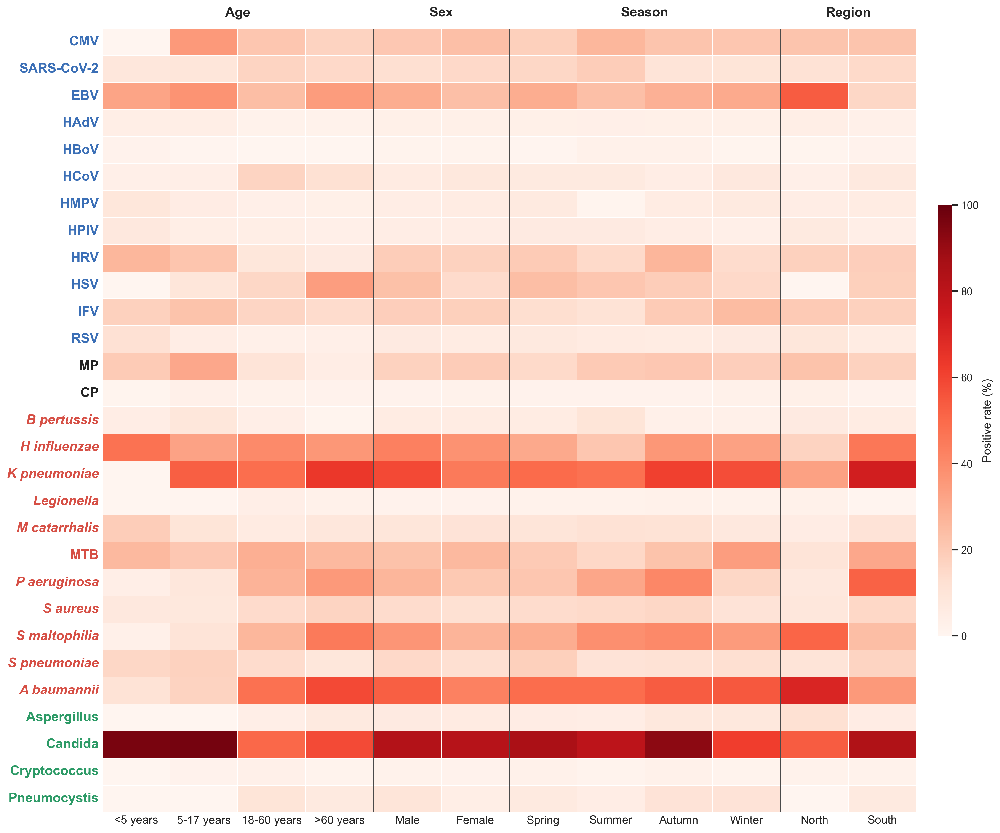

In [471]:
FIG3_HEATMAP_GROUPS = [
    ('Age', figure3_age_table, ['<5 years', '5-17 years', '18-60 years', '>60 years']),
    ('Sex', figure3_sex_table, ['Male', 'Female']),
    ('Season', figure3_season_table, ['Spring', 'Summer', 'Autumn', 'Winter']),
    ('Region', figure3_region_table, ['North', 'South']),
]

def extract_figure3_positive_rate(cell_value):
    if pd.isna(cell_value):
        return np.nan
    text = str(cell_value).strip()
    if not text or '(' not in text:
        return np.nan
    try:
        count_text = text.split('(', 1)[0].strip()
        tested = int(count_text.rsplit('/', 1)[1].replace(',', ''))
        rate = float(text.rsplit('(', 1)[1].replace('%)', '').strip())
        return 0.0 if tested < 100 else rate
    except (IndexError, TypeError, ValueError):
        return np.nan

pathogen_info = (
    pd.concat(
        [table[['Pathogen', 'Pathogen type']] for _, table, _ in FIG3_HEATMAP_GROUPS],
        ignore_index=True,
    )
    .drop_duplicates(subset='Pathogen')
)
pathogen_info['family_rank'] = pathogen_info['Pathogen type'].map(lambda x: FIG3_TYPE_ORDER.get(x, 9))
pathogen_info['pathogen_rank'] = pathogen_info['Pathogen'].map(pathogen_sort_key_for_figure3)
pathogen_info = pathogen_info.sort_values(['family_rank', 'pathogen_rank']).reset_index(drop=True)
pathogen_order = pathogen_info['Pathogen'].tolist()
pathogen_type_map = pathogen_info.set_index('Pathogen')['Pathogen type'].to_dict()

heatmap_parts = []
for group_name, table, strata in FIG3_HEATMAP_GROUPS:
    available_strata = [stratum for stratum in strata if stratum in table.columns]
    part = table.set_index('Pathogen')[available_strata].copy()
    part = part.apply(lambda column: column.map(extract_figure3_positive_rate))
    part.columns = pd.MultiIndex.from_product(
        [[group_name], available_strata],
        names=['Stratification', 'Stratum'],
    )
    heatmap_parts.append(part)

figure3_combined_heatmap = pd.concat(heatmap_parts, axis=1).reindex(pathogen_order)
heatmap_values = figure3_combined_heatmap.copy()
heatmap_values.columns = [f'{group}: {stratum}' for group, stratum in heatmap_values.columns]
heatmap_values.insert(0, 'Pathogen type', heatmap_values.index.map(pathogen_type_map))

missing_mask = figure3_combined_heatmap.isna()
fig_height = max(9.0, 0.34 * len(figure3_combined_heatmap) + 2.5)
fig, ax = plt.subplots(figsize=(14.8, fig_height), dpi=300)
sns.heatmap(
    figure3_combined_heatmap,
    mask=missing_mask,
    cmap='Reds',
    vmin=0,
    vmax=100,
    annot=False,
    linewidths=0.35,
    linecolor='white',
    cbar_kws={
        'label': 'Positive rate (%)',
        'fraction': 0.028,
        'shrink': 0.55,
        'aspect': 30,
        'pad': 0.025,
    },
    ax=ax,
)

for row_idx in range(figure3_combined_heatmap.shape[0]):
    for col_idx in range(figure3_combined_heatmap.shape[1]):
        if missing_mask.iloc[row_idx, col_idx]:
            ax.add_patch(Rectangle(
                (col_idx, row_idx), 1, 1,
                facecolor='#F2F2F2', edgecolor='#D8D8D8',
                hatch='..', linewidth=0.25,
            ))

stratum_labels = [stratum for _, stratum in figure3_combined_heatmap.columns]
ax.set_xticklabels(stratum_labels, rotation=0, ha='center', fontsize=12)
ax.set_yticklabels(pathogen_order, rotation=0, fontsize=14)
for tick_label, pathogen in zip(ax.get_yticklabels(), pathogen_order):
    pathogen_type = pathogen_type_map.get(pathogen, 'Other')
    tick_label.set_color(FIG3_TYPE_COLORS.get(pathogen_type, NATURE_COLORS[6]))
    tick_label.set_fontweight('bold')
    if pathogen in BACTERIA_ITALIC_LABELS:
        tick_label.set_fontstyle('italic')

group_start = 0
for group_name, _, strata in FIG3_HEATMAP_GROUPS:
    group_width = sum(1 for group, _ in figure3_combined_heatmap.columns if group == group_name)
    if group_width == 0:
        continue
    if group_start > 0:
        ax.axvline(group_start, color='#4A4A4A', linewidth=1.2)
    ax.text(
        group_start + group_width / 2, 1.012, group_name,
        transform=ax.get_xaxis_transform(), ha='center', va='bottom',
        fontsize=14, fontweight='bold', clip_on=False,
    )
    group_start += group_width

family_handles = [
    Patch(facecolor=FIG3_TYPE_COLORS[pathogen_type], edgecolor='none', label=pathogen_type)
    for pathogen_type in ['Virus', 'Atypical', 'Bacteria', 'Fungi']
    if pathogen_type in set(pathogen_type_map.values())
]

ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='both', length=0)
fig.tight_layout()
plt.show()


In [472]:
ACTIVE_FIGURE_LABEL = 'Figure_S3'
OUT_DIR = output_dir('Figure_S3')


### Figure_S3 · panel A: age-specific leading pairs


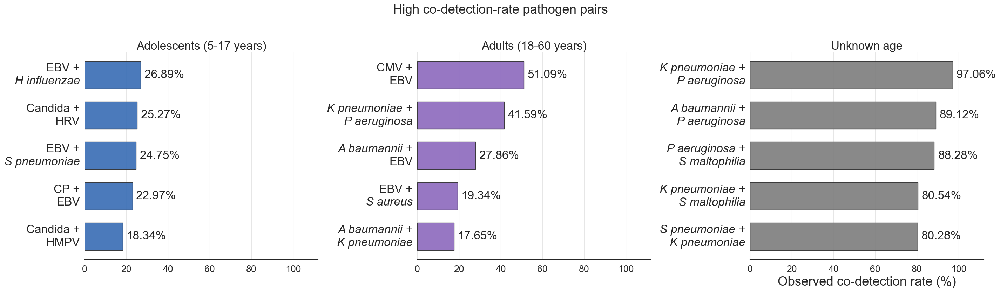

In [473]:
# Top observed co-detection-rate pairs using the same display standard as figure1a.
# Rate = both-positive encounters / encounters in which both pathogens were tested.
# figure1a displays pairs only when total both-tested count is strictly greater than 100.
# Keep PDF text as embedded TrueType text objects for downstream editing.
plt.rcParams.update({
    'font.family': 'Arial',
    'font.sans-serif': ['Arial'],
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})
OBSERVED_MIN_BOTH_TESTED = 100
TOP_COINFECTION_CSV = rel('10_top_coinfections/10_top_coinfection_count.csv')
top_coinfection_df = pd.read_csv(TOP_COINFECTION_CSV)

top_coinfection_df['Coinfection rate (%)'] = pd.to_numeric(
    top_coinfection_df['Coinfection rate (%)'], errors='coerce'
)
top_coinfection_df['Both tested n'] = pd.to_numeric(
    top_coinfection_df['Both tested n'], errors='coerce'
)
top_coinfection_df = top_coinfection_df.loc[
    top_coinfection_df['Both tested n'] > OBSERVED_MIN_BOTH_TESTED
].copy()

# The legacy summary may not yet contain the unknown-age stratum; merge its
# encounter-level summary generated from the same patient-window source.
UNKNOWN_TOP_COINFECTION_CSV = rel('plot_paper/11_unknown_age_top_co_detection_rate.csv')
if (
    not top_coinfection_df['Age section'].eq('Unknown').any()
    and UNKNOWN_TOP_COINFECTION_CSV.exists()
):
    top_coinfection_df = pd.concat([
        top_coinfection_df,
        pd.read_csv(UNKNOWN_TOP_COINFECTION_CSV),
    ], ignore_index=True)

plot_groups = [
    ('Adolescents (5-17 years)', 'Adolescents (5-17 years)', 5, NATURE_COLORS[0]),
    ('Adults (18-60 years)', 'Adults (18-60 years)', 5, NATURE_COLORS[3]),
    ('Unknown', 'Unknown age', 5, NATURE_COLORS[6]),
]

BACTERIAL_PAIR_NAMES = [
    'B pertussis', 'H influenzae', 'K pneumoniae', 'Legionella',
    'M catarrhalis', 'MTB', 'P aeruginosa', 'S aureus',
    'S maltophilia', 'S pneumoniae', 'A baumannii',
]
BACTERIAL_PAIR_REPLACEMENTS = {}
for bacterial_name in BACTERIAL_PAIR_NAMES:
    BACTERIAL_PAIR_REPLACEMENTS[bacterial_name] = bacterial_name
    if ' ' in bacterial_name:
        genus, species = bacterial_name.split(' ', 1)
        BACTERIAL_PAIR_REPLACEMENTS[f'{genus}. {species}'] = bacterial_name
BACTERIAL_PAIR_REPLACEMENTS['M. tuberculosis'] = 'MTB'

def clean_pair_name(pair):
    label = str(pair)
    for old_name, display_name in sorted(BACTERIAL_PAIR_REPLACEMENTS.items(), key=lambda item: len(item[0]), reverse=True):
        label = label.replace(old_name, display_name)
    return ' + '.join(part.strip() for part in label.split('+', 1))

def format_pair_label_with_italic_bacteria(pair):
    pair_parts = clean_pair_name(pair).split(' + ', 1)
    return ' +\n'.join(pair_parts) if len(pair_parts) == 2 else pair_parts[0]

top_coinfection_df['Pair'] = top_coinfection_df['Pair'].map(clean_pair_name)

selected_frames = []
for age_section, display_title, top_n, color in plot_groups:
    selected = (
        top_coinfection_df.loc[
            (top_coinfection_df['Age section'] == age_section)
            & (top_coinfection_df['Panel'] == 'All')
        ]
        .sort_values(['Coinfection rate (%)', 'Coinfection n', 'Pair'], ascending=[False, False, True])
        .head(top_n)
        .copy()
    )
    selected['Group'] = display_title
    selected['Color'] = color
    selected_frames.append(selected)

top_coinfection_plot_df = pd.concat(selected_frames, ignore_index=True)
top_coinfection_plot_df['Pair display'] = top_coinfection_plot_df['Pair'].map(format_pair_label_with_italic_bacteria)
top_coinfection_plot_df['Has bacterial'] = top_coinfection_plot_df['Pair display'].map(
    lambda label: any(name in label for name in BACTERIA_ITALIC_LABELS)
)

fig, axes = plt.subplots(1, 3, figsize=(24, 7), sharex=True, squeeze=False)
axes = axes.ravel()
x_max = max(10, np.ceil(top_coinfection_plot_df['Coinfection rate (%)'].max() / 10) * 10)

for ax, (age_section, display_title, top_n, color) in zip(axes, plot_groups):
    sub = top_coinfection_plot_df.loc[top_coinfection_plot_df['Group'] == display_title].copy()
    sub = sub.sort_values('Coinfection rate (%)', ascending=True).reset_index(drop=True)
    y = np.arange(len(sub))
    bars = ax.barh(
        y, sub['Coinfection rate (%)'], color=color, alpha=0.92,
        edgecolor='#2F2F2F', linewidth=0.8, height=0.68
    )
    ax.set_yticks(y)
    ax.set_yticklabels([])
    for yi, (_, row) in zip(y, sub.iterrows()):
        pair_parts = clean_pair_name(row['Pair']).split(' + ', 1)
        for line_idx, part in enumerate(pair_parts):
            label = f'{part} +' if line_idx == 0 and len(pair_parts) == 2 else part
            ax.text(
                -0.02, yi + (0.16 if line_idx == 0 and len(pair_parts) == 2 else -0.16 if len(pair_parts) == 2 else 0),
                label, transform=ax.get_yaxis_transform(),
                ha='right', va='center', fontsize=20, fontname='Arial',
                fontstyle='italic' if part in BACTERIA_ITALIC_LABELS else 'normal',
                clip_on=False,
            )
    ax.set_xlim(0, x_max * 1.12)
    ax.grid(axis='x', color='#E6E6E6', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.tick_params(axis='x', labelsize=16)
    for tick_label in ax.get_xticklabels():
        tick_label.set_fontname('Arial')
    ax.set_title(display_title, fontsize=20, pad=4, fontname='Arial')
    for bar, (_, row) in zip(bars, sub.iterrows()):
        rate = row['Coinfection rate (%)']
        ax.text(
            rate + x_max * 0.018, bar.get_y() + bar.get_height() / 2,
            f'{rate:.2f}%', va='center', ha='left', fontsize=20, fontname='Arial'
        )

for ax in axes[len(plot_groups):]:
    ax.axis('off')

axes[len(plot_groups) - 1].set_xlabel('Observed co-detection rate (%)', fontsize=22, fontname='Arial')
fig.suptitle('High co-detection-rate pathogen pairs', fontsize=22, y=0.995, fontname='Arial')
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


### Figure_S3 · panels B-E: observed co-detection by strata


In [474]:
# Boxplots from 022_group_rab_boxplots.py outputs: observed coinfection rate influencing factors.
# The plotting/statistical annotation mirrors 022_group_rab_boxplots.py.

GROUP_BOX_DIR = rel('022_group_rab_boxplots')
COMPLETE_POINT_COLOR = '#D64F45'
INCOMPLETE_POINT_COLOR = '#9CA3AF'
STRAT_LABELS = {
    'age': 'Age',
    'sex': 'Sex',
    'season': 'Season',
    'infection_type': 'Infection type',
    'north_south_region': 'Regional distribution',
}
COINFECTION_RATE_LOG2_FLOOR = 1e-4
def metric_display_name(value_col: str) -> str:
    if value_col == 'Observed coinfection rate P(a,b)':
        return 'Observed coinfection rate'
    if value_col == 'log2(Observed coinfection rate P(a,b))':
        return 'log2 observed co-infection rate'
    if value_col == 'Coinfection risk':
        return 'Coinfection risk'
    if value_col == 'log2(Coinfection risk)':
        return 'log2 coinfection risk'
    return value_col


def load_022_summary() -> dict:
    summary_path = GROUP_BOX_DIR / '022_summary.json'
    if not summary_path.exists():
        return {}
    return _json.loads(summary_path.read_text(encoding='utf-8'))


_022_SUMMARY = load_022_summary()


def compute_022_global_test_from_csv(metric_slug: str, strat_key: str) -> dict:
    value_path = GROUP_BOX_DIR / f'022_group_pair_{metric_slug}_{strat_key}.csv'
    if not value_path.exists():
        return {}
    value_df = pd.read_csv(value_path)
    value_col = 'Observed coinfection rate P(a,b)' if metric_slug == 'coinfection_rate' else 'Coinfection risk'
    if value_col not in value_df.columns or 'Pair label' not in value_df.columns or 'Group' not in value_df.columns:
        return {}
    wide_df = value_df.pivot_table(index='Pair label', columns='Group', values=value_col, aggfunc='first')
    groups = list(wide_df.columns)
    complete_df = wide_df[groups].dropna() if len(groups) >= 2 else pd.DataFrame()
    if len(groups) < 2 or complete_df.empty:
        return {}
    if len(groups) == 2:
        statistic, p_value = wilcoxon(complete_df[groups[0]], complete_df[groups[1]])
        method = 'Wilcoxon signed-rank'
    else:
        statistic, p_value = friedmanchisquare(*[complete_df[group].to_numpy(dtype=float) for group in groups])
        method = 'Friedman'
    return {
        'group_count': len(groups),
        'test_method': method,
        'global_statistic': float(statistic),
        'global_p_value': float(p_value),
        'global_p_value_stars': p_stars(p_value),
        'complete_pair_count': len(complete_df),
    }


def load_022_global_test(metric_slug: str, strat_key: str) -> dict:
    summary_test = (
        _022_SUMMARY.get('results', {})
        .get(strat_key, {})
        .get(metric_slug, {})
        .get('global_test', {})
    )
    if pd.notna(summary_test.get('global_p_value', np.nan)):
        return summary_test
    return compute_022_global_test_from_csv(metric_slug, strat_key)


def load_022_metric(metric_slug: str, strat_key: str):
    value_path = GROUP_BOX_DIR / f'022_group_pair_{metric_slug}_{strat_key}.csv'
    stars_path = GROUP_BOX_DIR / f'022_group_pairwise_signedrank_{metric_slug}_{strat_key}_stars_matrix.csv'
    if not value_path.exists():
        raise FileNotFoundError(
            f'Missing {value_path}. Please rerun rti_plot/022_group_rab_boxplots.py after the North/South update.'
        )
    value_df = normalize_pathogen_dataframe(pd.read_csv(value_path))
    if 'Observed coinfection rate P(a,b)' in value_df.columns:
        observed_rate_values = pd.to_numeric(value_df['Observed coinfection rate P(a,b)'], errors='coerce')
        clipped_observed_rate = observed_rate_values.clip(lower=COINFECTION_RATE_LOG2_FLOOR)
        value_df['log2(Observed coinfection rate P(a,b))'] = np.where(
            observed_rate_values.notna(),
            np.log2(clipped_observed_rate),
            np.nan,
        )
    if 'Coinfection risk' in value_df.columns:
        risk_values = pd.to_numeric(value_df['Coinfection risk'], errors='coerce')
        value_df['log2(Coinfection risk)'] = np.where(risk_values > 0, np.log2(risk_values), np.nan)
    stars_df = normalize_pathogen_dataframe(pd.read_csv(stars_path, index_col=0).fillna('')) if stars_path.exists() else pd.DataFrame()
    return value_df, stars_df


### Figure_S3 · shared plotting logic


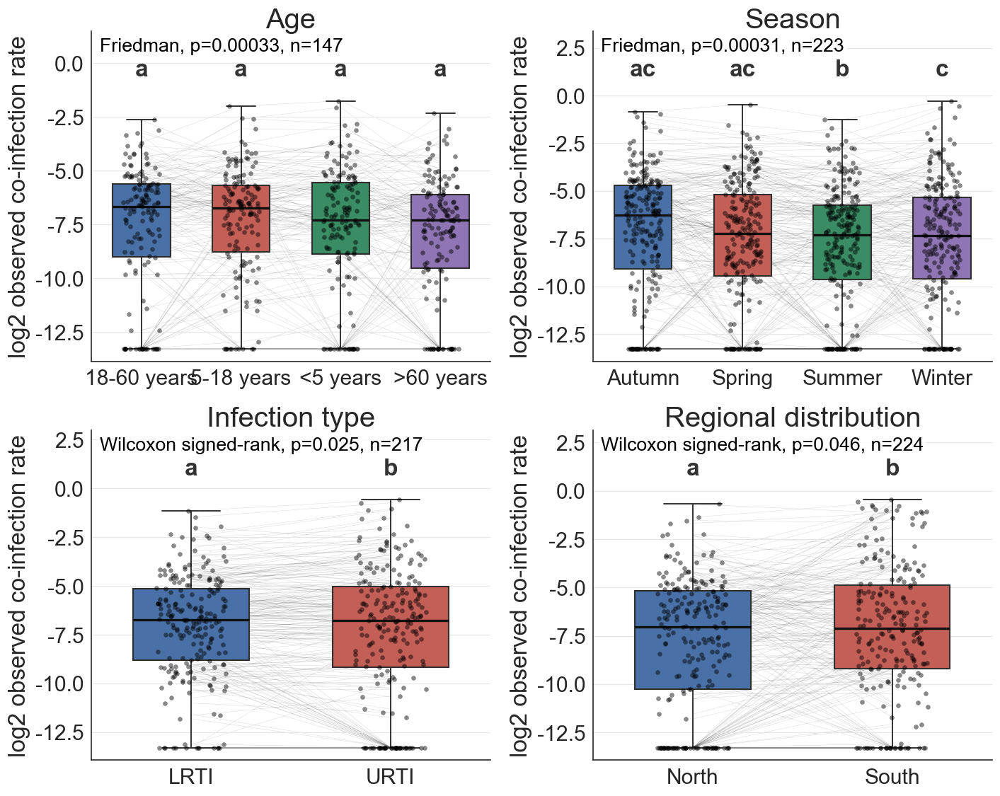

In [475]:
GLOBAL_TEST_ALPHA = 0.05
def plot_022_group_box_shared_significant_on_ax(
    ax,
    value_df: pd.DataFrame,
    stars_df: pd.DataFrame,
    strat_key: str,
    value_col: str,
    global_test=None,
):
    fallback_order = [g for g in value_df['Group'].dropna().drop_duplicates().tolist()]
    value_df = add_complete_across_groups_flag(value_df, fallback_order, value_col)
    shared_df = value_df.loc[value_df['Complete across groups']].copy()
    order = compute_median_sorted_groups(shared_df, fallback_order, value_col)
    letters = build_ordered_significance_letters(shared_df, stars_df, order, value_col)
    palette = {group: NATURE_COLORS[idx % len(NATURE_COLORS)] for idx, group in enumerate(order)}
    
    sns.boxplot(
        data=shared_df,
        x='Group',
        y=value_col,
        order=order,
        palette=palette,
        width=0.58,
        showfliers=False,
        linewidth=1.25,
        boxprops={'edgecolor': '#2F2F2F'},
        whiskerprops={'color': '#2F2F2F', 'linewidth': 1.15},
        capprops={'color': '#2F2F2F', 'linewidth': 1.15},
        medianprops={'color': '#111111', 'linewidth': 2.0},
        ax=ax,
    )

    wide_df = build_group_pair_matrix(shared_df, order, value_col)
    x_positions = {group: idx for idx, group in enumerate(order)}
    for left_group, right_group in zip(order[:-1], order[1:]):
        if left_group not in wide_df.columns or right_group not in wide_df.columns:
            continue
        pair_complete = wide_df[[left_group, right_group]].dropna()
        for _, row in pair_complete.iterrows():
            ax.plot(
                [x_positions[left_group], x_positions[right_group]],
                [row[left_group], row[right_group]],
                color='black',
                linewidth=0.25,
                alpha=0.18,
                zorder=0.5,
            )

    sns.stripplot(
        data=shared_df,
        x='Group',
        y=value_col,
        order=order,
        color='black',
        size=3.6,
        alpha=0.46,
        jitter=0.18,
        edgecolor='black',
        linewidth=0.25,
        ax=ax,
        zorder=2.2,
    )

    ymax = float(np.nanmax(shared_df[value_col]))
    ymin = float(np.nanmin(shared_df[value_col]))
    span = max(ymax - ymin, 0.5)
    y_letter = ymax + 0.08 * span
    for xpos, group in enumerate(order):
        if group in letters:
            ax.text(xpos, y_letter, letters[group], ha='center', va='bottom', fontsize=20, fontweight='bold', color='#333333')
    ax.set_ylim(ymin - 0.05 * span, ymax + 0.28 * span)

    test_label = format_global_test_label(global_test or {})
    if test_label:
        ax.text(
            0.02,
            0.98,
            test_label,
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=16,
            color="#010101",
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.78, 'pad': 2.2},
        )

    ax.set_title(STRAT_LABELS.get(strat_key, strat_key), fontsize=24, pad=3)
    ax.set_xlabel('')
    ax.set_ylabel(metric_display_name(value_col), fontsize=20)
    nature_axes(ax)
    ax.tick_params(axis='x', rotation=0, pad=2, labelsize=18)
    ax.tick_params(axis='y', pad=2, labelsize=18)
    return ax


def plot_022_metric_significant_shared_panels(
    metric_slug: str,
    value_col: str,
    figure_name: str,
    alpha: float = GLOBAL_TEST_ALPHA,
    strat_keys: Optional[list[str]] = None,
):
    significant_items = []
    strat_keys = strat_keys or ['age', 'sex', 'season', 'infection_type', 'north_south_region']
    for strat_key in strat_keys:
        global_test = load_022_global_test(metric_slug, strat_key)
        global_p = global_test.get('global_p_value', np.nan) if global_test else np.nan
        if pd.notna(global_p) and float(global_p) < alpha:
            value_df, stars_df = load_022_metric(metric_slug, strat_key)
            significant_items.append((strat_key, value_df, stars_df, global_test))

    if not significant_items:
        fig, ax = plt.subplots(figsize=(10, 5))
        ax.text(0.5, 0.5, f'No global tests with p < {alpha:g}', ha='center', va='center', fontsize=16)
        ax.axis('off')
        plt.show()
        return pd.DataFrame(columns=['strat_key', 'global_p_value', 'shared_rows'])

    n_panels = len(significant_items)
    ncols = 2 if n_panels > 1 else 1
    nrows = int(np.ceil(n_panels / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False)
    axes_flat = axes.ravel()

    summary_rows = []
    for ax, (strat_key, value_df, stars_df, global_test) in zip(axes_flat, significant_items):
        fallback_order = [g for g in value_df['Group'].dropna().drop_duplicates().tolist()]
        shared_df = add_complete_across_groups_flag(value_df, fallback_order, value_col)
        shared_df = shared_df.loc[shared_df['Complete across groups']].copy()
        summary_rows.append({
            'strat_key': strat_key,
            'global_p_value': global_test.get('global_p_value', np.nan),
            'shared_rows': len(shared_df),
            'shared_pairs': shared_df['Pair label'].nunique() if 'Pair label' in shared_df.columns else np.nan,
        })
        plot_022_group_box_shared_significant_on_ax(
            ax,
            value_df,
            stars_df,
            strat_key,
            value_col,
            global_test=global_test,
        )

    for ax in axes_flat[n_panels:]:
        ax.axis('off')
        
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
    return pd.DataFrame(summary_rows)

coinfection_rate_significant_shared_summary = plot_022_metric_significant_shared_panels(
    metric_slug='coinfection_rate',
    value_col='log2(Observed coinfection rate P(a,b))',
    figure_name='02_coinfection_rate_factors_p_lt_0_05_shared_boxplots',
    strat_keys=['age', 'season', 'infection_type', 'north_south_region'],
)


### Figure_S4 · supplementary clinical outcome panels (A-I)

The supplementary PDF contains the selected comparisons and age-stratified co-detection panels below.


### Figure_S4 · selected clinical comparisons and age-stratified leading pairs

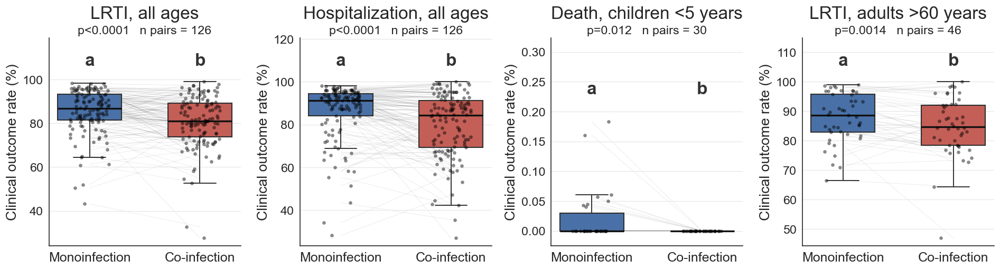

In [476]:
ACTIVE_FIGURE_LABEL = 'Figure_S4'
S4_SELECTED_COMPARISONS = [
    ('All ages', 'LRTI', 'LRTI, all ages'),
    ('All ages', 'Hospitalization', 'Hospitalization, all ages'),
    ('Children (<5 years)', 'Death', 'Death, children <5 years'),
    ('Older adults (>60 years)', 'LRTI', 'LRTI, adults >60 years'),
]
fig, axes = plt.subplots(1, len(S4_SELECTED_COMPARISONS), figsize=(16, 4.5), squeeze=False)
for ax, (age_group, outcome_key, title) in zip(axes[0], S4_SELECTED_COMPARISONS):
    result_df = pairwise_outcomes.loc[pairwise_outcomes['Age group'].eq(age_group)].copy()
    summary_df = pairwise_summary.loc[pairwise_summary['Age group'].eq(age_group)].copy()
    plot_pairwise_outcome_comparison(ax, result_df, summary_df, outcome_key, title=title)
fig.tight_layout()
plt.show()


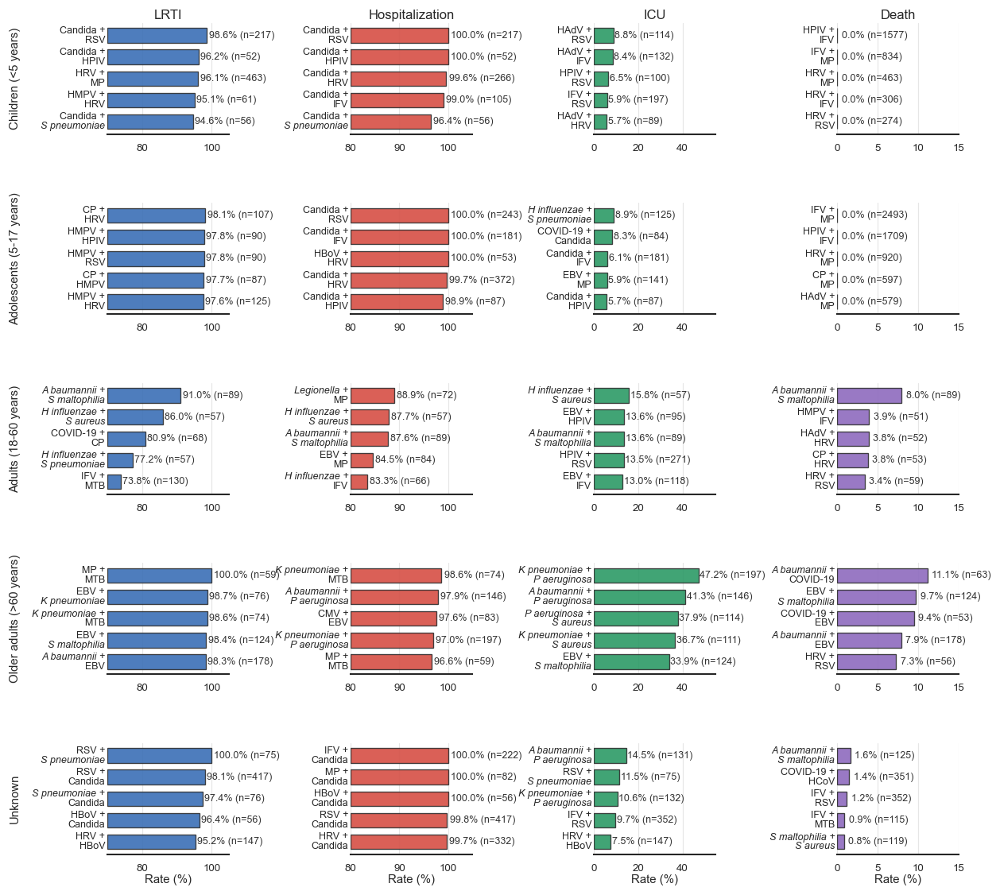

In [477]:
ACTIVE_FIGURE_LABEL = 'Figure_S4'
fig, axes = plt.subplots(
    len(CLINICAL_AGE_ORDER), len(CLINICAL_OUTCOMES),
    figsize=(10.2, 10.5), squeeze=False, sharex=False,
)

for row_idx, age_group in enumerate(CLINICAL_AGE_ORDER):
    for col_idx, (outcome, _, _) in enumerate(CLINICAL_OUTCOMES):
        ax = axes[row_idx, col_idx]
        sub = top_clinical_df.loc[
            (top_clinical_df['Age group'].eq(age_group))
            & top_clinical_df['Outcome'].eq(outcome)
        ].sort_values('Rank', ascending=False)
        y = np.arange(len(sub))
        axis_start, axis_end = CLINICAL_AXIS_LIMITS[outcome]
        bars = ax.barh(
            y, sub['Rate (%)'] - axis_start, left=axis_start,
            color=outcome_colors[outcome], alpha=0.90,
            edgecolor='#2F2F2F', linewidth=0.8, height=0.68,
        )
        ax.set_yticks(y)
        ax.set_yticklabels([])
        for yi, (_, item) in zip(y, sub.iterrows()):
            draw_pair_label(ax, yi, item['Pair'])
        ax.set_xlim(axis_start, axis_end)
        ax.grid(axis='x', color='#E6E6E6', linewidth=0.7)
        ax.set_axisbelow(True)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.tick_params(axis='y', length=0)
        ax.tick_params(axis='x', labelsize=8, pad=1)
        if row_idx == 0:
            ax.set_title(outcome.replace(' rate (%)', ''), fontsize=10, pad=3, fontname='Arial')
        ax.set_ylabel('')
        if row_idx == len(CLINICAL_AGE_ORDER) - 1:
            ax.set_xlabel('Rate (%)', fontsize=9, labelpad=1, fontname='Arial')
        else:
            ax.set_xlabel('')
        for bar, (_, item) in zip(bars, sub.iterrows()):
            ax.text(
                item['Rate (%)'] + 0.55, bar.get_y() + bar.get_height() / 2,
                f"{item['Rate (%)']:.1f}% (n={int(item['Coinfection n'])})",
                va='center', ha='left', fontsize=7.5, color='#333333', fontname='Arial',
            )

fig.subplots_adjust(left=0.12, right=0.995, top=0.93, bottom=0.10, wspace=1.0, hspace=0.62)
for row_idx, age_group in enumerate(CLINICAL_AGE_ORDER):
    position = axes[row_idx, 0].get_position()
    fig.text(0.025, position.y0 + position.height / 2, age_group, rotation=90,
             ha='center', va='center', fontsize=9, fontname='Arial')
plt.show()



In [478]:
ACTIVE_FIGURE_LABEL = 'Figure_S5'
OUT_DIR = output_dir('Figure_S5')


### Figure_S5 · panel A: marginal positivity dependence


eligible RAB pairs: 143
significant Spearman pairs: 84


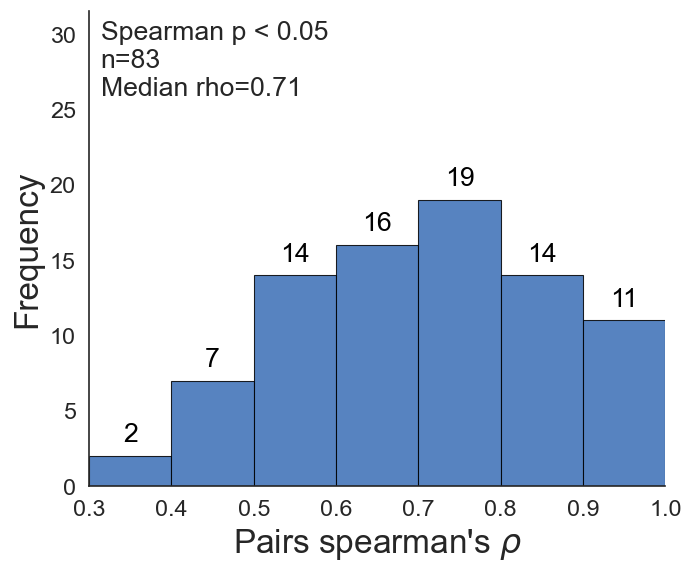

In [479]:
RAB_PAIRWISE_TIME_CSV = rel('02_population_inte/month/all_pathogen_pairwise_time_rates.csv')

RAB_MIN_SINGLE_TESTED = 500
RAB_MIN_BOTH_TESTED = 50
RAB_MIN_FIT_POINTS = 6
RAB_SIGNIFICANCE_ALPHA = 0.05
RAB_RHO_MIN_PLOT = 0.3

pairwise_time_df = normalize_pathogen_dataframe(pd.read_csv(RAB_PAIRWISE_TIME_CSV))
pairwise_time_df['BatchDate'] = pd.to_datetime(pairwise_time_df['BatchDate'], errors='coerce')

rab_time_numeric_cols = ['A tested', 'A positive', 'P(a,t)', 'B tested', 'B positive', 'P(b,t)', 'Both tested', 'Both positive', 'P(a,b,t)', 'P(a,t)*P(b,t)']
for rab_time_col in rab_time_numeric_cols:
    pairwise_time_df[rab_time_col] = pd.to_numeric(pairwise_time_df[rab_time_col], errors='coerce')

pairwise_time_df['pair_key'] = pairwise_time_df.apply(lambda r: tuple(sorted([str(r['Pathogen A']), str(r['Pathogen B'])])), axis=1)

def eligible_rab_time_points(sub):
    eligible_mask = (sub['A tested'] > RAB_MIN_SINGLE_TESTED) & (sub['B tested'] > RAB_MIN_SINGLE_TESTED) & (sub['Both tested'] > RAB_MIN_BOTH_TESTED)
    eligible = sub.loc[eligible_mask].copy()
    valid = eligible.replace([np.inf, -np.inf], np.nan).dropna(subset=['P(a,t)*P(b,t)', 'P(a,b,t)']).copy()
    valid = valid.loc[(valid['P(a,t)*P(b,t)'] >= 0) & (valid['P(a,b,t)'] >= 0)].copy()
    return eligible, valid

def fit_zero_intercept_slope_from_valid(valid):
    x = valid['P(a,t)*P(b,t)'].to_numpy(dtype=float)
    y = valid['P(a,b,t)'].to_numpy(dtype=float)
    denom = float(np.dot(x, x))
    if denom <= 0 or len(x) == 0:
        return np.nan
    return float(np.dot(x, y) / denom)

summary_rows = []
eligible_point_frames = []

for pair_key, sub in pairwise_time_df.groupby('pair_key', sort=True):
    pathogen_a, pathogen_b = pair_key
    sub = sub.sort_values('BatchDate').copy()
    eligible, valid = eligible_rab_time_points(sub)

    rho = np.nan
    p_value = np.nan
    if len(valid) >= RAB_MIN_FIT_POINTS and valid['P(a,t)*P(b,t)'].nunique(dropna=True) > 1 and valid['P(a,b,t)'].nunique(dropna=True) > 1:
        rho, p_value = spearmanr(valid['P(a,t)*P(b,t)'], valid['P(a,b,t)'])

    slope = fit_zero_intercept_slope_from_valid(valid)
    summary_rows.append({'Pathogen A': pathogen_a, 'Pathogen B': pathogen_b, 'pair_label': f'{pathogen_a} vs {pathogen_b}', 'total_time_bins': int(len(sub)), 'eligible_time_bins': int(len(eligible)), 'fit_points': int(len(valid)), 'min_single_tested': RAB_MIN_SINGLE_TESTED, 'min_both_tested': RAB_MIN_BOTH_TESTED, 'min_fit_points': RAB_MIN_FIT_POINTS, 'A_tested_sum': float(sub['A tested'].sum(skipna=True)), 'B_tested_sum': float(sub['B tested'].sum(skipna=True)), 'Both_tested_sum': float(sub['Both tested'].sum(skipna=True)), 'rab_slope_zero_intercept': slope, 'spearman_rho': float(rho) if np.isfinite(rho) else np.nan, 'spearman_p_value': float(p_value) if np.isfinite(p_value) else np.nan, 'spearman_significant': bool(np.isfinite(p_value) and p_value < RAB_SIGNIFICANCE_ALPHA)})

    if not valid.empty:
        tmp = valid.copy()
        tmp['Pathogen A resolved'] = pathogen_a
        tmp['Pathogen B resolved'] = pathogen_b
        tmp['pair_label'] = f'{pathogen_a} vs {pathogen_b}'
        eligible_point_frames.append(tmp)

rab_spearman_summary_df = pd.DataFrame(summary_rows).sort_values(['spearman_p_value', 'pair_label'], na_position='last').reset_index(drop=True)
rab_spearman_points_df = pd.concat(eligible_point_frames, ignore_index=True) if eligible_point_frames else pd.DataFrame()

print('eligible RAB pairs:', int((rab_spearman_summary_df['fit_points'] >= RAB_MIN_FIT_POINTS).sum()))
print('significant Spearman pairs:', int(rab_spearman_summary_df['spearman_significant'].sum()))

# ============================================================
# Spearman rho frequency distribution, p < 0.05 and rho > 0.3 only
# ============================================================
rab_significant_rho_df = rab_spearman_summary_df.loc[
    rab_spearman_summary_df['spearman_rho'].notna()
    & rab_spearman_summary_df['spearman_p_value'].notna()
    & (rab_spearman_summary_df['spearman_p_value'] < RAB_SIGNIFICANCE_ALPHA)
    & (rab_spearman_summary_df['spearman_rho'] > RAB_RHO_MIN_PLOT)
].copy()

rho_values = rab_significant_rho_df['spearman_rho'].to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(6, 5))

if rab_significant_rho_df.empty:
    ax.text(0.5, 0.5, f"No Spearman-significant pathogen pairs\np < {RAB_SIGNIFICANCE_ALPHA:g}, rho > {RAB_RHO_MIN_PLOT:g}", ha='center', va='center', transform=ax.transAxes, fontsize=16)
    ax.set_xlim(RAB_RHO_MIN_PLOT, 1.0)
    ax.set_ylim(0, 31.5)
    ax.set_yticks(np.arange(0, 31, 5))
else:
    bins = np.linspace(RAB_RHO_MIN_PLOT, 1.0, 8)
    median_rho = float(np.nanmedian(rho_values))
    counts, bin_edges, patches = ax.hist(rho_values, bins=bins, color=NATURE_COLORS[0], edgecolor='black', linewidth=0.65, alpha=0.86)

    for count, patch in zip(counts, patches):
        if count > 0:
            x = patch.get_x() + patch.get_width() / 2
            y = patch.get_height()
            ax.text(x, y + 0.6, f'{int(count)}', ha='center', va='bottom', fontsize=16, color='black')

    ax.text(0.02, 0.98, f"Spearman p < {RAB_SIGNIFICANCE_ALPHA:g}\nn={len(rab_significant_rho_df)}\nMedian rho={median_rho:.2f}", transform=ax.transAxes, ha='left', va='top', fontsize=16, bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.80, 'pad': 2.0})
    ax.legend(frameon=False, fontsize=16, loc='upper right')

ax.set_xlim(RAB_RHO_MIN_PLOT, 1.0)
ax.set_ylim(0, 31.5)
ax.set_yticks(np.arange(0, 31, 5))
ax.set_xlabel(r"Pairs spearman's $\rho$", fontsize=20)
ax.set_ylabel('Frequency', fontsize=20)
ax.tick_params(axis='x', labelsize=18, width=1.0, length=4.5)
ax.tick_params(axis='y', labelsize=18, width=1.0, length=4.5)
nature_axes(ax, grid_axis=False)

fig.tight_layout()
plt.show()


In [480]:
ACTIVE_FIGURE_LABEL = 'Figure_S5'
OUT_DIR = output_dir('Figure_S5')


### Figure_S5 · panel B-D: age, season, and regional BACR effects


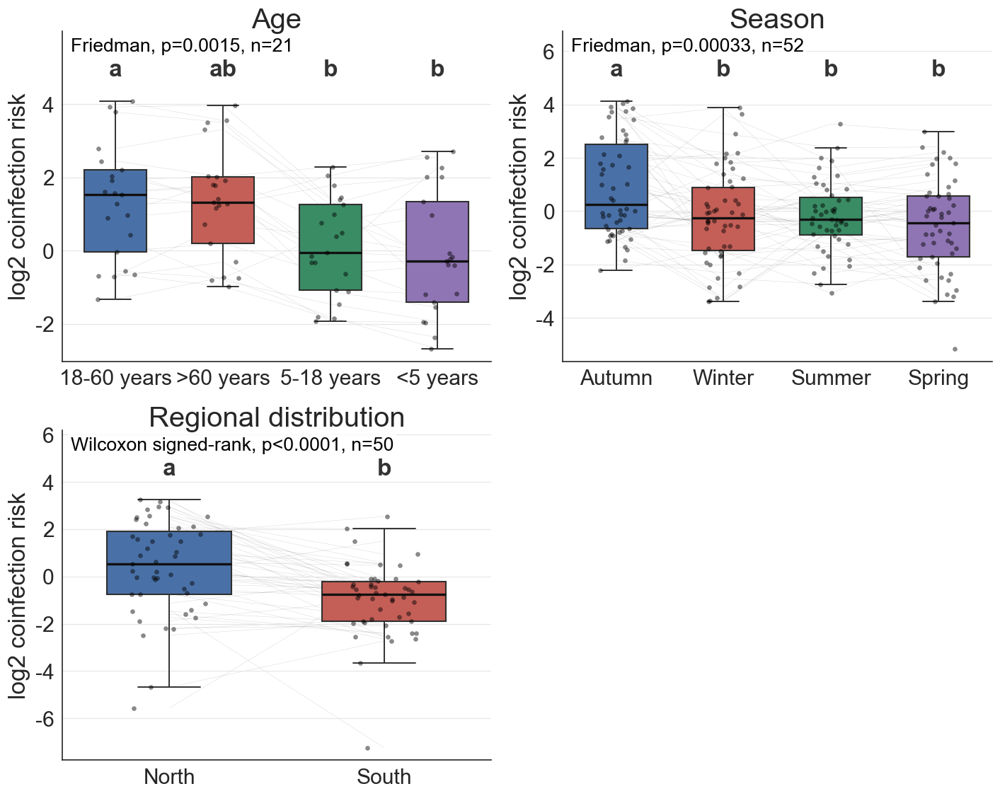

In [481]:
# RAB influencing factors from 022_group_rab_boxplots.py outputs.
# Region is represented by the precomputed North/South stratification.
log2_rab_significant_shared_summary = plot_022_metric_significant_shared_panels(
    metric_slug='rab',
    value_col='log2(Coinfection risk)',
    figure_name='05_log2_rab_influencing_factors_p_lt_0_05_shared_boxplots',
    strat_keys=['age', 'season', 'north_south_region'],
)


In [482]:
ACTIVE_FIGURE_LABEL = 'Figure_S5'
OUT_DIR = output_dir('Figure_S5')


### Figure_S5 · panel E: hospital-panel-balanced BACR heatmap


FDR q < 0.05 significant pairs: 88


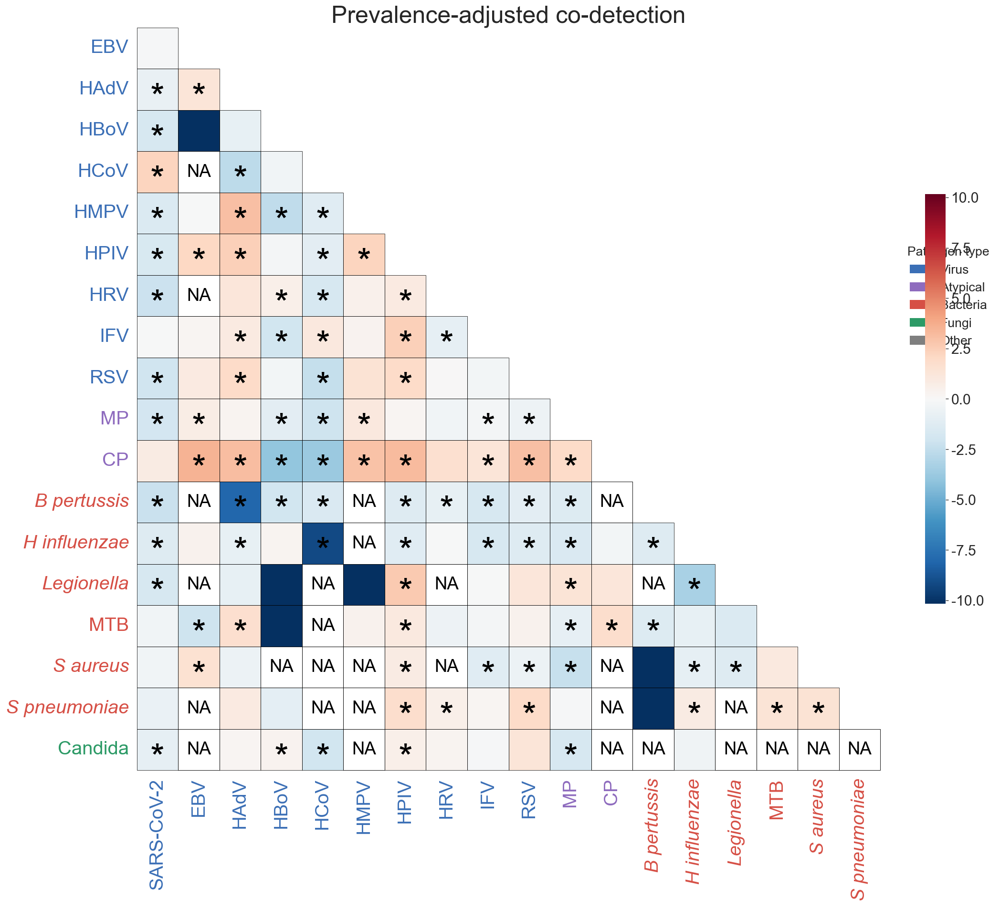

In [483]:
rab_heatmap_pvalue = normalize_pathogen_dataframe(pd.read_csv(rel('bacr_sensitivity/outputs/hospital_panel_balanced_igm_retained/02_rab_coinfection/month/all_pathogen_rab_pvalue_matrix.csv'), index_col=0))
rab_heatmap_matrix = normalize_pathogen_dataframe(pd.read_csv(rel('bacr_sensitivity/outputs/hospital_panel_balanced_igm_retained/02_rab_coinfection/month/all_pathogen_rab_symmetric_matrix.csv'), index_col=0))
rab_common_index = rab_heatmap_matrix.index.intersection(rab_heatmap_pvalue.index)
rab_common_cols = rab_heatmap_matrix.columns.intersection(rab_heatmap_pvalue.columns)
rab_heatmap_matrix = rab_heatmap_matrix.loc[rab_common_index, rab_common_cols]
rab_heatmap_pvalue = rab_heatmap_pvalue.loc[rab_common_index, rab_common_cols]

desired_order = PATHOGEN_DISPLAY_ORDER
bacteria_italic_labels = BACTERIA_ITALIC_LABELS

rab_matrix_float = rab_heatmap_matrix.astype(float).copy()
rab_pvalue_float = rab_heatmap_pvalue.astype(float).copy()

rab_plot_matrix = np.log2(rab_matrix_float.where(rab_matrix_float > 0))
rab_plot_min = np.nanmin(rab_plot_matrix.values)
rab_plot_matrix[rab_matrix_float == 0] = rab_plot_min - 1
rab_plot_matrix = rab_plot_matrix.replace([np.inf, -np.inf], np.nan)

rab_missing_mask = rab_matrix_float.isna() | rab_plot_matrix.isna() | np.isinf(rab_plot_matrix)

rab_initial_upper_triangle_mask = pd.DataFrame(np.triu(np.ones(rab_plot_matrix.shape, dtype=bool), k=0), index=rab_plot_matrix.index, columns=rab_plot_matrix.columns)
rab_initial_lower_triangle_mask = ~rab_initial_upper_triangle_mask

rab_fdr_mask = rab_initial_lower_triangle_mask & rab_pvalue_float.notna()

rab_qvalue_float = pd.DataFrame(np.nan, index=rab_pvalue_float.index, columns=rab_pvalue_float.columns, dtype=float)

rab_fdr_pvalues = rab_pvalue_float.where(rab_fdr_mask).to_numpy(dtype=float)
rab_fdr_valid = np.isfinite(rab_fdr_pvalues)

if rab_fdr_valid.any():
    rab_fdr_qvalues = multipletests(rab_fdr_pvalues[rab_fdr_valid], method='fdr_bh')[1]
    rab_qvalue_values = rab_qvalue_float.to_numpy(dtype=float)
    rab_qvalue_values[rab_fdr_valid] = rab_fdr_qvalues
    rab_qvalue_float = pd.DataFrame(rab_qvalue_values, index=rab_pvalue_float.index, columns=rab_pvalue_float.columns)

# FDR was calculated in one triangle; mirror q values before reordering the pathogens
rab_qvalue_float = rab_qvalue_float.combine_first(rab_qvalue_float.T)

rab_row_has_value = (~rab_missing_mask).any(axis=1)
rab_col_has_value = (~rab_missing_mask).any(axis=0)
rab_all_blank = (~rab_row_has_value) & (~rab_col_has_value)
rab_keep_pathogens = rab_plot_matrix.index[~rab_all_blank]

rab_ordered_pathogens = [p for p in desired_order if p in rab_keep_pathogens]
rab_ordered_pathogens += [p for p in rab_keep_pathogens if p not in rab_ordered_pathogens]

rab_plot_matrix = rab_plot_matrix.loc[rab_ordered_pathogens, rab_ordered_pathogens]
rab_matrix_float = rab_matrix_float.loc[rab_ordered_pathogens, rab_ordered_pathogens]
rab_pvalue_float = rab_pvalue_float.loc[rab_ordered_pathogens, rab_ordered_pathogens]
rab_qvalue_float = rab_qvalue_float.loc[rab_ordered_pathogens, rab_ordered_pathogens]
rab_missing_mask = rab_missing_mask.loc[rab_ordered_pathogens, rab_ordered_pathogens]

rab_all_pathogens = rab_plot_matrix.index.tolist()

rab_row_labels = rab_all_pathogens[1:]
rab_col_labels = rab_all_pathogens[:-1]

rab_plot_matrix = rab_plot_matrix.loc[rab_row_labels, rab_col_labels]
rab_matrix_float = rab_matrix_float.loc[rab_row_labels, rab_col_labels]
rab_pvalue_float = rab_pvalue_float.loc[rab_row_labels, rab_col_labels]
rab_qvalue_float = rab_qvalue_float.loc[rab_row_labels, rab_col_labels]
rab_missing_mask = rab_missing_mask.loc[rab_row_labels, rab_col_labels]

rab_pathogen_pos = pd.Series(np.arange(len(rab_all_pathogens)), index=rab_all_pathogens)
rab_row_pos = rab_pathogen_pos.loc[rab_row_labels].to_numpy()
rab_col_pos = rab_pathogen_pos.loc[rab_col_labels].to_numpy()

rab_lower_triangle_mask = pd.DataFrame(rab_row_pos[:, None] > rab_col_pos[None, :], index=rab_row_labels, columns=rab_col_labels)
rab_non_lower_mask = ~rab_lower_triangle_mask

rab_sig_mask = (
    (rab_qvalue_float < 0.05)
    & rab_lower_triangle_mask
    & (~rab_missing_mask)
).fillna(False)
print(f'FDR q < 0.05 significant pairs: {int(rab_sig_mask.to_numpy().sum())}')

# 屏蔽上三角和缺失值
rab_heatmap_mask = rab_non_lower_mask | rab_missing_mask

rab_finite_vals = rab_plot_matrix.where(rab_lower_triangle_mask & (~rab_missing_mask)).to_numpy(dtype=float)
rab_finite_vals = rab_finite_vals[np.isfinite(rab_finite_vals)]

delta = max(float(np.nanquantile(np.abs(rab_finite_vals),0.99)),0.3) if len(rab_finite_vals) else 0.3

fig_size = max(10,18)
fig, ax = plt.subplots(figsize=(fig_size,fig_size*0.92))
ax.set_facecolor('white')

sns.heatmap(
    rab_plot_matrix,
    mask=rab_heatmap_mask,
    cmap='RdBu_r',
    center=0,
    vmin=-delta,
    vmax=delta,
    linewidths=0,
    linecolor='white',
    square=True,
    cbar_kws={'shrink':0.50,'fraction':0.1,'aspect':20},
    ax=ax
)

style_colorbar(ax.collections[0].colorbar)

for i in range(rab_plot_matrix.shape[0]):
    for j in range(rab_plot_matrix.shape[1]):
        if rab_lower_triangle_mask.iloc[i,j]:
            if rab_missing_mask.iloc[i,j]:
                ax.add_patch(Rectangle((j,i),1,1,facecolor='white',edgecolor='black',linewidth=0.45,zorder=3))
                ax.text(j+0.5,i+0.5,'NA',ha='center',va='center',fontsize=22,color='black',zorder=5)
            elif rab_sig_mask.iloc[i,j]:
                ax.text(j+0.5,i+0.75,'*',ha='center',va='center',fontsize=46,color='black',zorder=5)
            ax.add_patch(Rectangle((j,i),1,1,facecolor='none',edgecolor='black',linewidth=0.45,zorder=4))

margin=0.02
ax.set_xlim(-margin,rab_plot_matrix.shape[1]+margin)
ax.set_ylim(rab_plot_matrix.shape[0]+margin,-margin)
ax.set_title('Prevalence-adjusted co-detection',fontsize=30,pad=5)
ax.set_xlabel('')
ax.set_ylabel('')

plt.setp(ax.get_xticklabels(),rotation=90,ha='center',va='top',fontsize=24)
plt.setp(ax.get_yticklabels(),rotation=0,fontsize=24)

for label in ax.get_xticklabels():
    if label.get_text() in bacteria_italic_labels:
        label.set_fontstyle('italic')
for label in ax.get_yticklabels():
    if label.get_text() in bacteria_italic_labels:
        label.set_fontstyle('italic')

ax.tick_params(axis='x',pad=3)
ax.tick_params(axis='y',pad=3)

figure1b_type_colors = {
    'Virus': NATURE_COLORS[0],
    'Atypical': NATURE_COLORS[3],
    'Bacteria': NATURE_COLORS[1],
    'Fungi': NATURE_COLORS[2],
    'Other': NATURE_COLORS[6],
}

pathogen_label_colors = {pathogen:figure1b_type_colors['Virus'] for pathogen in VIRUS_ORDER}
pathogen_label_colors.update({pathogen:figure1b_type_colors['Atypical'] for pathogen in ['MP','CP']})
pathogen_label_colors.update({pathogen:figure1b_type_colors['Bacteria'] for pathogen in BACTERIA_ORDER if pathogen not in ['MP','CP']})
pathogen_label_colors.update({pathogen:figure1b_type_colors['Fungi'] for pathogen in FUNGI_ORDER})

for label in ax.get_xticklabels():
    label.set_color(pathogen_label_colors.get(label.get_text(),figure1b_type_colors['Other']))
for label in ax.get_yticklabels():
    label.set_color(pathogen_label_colors.get(label.get_text(),figure1b_type_colors['Other']))

ax.legend(
    handles=[Patch(facecolor=color,edgecolor='none',label=pathogen_type) for pathogen_type,color in figure1b_type_colors.items()],
    title='Pathogen type',
    loc='upper left',
    bbox_to_anchor=(1.02,0.72),
    frameon=False,
    fontsize=16,
    title_fontsize=16,
    handlelength=1.6,
)

fig.tight_layout()
plt.show()


### Figure_S6 · independence-only validation


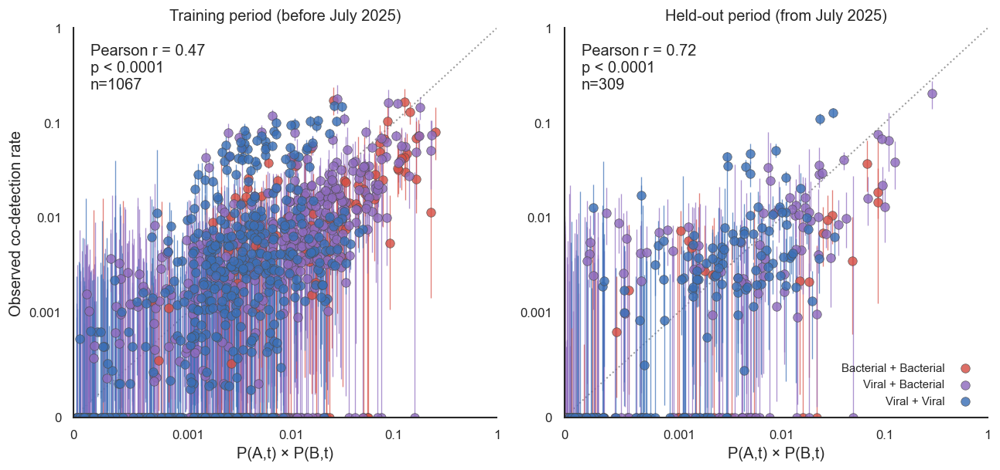

In [484]:
ACTIVE_FIGURE_LABEL = 'Figure_S6'

fig, axes = plt.subplots(1, 2, figsize=(11, 5.3), sharex=False, sharey=False)
for ax, frame, title in [
    (axes[0], train, 'Training period (before July 2025)'),
    (axes[1], test_pairs, 'Held-out period (from July 2025)'),
]:
    valid = frame.dropna(subset=['P(A,t)*P(B,t)', 'Observed coinfection rate qualified'])
    x = valid['P(A,t)*P(B,t)'].to_numpy(dtype=float)
    y = valid['Observed coinfection rate qualified'].to_numpy(dtype=float)
    y_low = valid['Observed CI low'].to_numpy(dtype=float)
    y_high = valid['Observed CI high'].to_numpy(dtype=float)
    for xi, low, high, family in zip(x, y_low, y_high, valid['Pair family']):
        ax.vlines(xi, low, high, color=family_colors.get(family, '#7F7F7F'), alpha=0.72, linewidth=0.8, zorder=1)
    for family, group in valid.groupby('Pair family', sort=False):
        ax.scatter(group['P(A,t)*P(B,t)'], group['Observed coinfection rate qualified'], s=48,
                   color=family_colors.get(family, '#7F7F7F'), edgecolor='#4D4D4D', linewidth=0.45,
                   alpha=0.82, label=family, zorder=2)
    r, p_value = pearsonr(x, y)
    p_label = 'p < 0.0001' if p_value < 0.0001 else f'p={p_value:.2g}'
    ax.text(0.04, 0.96, f'Pearson r = {r:.2f}\n{p_label}\nn={len(valid)}', transform=ax.transAxes,
            ha='left', va='top', fontsize=12)
    ax.plot([0, 1], [0, 1], color='#999999', linestyle=':', linewidth=1.2, zorder=0)
    ax.set_xscale('symlog', linthresh=0.001)
    ax.set_yscale('symlog', linthresh=0.001)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ticks = [0, 0.001, 0.01, 0.1, 1]
    ax.set_xticks(ticks, labels=['0', '0.001', '0.01', '0.1', '1'])
    ax.set_yticks(ticks, labels=['0', '0.001', '0.01', '0.1', '1'])
    ax.set_title(title)
    ax.set_xlabel('P(A,t) × P(B,t)')
    ax.tick_params(axis='both', labelsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
axes[0].set_ylabel('Observed co-detection rate')
handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(handles, labels, frameon=False, loc='lower right', fontsize=9, markerfirst=False)
fig.tight_layout()
plt.show()


### Figure_S7 · age-stratified sequential detection and outcomes

The supplementary PDF contains the additional age strata and all-age clinical panels below.


### Figure_S7 · additional age-stratified sequential detection and all-age clinical outcomes

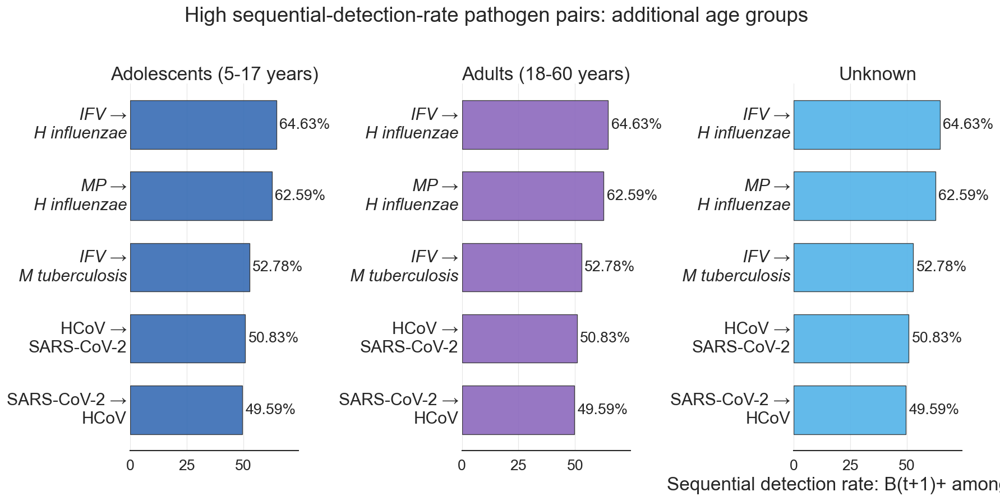

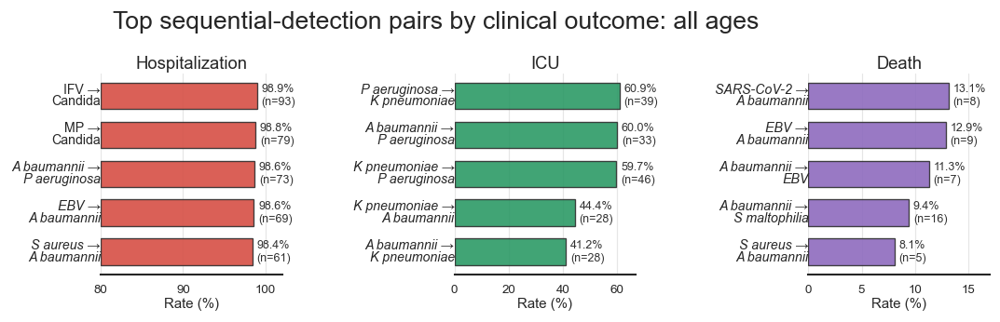

In [485]:
ACTIVE_FIGURE_LABEL = 'Figure_S7'
plot_sequential_rates(
    sequential,
    SUPPLEMENTARY_SEQUENTIAL_GROUPS,
    '08_top_sequential_detection_rate_pairs_supplementary',
    'High sequential-detection-rate pathogen pairs: additional age groups',
    (15, 7.5),
)
plot_all_age_outcome_rates(all_age_outcomes)


In [486]:
ACTIVE_FIGURE_LABEL = 'Figure_S8'
OUT_DIR = output_dir('Figure_S8')


### Figure_S8 · source plot cell 32


Complete sequential-detection matrix: 24 x 24 | significant cells (BH-FDR q < 0.05): 14 | max difference from supplied FDR matrix: 1.19e-15


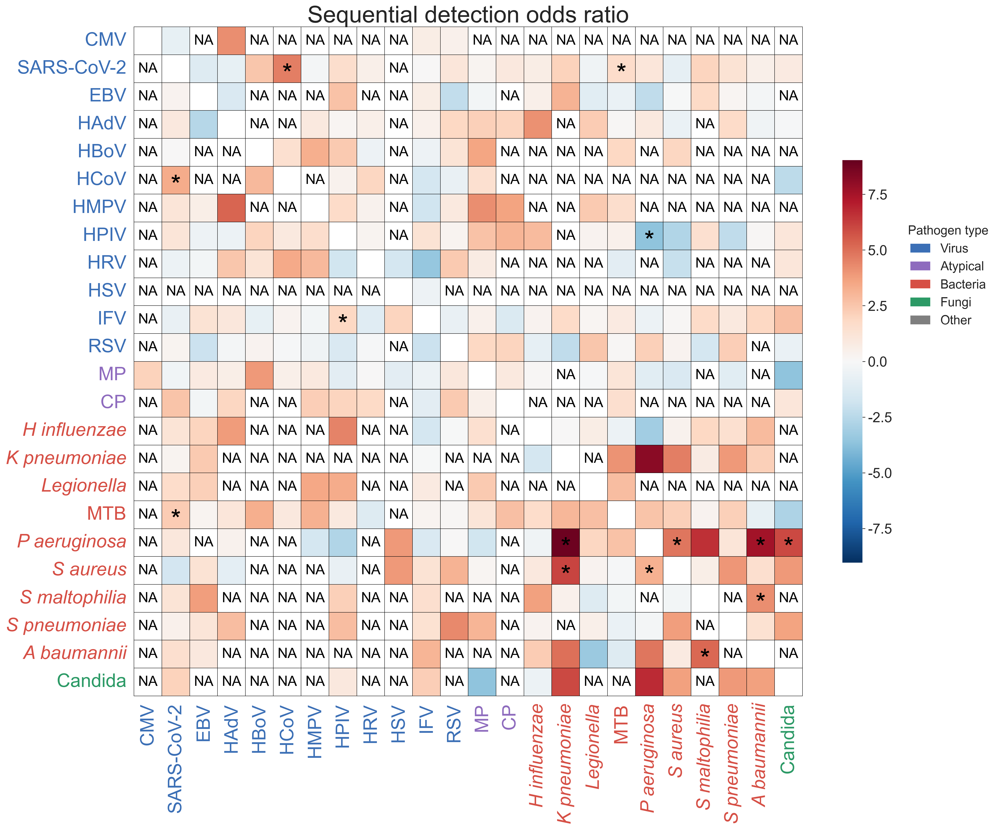

In [487]:
# Sequential detection odds-ratio heatmap: display the complete directional matrix.
or_matrix_df = normalize_pathogen_dataframe(pd.read_csv(rel('sequential_detection/stratified/inpatient_icu/sequential_detection_or_matrix.csv'), index_col=0)).rename(index={'M. tuberculosis': 'MTB'}, columns={'M. tuberculosis': 'MTB'})
pvalue_df = normalize_pathogen_dataframe(pd.read_csv(rel('sequential_detection/stratified/inpatient_icu/sequential_detection_or_pvalue_matrix.csv'), index_col=0)).rename(index={'M. tuberculosis': 'MTB'}, columns={'M. tuberculosis': 'MTB'})
reported_fdr_df = normalize_pathogen_dataframe(pd.read_csv(rel('sequential_detection/stratified/inpatient_icu/sequential_detection_or_fdr_matrix.csv'), index_col=0)).rename(index={'M. tuberculosis': 'MTB'}, columns={'M. tuberculosis': 'MTB'})

common_labels = or_matrix_df.index.intersection(or_matrix_df.columns)
common_labels = common_labels.intersection(pvalue_df.index).intersection(pvalue_df.columns)
common_labels = common_labels.intersection(reported_fdr_df.index).intersection(reported_fdr_df.columns)
or_matrix_df = or_matrix_df.loc[common_labels, common_labels]
pvalue_df = pvalue_df.loc[common_labels, common_labels]
reported_fdr_df = reported_fdr_df.loc[common_labels, common_labels]

desired_order = PATHOGEN_DISPLAY_ORDER
ordered_labels = [p for p in desired_order if p in common_labels]
ordered_labels += [p for p in common_labels if p not in ordered_labels]
or_matrix_float = or_matrix_df.reindex(index=ordered_labels, columns=ordered_labels).apply(pd.to_numeric, errors='coerce')
pvalue_float = pvalue_df.reindex(index=ordered_labels, columns=ordered_labels).apply(pd.to_numeric, errors='coerce')
reported_fdr_float = reported_fdr_df.reindex(index=ordered_labels, columns=ordered_labels).apply(pd.to_numeric, errors='coerce')

or_plot_matrix = np.log2(or_matrix_float.where(or_matrix_float > 0))
or_plot_matrix = or_plot_matrix.replace([np.inf, -np.inf], np.nan)
missing_mask = or_matrix_float.isna() | or_plot_matrix.isna()
diag_mask = pd.DataFrame(np.eye(or_plot_matrix.shape[0], dtype=bool), index=or_plot_matrix.index, columns=or_plot_matrix.columns)

# Recalculate BH-FDR from the raw p-value matrix across every valid cell.
fdr_qvalue_float = pd.DataFrame(np.nan, index=pvalue_float.index, columns=pvalue_float.columns, dtype=float)
fdr_values = pvalue_float.to_numpy(dtype=float)
fdr_valid = np.isfinite(fdr_values)
if fdr_valid.any():
    fdr_qvalues = multipletests(fdr_values[fdr_valid], method='fdr_bh')[1]
    qvalue_values = fdr_qvalue_float.to_numpy(dtype=float)
    qvalue_values[fdr_valid] = fdr_qvalues
    fdr_qvalue_float = pd.DataFrame(qvalue_values, index=pvalue_float.index, columns=pvalue_float.columns)

reported_fdr_values = reported_fdr_float.to_numpy(dtype=float)
fdr_reference_diff = np.nanmax(np.abs(fdr_qvalue_float.to_numpy(dtype=float) - reported_fdr_values))
sig_mask = ((fdr_qvalue_float < 0.05) & (~missing_mask) & (~diag_mask)).fillna(False)
valid_off_diagonal = (~missing_mask) & (~diag_mask)
keep_labels = or_plot_matrix.index[valid_off_diagonal.any(axis=1) & valid_off_diagonal.any(axis=0)]
removed_labels = [label for label in or_plot_matrix.index if label not in set(keep_labels)]
or_plot_matrix = or_plot_matrix.loc[keep_labels, keep_labels]
or_matrix_float = or_matrix_float.loc[keep_labels, keep_labels]
pvalue_float = pvalue_float.loc[keep_labels, keep_labels]
reported_fdr_float = reported_fdr_float.loc[keep_labels, keep_labels]
missing_mask = missing_mask.loc[keep_labels, keep_labels]
fdr_qvalue_float = fdr_qvalue_float.loc[keep_labels, keep_labels]
sig_mask = sig_mask.loc[keep_labels, keep_labels]
diag_mask = pd.DataFrame(np.eye(or_plot_matrix.shape[0], dtype=bool), index=or_plot_matrix.index, columns=or_plot_matrix.columns)
print(
    f'Complete sequential-detection matrix: {or_plot_matrix.shape[0]} x {or_plot_matrix.shape[1]}',
    f'| significant cells (BH-FDR q < 0.05): {int(sig_mask.to_numpy().sum())}',
    f'| max difference from supplied FDR matrix: {fdr_reference_diff:.3g}',
)

heatmap_mask = missing_mask | diag_mask
finite_vals = or_plot_matrix.to_numpy(dtype=float)
finite_vals = finite_vals[np.isfinite(finite_vals)]
delta = max(float(np.nanquantile(np.abs(finite_vals), 0.99)), 0.3) if len(finite_vals) else 0.3

fig_size = max(10, 18)
fig, ax = plt.subplots(figsize=(fig_size, fig_size * 0.92), dpi=300)
ax.set_facecolor('white')

sns.heatmap(
    or_plot_matrix,
    mask=heatmap_mask,
    cmap='RdBu_r',
    center=0,
    vmin=-delta,
    vmax=delta,
    linewidths=0,
    linecolor='white',
    square=True,
    cbar_kws={'shrink':0.50, 'fraction':0.1, 'aspect':20},
    ax=ax,
)

style_colorbar(ax.collections[0].colorbar)

for i in range(or_plot_matrix.shape[0]):
    for j in range(or_plot_matrix.shape[1]):
        if diag_mask.iloc[i, j]:
            ax.add_patch(Rectangle((j, i), 1, 1, facecolor='white', edgecolor='black', linewidth=0.45, zorder=3))
        elif missing_mask.iloc[i, j]:
            ax.add_patch(Rectangle((j, i), 1, 1, facecolor='white', edgecolor='black', linewidth=0.45, zorder=3))
            ax.text(j + 0.5, i + 0.5, 'NA', ha='center', va='center', fontsize=18, color='black', zorder=5)
        elif sig_mask.iloc[i, j]:
            ax.text(j + 0.5, i + 0.75, '*', ha='center', va='center', fontsize=34, color='black', zorder=5)
        ax.add_patch(Rectangle((j, i), 1, 1, facecolor='none', edgecolor='black', linewidth=0.45, zorder=4))

margin = 0.02
ax.set_xlim(-margin, or_plot_matrix.shape[1] + margin)
ax.set_ylim(or_plot_matrix.shape[0] + margin, -margin)
ax.set_title('Sequential detection odds ratio', fontsize=30, pad=5)
ax.set_xlabel('')
ax.set_ylabel('')

plt.setp(ax.get_xticklabels(), rotation=90, ha='center', va='top', fontsize=24)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=24)

for label in ax.get_xticklabels():
    if label.get_text() in BACTERIA_ITALIC_LABELS:
        label.set_fontstyle('italic')
    label.set_color(pathogen_label_colors.get(label.get_text(), figure1a_type_colors['Other']))
for label in ax.get_yticklabels():
    if label.get_text() in BACTERIA_ITALIC_LABELS:
        label.set_fontstyle('italic')
    label.set_color(pathogen_label_colors.get(label.get_text(), figure1a_type_colors['Other']))

ax.tick_params(axis='x', pad=3)
ax.tick_params(axis='y', pad=3)
ax.legend(
    handles=[Patch(facecolor=color, edgecolor='none', label=pathogen_type) for pathogen_type, color in figure1a_type_colors.items()],
    title='Pathogen type',
    loc='upper left',
    bbox_to_anchor=(1.14, 0.72),
    frameon=False,
    fontsize=16,
    title_fontsize=16,
    handlelength=1.6,
)
fig.tight_layout()
plt.show()


In [488]:
ACTIVE_FIGURE_LABEL = 'Figure_S8'
OUT_DIR = output_dir('Figure_S8')


### Figure_S8 · source plot cell 34


Complete sequential-detection matrix: 29 x 29 | significant cells (BH-FDR q < 0.05): 30 | max difference from supplied FDR matrix: 1.08e-15


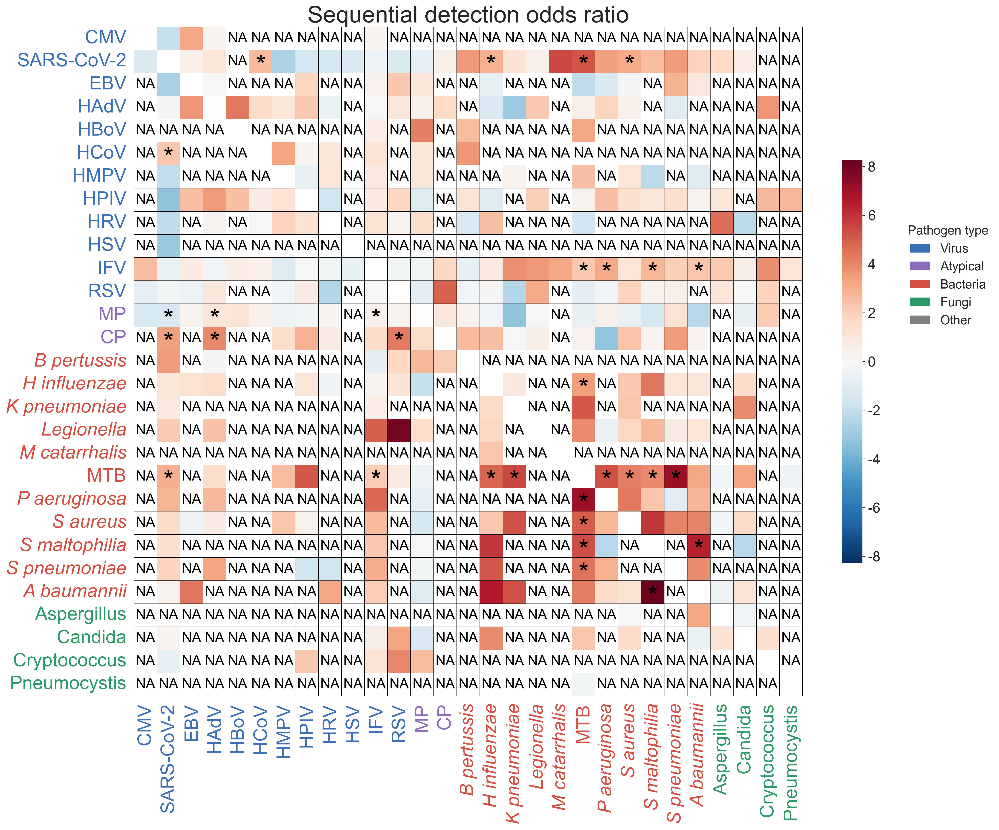

In [489]:
# Sequential detection odds-ratio heatmap: display the complete directional matrix.
or_matrix_df = normalize_pathogen_dataframe(pd.read_csv(rel('sequential_detection/stratified/non_inpatient/sequential_detection_or_matrix.csv'), index_col=0)).rename(index={'M. tuberculosis': 'MTB'}, columns={'M. tuberculosis': 'MTB'})
pvalue_df = normalize_pathogen_dataframe(pd.read_csv(rel('sequential_detection/stratified/non_inpatient/sequential_detection_or_pvalue_matrix.csv'), index_col=0)).rename(index={'M. tuberculosis': 'MTB'}, columns={'M. tuberculosis': 'MTB'})
reported_fdr_df = normalize_pathogen_dataframe(pd.read_csv(rel('sequential_detection/stratified/non_inpatient/sequential_detection_or_fdr_matrix.csv'), index_col=0)).rename(index={'M. tuberculosis': 'MTB'}, columns={'M. tuberculosis': 'MTB'})

common_labels = or_matrix_df.index.intersection(or_matrix_df.columns)
common_labels = common_labels.intersection(pvalue_df.index).intersection(pvalue_df.columns)
common_labels = common_labels.intersection(reported_fdr_df.index).intersection(reported_fdr_df.columns)
or_matrix_df = or_matrix_df.loc[common_labels, common_labels]
pvalue_df = pvalue_df.loc[common_labels, common_labels]
reported_fdr_df = reported_fdr_df.loc[common_labels, common_labels]

desired_order = PATHOGEN_DISPLAY_ORDER
ordered_labels = [p for p in desired_order if p in common_labels]
ordered_labels += [p for p in common_labels if p not in ordered_labels]
or_matrix_float = or_matrix_df.reindex(index=ordered_labels, columns=ordered_labels).apply(pd.to_numeric, errors='coerce')
pvalue_float = pvalue_df.reindex(index=ordered_labels, columns=ordered_labels).apply(pd.to_numeric, errors='coerce')
reported_fdr_float = reported_fdr_df.reindex(index=ordered_labels, columns=ordered_labels).apply(pd.to_numeric, errors='coerce')

or_plot_matrix = np.log2(or_matrix_float.where(or_matrix_float > 0))
or_plot_matrix = or_plot_matrix.replace([np.inf, -np.inf], np.nan)
missing_mask = or_matrix_float.isna() | or_plot_matrix.isna()
diag_mask = pd.DataFrame(np.eye(or_plot_matrix.shape[0], dtype=bool), index=or_plot_matrix.index, columns=or_plot_matrix.columns)

# Recalculate BH-FDR from the raw p-value matrix across every valid cell.
fdr_qvalue_float = pd.DataFrame(np.nan, index=pvalue_float.index, columns=pvalue_float.columns, dtype=float)
fdr_values = pvalue_float.to_numpy(dtype=float)
fdr_valid = np.isfinite(fdr_values)
if fdr_valid.any():
    fdr_qvalues = multipletests(fdr_values[fdr_valid], method='fdr_bh')[1]
    qvalue_values = fdr_qvalue_float.to_numpy(dtype=float)
    qvalue_values[fdr_valid] = fdr_qvalues
    fdr_qvalue_float = pd.DataFrame(qvalue_values, index=pvalue_float.index, columns=pvalue_float.columns)

reported_fdr_values = reported_fdr_float.to_numpy(dtype=float)
fdr_reference_diff = np.nanmax(np.abs(fdr_qvalue_float.to_numpy(dtype=float) - reported_fdr_values))
sig_mask = ((fdr_qvalue_float < 0.05) & (~missing_mask) & (~diag_mask)).fillna(False)
valid_off_diagonal = (~missing_mask) & (~diag_mask)
keep_labels = or_plot_matrix.index[valid_off_diagonal.any(axis=1) & valid_off_diagonal.any(axis=0)]
removed_labels = [label for label in or_plot_matrix.index if label not in set(keep_labels)]
or_plot_matrix = or_plot_matrix.loc[keep_labels, keep_labels]
or_matrix_float = or_matrix_float.loc[keep_labels, keep_labels]
pvalue_float = pvalue_float.loc[keep_labels, keep_labels]
reported_fdr_float = reported_fdr_float.loc[keep_labels, keep_labels]
missing_mask = missing_mask.loc[keep_labels, keep_labels]
fdr_qvalue_float = fdr_qvalue_float.loc[keep_labels, keep_labels]
sig_mask = sig_mask.loc[keep_labels, keep_labels]
diag_mask = pd.DataFrame(np.eye(or_plot_matrix.shape[0], dtype=bool), index=or_plot_matrix.index, columns=or_plot_matrix.columns)
print(
    f'Complete sequential-detection matrix: {or_plot_matrix.shape[0]} x {or_plot_matrix.shape[1]}',
    f'| significant cells (BH-FDR q < 0.05): {int(sig_mask.to_numpy().sum())}',
    f'| max difference from supplied FDR matrix: {fdr_reference_diff:.3g}',
)

heatmap_mask = missing_mask | diag_mask
finite_vals = or_plot_matrix.to_numpy(dtype=float)
finite_vals = finite_vals[np.isfinite(finite_vals)]
delta = max(float(np.nanquantile(np.abs(finite_vals), 0.99)), 0.3) if len(finite_vals) else 0.3

fig_size = max(10, 18)
fig, ax = plt.subplots(figsize=(fig_size, fig_size * 0.92), dpi=300)
ax.set_facecolor('white')

sns.heatmap(
    or_plot_matrix,
    mask=heatmap_mask,
    cmap='RdBu_r',
    center=0,
    vmin=-delta,
    vmax=delta,
    linewidths=0,
    linecolor='white',
    square=True,
    cbar_kws={'shrink':0.50, 'fraction':0.1, 'aspect':20},
    ax=ax,
)

style_colorbar(ax.collections[0].colorbar)

for i in range(or_plot_matrix.shape[0]):
    for j in range(or_plot_matrix.shape[1]):
        if diag_mask.iloc[i, j]:
            ax.add_patch(Rectangle((j, i), 1, 1, facecolor='white', edgecolor='black', linewidth=0.45, zorder=3))
        elif missing_mask.iloc[i, j]:
            ax.add_patch(Rectangle((j, i), 1, 1, facecolor='white', edgecolor='black', linewidth=0.45, zorder=3))
            ax.text(j + 0.5, i + 0.5, 'NA', ha='center', va='center', fontsize=18, color='black', zorder=5)
        elif sig_mask.iloc[i, j]:
            ax.text(j + 0.5, i + 0.75, '*', ha='center', va='center', fontsize=34, color='black', zorder=5)
        ax.add_patch(Rectangle((j, i), 1, 1, facecolor='none', edgecolor='black', linewidth=0.45, zorder=4))

margin = 0.02
ax.set_xlim(-margin, or_plot_matrix.shape[1] + margin)
ax.set_ylim(or_plot_matrix.shape[0] + margin, -margin)
ax.set_title('Sequential detection odds ratio', fontsize=30, pad=5)
ax.set_xlabel('')
ax.set_ylabel('')

plt.setp(ax.get_xticklabels(), rotation=90, ha='center', va='top', fontsize=24)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=24)

for label in ax.get_xticklabels():
    if label.get_text() in BACTERIA_ITALIC_LABELS:
        label.set_fontstyle('italic')
    label.set_color(pathogen_label_colors.get(label.get_text(), figure1a_type_colors['Other']))
for label in ax.get_yticklabels():
    if label.get_text() in BACTERIA_ITALIC_LABELS:
        label.set_fontstyle('italic')
    label.set_color(pathogen_label_colors.get(label.get_text(), figure1a_type_colors['Other']))

ax.tick_params(axis='x', pad=3)
ax.tick_params(axis='y', pad=3)
ax.legend(
    handles=[Patch(facecolor=color, edgecolor='none', label=pathogen_type) for pathogen_type, color in figure1a_type_colors.items()],
    title='Pathogen type',
    loc='upper left',
    bbox_to_anchor=(1.14, 0.72),
    frameon=False,
    fontsize=16,
    title_fontsize=16,
    handlelength=1.6,
)
fig.tight_layout()
plt.show()


### Figure_S9 · age-stratified sequential associations


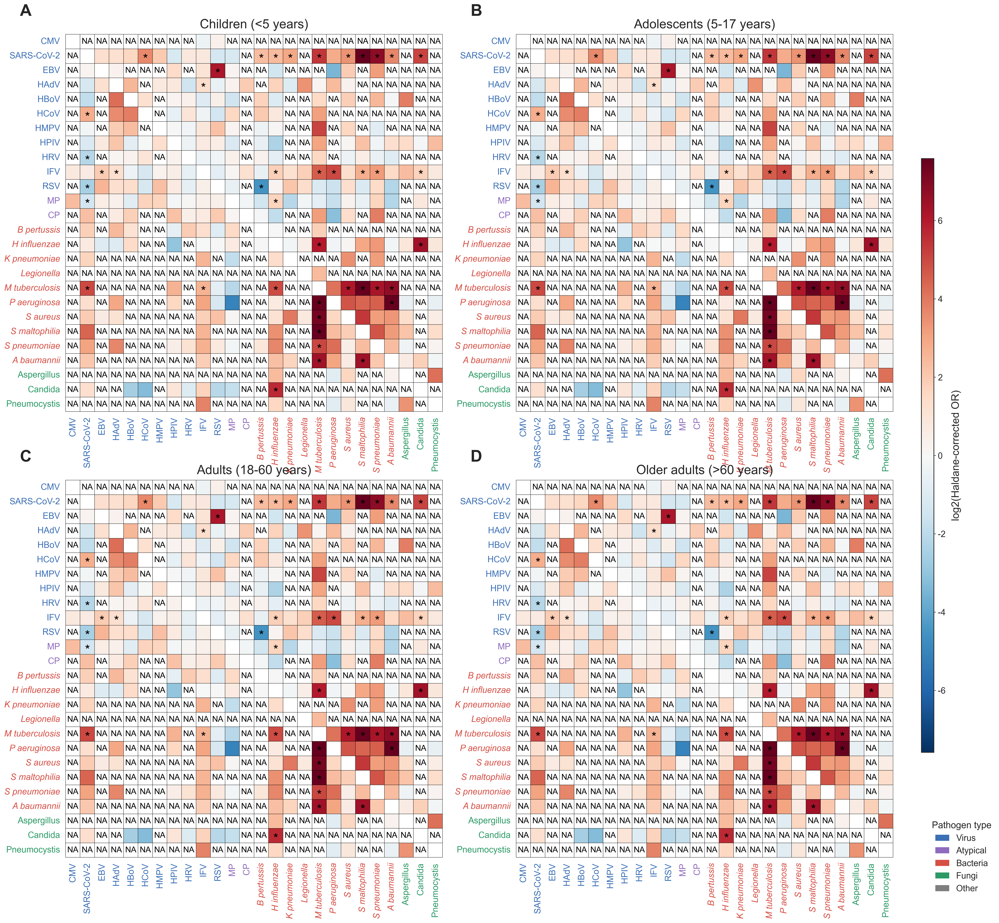

{
  "children_under_5": {
    "age_group": "Children (<5 years)",
    "removed_all_na_pathogens": [
      "HSV",
      "M catarrhalis",
      "Cryptococcus"
    ],
    "valid_off_diagonal_pairs": 340,
    "fdr_significant_pairs": 43
  },
  "adolescents_5_17": {
    "age_group": "Adolescents (5-17 years)",
    "removed_all_na_pathogens": [
      "HSV",
      "M catarrhalis",
      "Cryptococcus"
    ],
    "valid_off_diagonal_pairs": 340,
    "fdr_significant_pairs": 43
  },
  "adults_18_60": {
    "age_group": "Adults (18-60 years)",
    "removed_all_na_pathogens": [
      "HSV",
      "M catarrhalis",
      "Cryptococcus"
    ],
    "valid_off_diagonal_pairs": 340,
    "fdr_significant_pairs": 43
  },
  "older_adults_over_60": {
    "age_group": "Older adults (>60 years)",
    "removed_all_na_pathogens": [
      "HSV",
      "M catarrhalis",
      "Cryptococcus"
    ],
    "valid_off_diagonal_pairs": 340,
    "fdr_significant_pairs": 43
  }
}


In [490]:
matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Liberation Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

OUTPUT_ROOT = BUNDLE_DIR / 'rendered_figures'
SCRIPT_DIR = BundleDirectory('rti_plot_ai/sequential_detection', 'Figure_S9')
AGE_ROOT = BundleDirectory('rti_plot_ai/sequential_detection/age_stratified', 'Figure_S9')
OUTPUT_DIR = output_dir('Figure_S9')
AGE_STRATA = [
    ('children_under_5', 'Children (<5 years)'),
    ('adolescents_5_17', 'Adolescents (5-17 years)'),
    ('adults_18_60', 'Adults (18-60 years)'),
    ('older_adults_over_60', 'Older adults (>60 years)'),
]

VIRUS_ORDER = [
    'CMV', 'SARS-CoV-2', 'EBV', 'HAdV', 'HBoV', 'HCoV', 'HMPV',
    'HPIV', 'HRV', 'HSV', 'IFV', 'RSV',
]
ATYPICAL_ORDER = ['MP', 'CP']
BACTERIA_ORDER = [
    'B pertussis', 'H influenzae', 'K pneumoniae', 'Legionella',
    'M catarrhalis', 'M tuberculosis', 'P aeruginosa', 'S aureus',
    'S maltophilia', 'S pneumoniae', 'A baumannii',
]
FUNGI_ORDER = ['Aspergillus', 'Candida', 'Cryptococcus', 'Pneumocystis']
PATHOGEN_ORDER = VIRUS_ORDER + ATYPICAL_ORDER + BACTERIA_ORDER + FUNGI_ORDER

PATHOGEN_REPLACEMENTS = {
    'COVID-19': 'SARS-CoV-2',
    'SARS-COV-2': 'SARS-CoV-2',
    'B. pertussis': 'B pertussis',
    'H. influenzae': 'H influenzae',
    'K. pneumoniae': 'K pneumoniae',
    'M. catarrhalis': 'M catarrhalis',
    'M. tuberculosis': 'M tuberculosis',
    'P. aeruginosa': 'P aeruginosa',
    'S. aureus': 'S aureus',
    'S. maltophilia': 'S maltophilia',
    'S. pneumoniae': 'S pneumoniae',
    'A. baumannii': 'A baumannii',
}

NATURE_COLORS = ['#3B6FB6', '#D64F45', '#2C9A66', '#8E6BBE', '#E69F00', '#56B4E9', '#7F7F7F']
TYPE_COLORS = {
    'Virus': NATURE_COLORS[0],
    'Atypical': NATURE_COLORS[3],
    'Bacteria': NATURE_COLORS[1],
    'Fungi': NATURE_COLORS[2],
    'Other': NATURE_COLORS[6],
}
LABEL_COLORS = {pathogen: TYPE_COLORS['Virus'] for pathogen in VIRUS_ORDER}
LABEL_COLORS.update({pathogen: TYPE_COLORS['Atypical'] for pathogen in ATYPICAL_ORDER})
LABEL_COLORS.update({pathogen: TYPE_COLORS['Bacteria'] for pathogen in BACTERIA_ORDER})
LABEL_COLORS.update({pathogen: TYPE_COLORS['Fungi'] for pathogen in FUNGI_ORDER})

def normalize_pathogen(value):
    if not isinstance(value, str):
        return value
    for old, new in PATHOGEN_REPLACEMENTS.items():
        value = value.replace(old, new)
    return value

def normalize_matrix(matrix: pd.DataFrame) -> pd.DataFrame:
    matrix = matrix.rename(index=normalize_pathogen, columns=normalize_pathogen)
    return matrix.reindex(index=PATHOGEN_ORDER, columns=PATHOGEN_ORDER)

def load_age_matrix(slug: str) -> tuple[pd.DataFrame, pd.DataFrame, list[str]]:
    age_dir = AGE_ROOT / slug
    or_matrix = pd.read_csv(age_dir / 'sequential_detection_or_matrix.csv', index_col=0)
    fdr_matrix = pd.read_csv(age_dir / 'sequential_detection_or_fdr_matrix.csv', index_col=0)
    or_matrix = normalize_matrix(or_matrix).apply(pd.to_numeric, errors='coerce')
    fdr_matrix = normalize_matrix(fdr_matrix).apply(pd.to_numeric, errors='coerce')

    valid = np.isfinite(or_matrix.to_numpy(dtype=float))
    np.fill_diagonal(valid, False)
    keep = valid.any(axis=1) & valid.any(axis=0)
    keep_labels = or_matrix.index[keep]
    removed_labels = [label for label in or_matrix.index if label not in set(keep_labels)]
    return (
        or_matrix.loc[keep_labels, keep_labels],
        fdr_matrix.loc[keep_labels, keep_labels],
        removed_labels,
    )

def draw_panel(ax, or_matrix: pd.DataFrame, fdr_matrix: pd.DataFrame, title: str, panel_letter: str, delta: float):
    log2_or = np.log2(or_matrix.where(or_matrix > 0)).replace([np.inf, -np.inf], np.nan)
    diagonal_mask = pd.DataFrame(
        np.eye(log2_or.shape[0], dtype=bool),
        index=log2_or.index,
        columns=log2_or.columns,
    )
    missing_mask = or_matrix.isna() | log2_or.isna()
    heatmap_mask = missing_mask | diagonal_mask

    sns.heatmap(
        log2_or,
        mask=heatmap_mask,
        cmap='RdBu_r',
        center=0,
        vmin=-delta,
        vmax=delta,
        linewidths=0,
        linecolor='white',
        square=True,
        cbar=False,
        ax=ax,
    )

    sig_mask = (fdr_matrix < 0.05) & (~missing_mask) & (~diagonal_mask)
    n_significant = int(sig_mask.to_numpy().sum())
    n_valid = int((~missing_mask & ~diagonal_mask).to_numpy().sum())

    for i in range(log2_or.shape[0]):
        for j in range(log2_or.shape[1]):
            if diagonal_mask.iloc[i, j]:
                ax.add_patch(Rectangle(
                    (j, i), 1, 1, facecolor='white', edgecolor='black', linewidth=0.45, zorder=3,
                ))
            elif missing_mask.iloc[i, j]:
                ax.add_patch(Rectangle(
                    (j, i), 1, 1, facecolor='white', edgecolor='black', linewidth=0.45, zorder=3,
                ))
                ax.text(j + 0.5, i + 0.5, 'NA', ha='center', va='center', fontsize=14, color='black', zorder=5)
            elif sig_mask.iloc[i, j]:
                ax.text(j + 0.5, i + 0.75, '*', ha='center', va='center', fontsize=22, color='black', zorder=5)
            ax.add_patch(Rectangle(
                (j, i), 1, 1, facecolor='none', edgecolor='black', linewidth=0.45, zorder=4,
            ))

    margin = 0.02
    ax.set_xlim(-margin, log2_or.shape[1] + margin)
    ax.set_ylim(log2_or.shape[0] + margin, -margin)
    ax.set_title(title, fontsize=22, pad=10)
    ax.text(
        -0.12, 1.04, panel_letter, transform=ax.transAxes,
        ha='left', va='bottom', fontsize=28, fontweight='bold',
    )
    ax.set_xlabel('')
    ax.set_ylabel('')

    plt.setp(ax.get_xticklabels(), rotation=90, ha='center', va='top', fontsize=15)
    plt.setp(ax.get_yticklabels(), rotation=0, fontsize=15)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        name = label.get_text()
        if name in BACTERIA_ORDER:
            label.set_fontstyle('italic')
        label.set_color(LABEL_COLORS.get(name, TYPE_COLORS['Other']))
    ax.tick_params(axis='x', pad=3)
    ax.tick_params(axis='y', pad=3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)
    return n_valid, n_significant

def main():
    sns.set_theme(style='white')
    plt.rcParams.update({
        'font.family': 'Arial',
        'font.size': 14,
        'axes.labelsize': 16,
        'axes.titlesize': 18,
        'xtick.labelsize': 14,
        'ytick.labelsize': 14,
        'figure.dpi': 120,
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
    })

    matrices = {}
    all_values = []
    for slug, title in AGE_STRATA:
        or_matrix, fdr_matrix, removed_labels = load_age_matrix(slug)
        matrices[slug] = (or_matrix, fdr_matrix, title, removed_labels)
        values = np.log2(or_matrix.where(or_matrix > 0)).to_numpy(dtype=float)
        all_values.extend(values[np.isfinite(values)].tolist())

    delta = max(float(np.nanquantile(np.abs(all_values), 0.99)), 0.3) if all_values else 0.3
    fig, axes = plt.subplots(2, 2, figsize=(25, 23), dpi=300)
    axes = axes.ravel()
    summary = {}
    for ax, (slug, (or_matrix, fdr_matrix, title, removed_labels)), panel_letter in zip(
        axes, matrices.items(), 'ABCD',
    ):
        n_valid, n_significant = draw_panel(
            ax, or_matrix, fdr_matrix, title, panel_letter, delta,
        )
        summary[slug] = {
            'age_group': title,
            'removed_all_na_pathogens': removed_labels,
            'valid_off_diagonal_pairs': n_valid,
            'fdr_significant_pairs': n_significant,
        }

    cbar_ax = fig.add_axes([0.925, 0.19, 0.012, 0.62])
    norm = mpl.colors.Normalize(vmin=-delta, vmax=delta)
    cbar = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap='RdBu_r'), cax=cbar_ax)
    cbar.set_label('log2(Haldane-corrected OR)', fontsize=18, labelpad=10)
    cbar.ax.tick_params(labelsize=15, width=0.8, length=3.5)

    handles = [Patch(facecolor=color, edgecolor='none', label=label) for label, color in TYPE_COLORS.items()]
    fig.legend(
        handles=handles,
        title='Pathogen type',
        loc='lower right',
        bbox_to_anchor=(1.0, 0.035),
        frameon=False,
        fontsize=15,
        title_fontsize=16,
        handlelength=1.6,
    )
    fig.subplots_adjust(left=0.09, right=0.91, bottom=0.08, top=0.94, wspace=0.12, hspace=0.18)

    plt.show()
    print(json.dumps(summary, ensure_ascii=False, indent=2))

if __name__ == '__main__':
    main()
